<a href="https://colab.research.google.com/github/uvindu827/J26-DS-350/blob/Indhi_Component2_CHL_Forecast/03_CNN_LSTM_CHL_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

CNN_DIR = (
    BASE_DIR /
    "06_models" /
    "03_CNN_LSTM"
)

EVALUATION_DIR = CNN_DIR / "evaluation"

PREDICTION_DIR = CNN_DIR / "predictions"

CNN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PREDICTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("STEP 31.9P-14 — CNN-LSTM PROJECT SETUP")
print("=" * 70)

print("\nCNN-LSTM directory:")
print(CNN_DIR)

print("\nEvaluation directory:")
print(EVALUATION_DIR)

print("\nPrediction directory:")
print(PREDICTION_DIR)

print("\n✓ CNN-LSTM directories created.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 31.9P-14 — CNN-LSTM PROJECT SETUP

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

Prediction directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/predictions

✓ CNN-LSTM directories created.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ======================================================================
# STEP 31.9P-14A — CNN-LSTM GPU VERIFICATION
# ======================================================================

import tensorflow as tf
import sys
import platform

print("=" * 70)
print("STEP 31.9P-14A — CNN-LSTM GPU VERIFICATION")
print("=" * 70)

print("\nPython version:")
print(sys.version)

print("\nTensorFlow version:")
print(tf.__version__)

print("\nPlatform:")
print(platform.platform())

print("\nGPU devices:")
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    for gpu in gpus:
        print(gpu)

    print("\n✓ GPU detected.")
    print("✓ CNN-LSTM can use GPU acceleration.")

else:
    print("No GPU detected.")
    print("⚠️ Do NOT start training yet.")

STEP 31.9P-14A — CNN-LSTM GPU VERIFICATION

Python version:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

TensorFlow version:
2.21.0

Platform:
Linux-6.6.122+-x86_64-with-glibc2.39

GPU devices:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

✓ GPU detected.
✓ CNN-LSTM can use GPU acceleration.


In [ ]:
# ======================================================================
# STEP 31.9P-14A — CNN-LSTM ENVIRONMENT + GPU VERIFICATION
# ======================================================================

import sys
import platform
import os

print("=" * 70)
print("STEP 31.9P-14A — CNN-LSTM ENVIRONMENT + GPU VERIFICATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PYTHON / PLATFORM
# ----------------------------------------------------------------------

print("\nPython version:")
print(sys.version)

print("\nPlatform:")
print(platform.platform())

print("\nCUDA_VISIBLE_DEVICES:")
print(os.environ.get("CUDA_VISIBLE_DEVICES"))

# ----------------------------------------------------------------------
# TENSORFLOW VERIFICATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TENSORFLOW VERIFICATION")
print("=" * 70)

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)

    gpus = tf.config.list_physical_devices("GPU")

    print("Number of GPUs detected:", len(gpus))

    if gpus:
        print("\nGPU devices:")
        for gpu in gpus:
            print(gpu)

        print("\n✓ TensorFlow GPU detected.")
    else:
        print("\n⚠ No GPU detected by TensorFlow.")

except Exception as e:
    print("\nTensorFlow GPU verification failed:")
    print(e)

# ----------------------------------------------------------------------
# CUDA BUILD INFORMATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TENSORFLOW BUILD INFORMATION")
print("=" * 70)

try:
    print("Built with CUDA:",
          tf.test.is_built_with_cuda())

    print("GPU available:",
          len(tf.config.list_physical_devices("GPU")) > 0)

except Exception as e:
    print("Could not retrieve CUDA build information:")
    print(e)

# ----------------------------------------------------------------------
# SIMPLE GPU COMPUTATION TEST
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU COMPUTATION TEST")
print("=" * 70)

try:
    if gpus:
        with tf.device("/GPU:0"):
            test_a = tf.random.normal((2000, 2000))
            test_b = tf.random.normal((2000, 2000))
            test_c = tf.matmul(test_a, test_b)

        print("GPU matrix multiplication completed.")
        print("Result shape:", test_c.shape)

        # Force computation completion
        _ = test_c.numpy()

        print("✓ GPU computation test successful.")

    else:
        print("GPU computation test skipped because no GPU was detected.")

except Exception as e:
    print("GPU computation test failed:")
    print(e)

print("\n" + "=" * 70)
print("STEP 31.9P-14A COMPLETE")
print("=" * 70)

STEP 31.9P-14A — CNN-LSTM ENVIRONMENT + GPU VERIFICATION

Python version:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

Platform:
Linux-6.6.122+-x86_64-with-glibc2.39

CUDA_VISIBLE_DEVICES:
None

TENSORFLOW VERIFICATION
TensorFlow version: 2.21.0
Number of GPUs detected: 1

GPU devices:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

✓ TensorFlow GPU detected.

TENSORFLOW BUILD INFORMATION
Built with CUDA: True
GPU available: True

GPU COMPUTATION TEST
GPU matrix multiplication completed.
Result shape: (2000, 2000)
✓ GPU computation test successful.

STEP 31.9P-14A COMPLETE


In [ ]:
# ======================================================================
# STEP 31.9P-14B — CNN-LSTM DATA LOADING & VERIFICATION
# ======================================================================

import os
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 70)
print("STEP 31.9P-14B — CNN-LSTM DATA LOADING & VERIFICATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PROJECT DIRECTORIES
# ----------------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

PREPROCESS_DIR = (
    BASE_DIR /
    "05_model_preprocessing"
)

MODEL_DIR = (
    BASE_DIR /
    "06_models" /
    "03_CNN_LSTM"
)

EVALUATION_DIR = MODEL_DIR / "evaluation"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nProject directory:")
print(BASE_DIR)

print("\nPreprocessing directory:")
print(PREPROCESS_DIR)

print("\nCNN-LSTM model directory:")
print(MODEL_DIR)

print("\nEvaluation directory:")
print(EVALUATION_DIR)

# ----------------------------------------------------------------------
# FILE PATHS
# ----------------------------------------------------------------------

TRAIN_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_train.csv"
)

VALIDATION_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_validation.csv"
)

TEST_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_test.csv"
)

FEATURE_FILE = (
    PREPROCESS_DIR /
    "final_model_feature_columns.csv"
)

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Training dataset": TRAIN_FILE,
    "Validation dataset": VALIDATION_FILE,
    "Test dataset": TEST_FILE,
    "Feature list": FEATURE_FILE
}

for name, path in required_files.items():
    print(f"\n{name}:")
    print(path)
    print("Exists:", path.exists())

    assert path.exists(), f"Missing required file: {path}"

print("\n✓ All required files found.")

# ----------------------------------------------------------------------
# LOAD DATA
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING MODEL-READY DATA")
print("=" * 70)

print("\nLoading training data...")
train_df = pd.read_csv(TRAIN_FILE)

print("Loading validation data...")
validation_df = pd.read_csv(VALIDATION_FILE)

print("Loading test data...")
test_df = pd.read_csv(TEST_FILE)

print("Loading final feature list...")
feature_df = pd.read_csv(FEATURE_FILE)

print("\n" + "=" * 70)
print("DATASET SHAPES")
print("=" * 70)

print("\nTraining:")
print(train_df.shape)

print("\nValidation:")
print(validation_df.shape)

print("\nTest:")
print(test_df.shape)

# ----------------------------------------------------------------------
# FINAL FEATURE LIST
# ----------------------------------------------------------------------

FEATURES = (
    feature_df["feature"]
    .dropna()
    .astype(str)
    .tolist()
)

FEATURES = list(dict.fromkeys(FEATURES))

print("\n" + "=" * 70)
print("FINAL FEATURE CONFIGURATION")
print("=" * 70)

print("\nNumber of selected features:")
print(len(FEATURES))

assert len(FEATURES) == 69

print("\n✓ Exactly 69 final predictors loaded.")

# ----------------------------------------------------------------------
# TARGET CONFIGURATION
# ----------------------------------------------------------------------

TARGET_LOG = "chlorophyll_a_log1p"
TARGET_ORIGINAL = "chlorophyll_a"

print("\n" + "=" * 70)
print("TARGET CONFIGURATION")
print("=" * 70)

print("\nLog target:")
print(TARGET_LOG)

print("\nOriginal target:")
print(TARGET_ORIGINAL)

# ----------------------------------------------------------------------
# FEATURE EXISTENCE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE EXISTENCE CHECK")
print("=" * 70)

for dataset_name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    missing_features = [
        feature for feature in FEATURES
        if feature not in df.columns
    ]

    print(f"\n{dataset_name} missing features:")
    print(len(missing_features))

    assert len(missing_features) == 0

    print(f"✓ All 69 features available in {dataset_name}.")

# ----------------------------------------------------------------------
# TARGET EXISTENCE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET EXISTENCE CHECK")
print("=" * 70)

for dataset_name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    assert TARGET_LOG in df.columns
    assert TARGET_ORIGINAL in df.columns

    print(f"\n✓ {dataset_name}: both target representations available.")

# ----------------------------------------------------------------------
# METADATA CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("METADATA CHECK")
print("=" * 70)

METADATA_COLUMNS = [
    "date",
    "latitude",
    "longitude",
    "data_split"
]

for dataset_name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    missing_metadata = [
        col for col in METADATA_COLUMNS
        if col not in df.columns
    ]

    print(f"\n{dataset_name} missing metadata columns:")
    print(missing_metadata)

    assert len(missing_metadata) == 0

print("\n✓ Required metadata columns available.")

# ----------------------------------------------------------------------
# MISSING VALUE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)

for dataset_name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    predictor_missing = df[FEATURES].isna().sum().sum()
    log_target_missing = df[TARGET_LOG].isna().sum()
    original_target_missing = df[TARGET_ORIGINAL].isna().sum()

    print(f"\n{dataset_name}:")
    print("Predictor missing values:", predictor_missing)
    print("Log target missing values:", log_target_missing)
    print("Original target missing values:", original_target_missing)

    assert predictor_missing == 0
    assert log_target_missing == 0
    assert original_target_missing == 0

print("\n✓ No missing predictor or target values.")

# ----------------------------------------------------------------------
# INFINITE VALUE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("INFINITE VALUE CHECK")
print("=" * 70)

for dataset_name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    infinite_count = np.isinf(
        df[FEATURES].to_numpy(dtype=np.float64)
    ).sum()

    print(f"\n{dataset_name} infinite predictor values:")
    print(infinite_count)

    assert infinite_count == 0

print("\n✓ No infinite predictor values.")

# ----------------------------------------------------------------------
# TARGET LEAKAGE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET LEAKAGE CHECK")
print("=" * 70)

print("\nLog target included as predictor:")
print(TARGET_LOG in FEATURES)

print("Original CHL included as predictor:")
print(TARGET_ORIGINAL in FEATURES)

assert TARGET_LOG not in FEATURES
assert TARGET_ORIGINAL not in FEATURES

print("\n✓ No target leakage detected.")

# ----------------------------------------------------------------------
# DATE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("DATE VERIFICATION")
print("=" * 70)

for dataset_name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    date_series = pd.to_datetime(df["date"])

    print(f"\n{dataset_name}:")
    print("Minimum date:", date_series.min())
    print("Maximum date:", date_series.max())
    print("Chronologically ordered:",
          date_series.is_monotonic_increasing)

    assert date_series.is_monotonic_increasing

print("\n✓ All datasets are chronologically ordered.")

# ----------------------------------------------------------------------
# DATA SPLIT OVERLAP CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA SPLIT OVERLAP CHECK")
print("=" * 70)

train_dates = set(train_df["date"].astype(str))
validation_dates = set(validation_df["date"].astype(str))
test_dates = set(test_df["date"].astype(str))

train_validation_overlap = len(
    train_dates.intersection(validation_dates)
)

validation_test_overlap = len(
    validation_dates.intersection(test_dates)
)

train_test_overlap = len(
    train_dates.intersection(test_dates)
)

print("\nTrain ∩ Validation:")
print(train_validation_overlap)

print("Validation ∩ Test:")
print(validation_test_overlap)

print("Train ∩ Test:")
print(train_test_overlap)

assert train_validation_overlap == 0
assert validation_test_overlap == 0
assert train_test_overlap == 0

print("\n✓ No date overlap between datasets.")

# ----------------------------------------------------------------------
# SPATIAL CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SPATIAL INFORMATION CHECK")
print("=" * 70)

for dataset_name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    print(f"\n{dataset_name}:")
    print("Latitude range:",
          df["latitude"].min(),
          "to",
          df["latitude"].max())

    print("Longitude range:",
          df["longitude"].min(),
          "to",
          df["longitude"].max())

print("\n✓ Spatial information preserved.")

# ----------------------------------------------------------------------
# FINAL SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 31.9P-14B SUMMARY")
print("=" * 70)

print("\nTraining rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

print("\nSelected predictors:", len(FEATURES))

print("\nLog target:", TARGET_LOG)
print("Original target:", TARGET_ORIGINAL)

print("\n✓ Same 69-feature configuration preserved.")
print("✓ Original and log CHL targets preserved.")
print("✓ No missing predictor values.")
print("✓ No infinite predictor values.")
print("✓ No target leakage.")
print("✓ Chronological ordering preserved.")
print("✓ No date overlap between splits.")
print("✓ Spatial information preserved.")
print("✓ Test data has NOT been used for modelling decisions.")

print("\n" + "=" * 70)
print("STEP 31.9P-14B COMPLETE")
print("=" * 70)

STEP 31.9P-14B — CNN-LSTM DATA LOADING & VERIFICATION
Mounted at /content/drive

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

Preprocessing directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing

CNN-LSTM model directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

REQUIRED FILE CHECK

Training dataset:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_ready_train.csv
Exists: True

Validation dataset:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_ready_validation.csv
Exists: True

Test dataset:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_ready_test.csv
Exists: True

Feature list:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_feature_columns.csv
Exis

In [ ]:
# ======================================================================
# STEP 31.9P-14C
# CNN-LSTM TEMPORAL SEQUENCE DESIGN & CONTINUITY ANALYSIS
# ======================================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 70)
print("STEP 31.9P-14C — CNN-LSTM SEQUENCE DESIGN")
print("TEMPORAL SEQUENCE & CONTINUITY ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------------------
# PROJECT PATHS
# ----------------------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

PREPROCESS_DIR = (
    BASE_DIR /
    "05_model_preprocessing"
)

MODEL_DIR = (
    BASE_DIR /
    "06_models" /
    "03_CNN_LSTM"
)

EVALUATION_DIR = MODEL_DIR / "evaluation"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ----------------------------------------------------------------------
# FILES
# ----------------------------------------------------------------------

TRAIN_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_train.csv"
)

VALIDATION_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_validation.csv"
)

TEST_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_test.csv"
)

# ----------------------------------------------------------------------
# LOAD DATA
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING DATA")
print("=" * 70)

print("\nLoading training data...")
train_df = pd.read_csv(TRAIN_FILE)

print("Loading validation data...")
validation_df = pd.read_csv(VALIDATION_FILE)

print("Loading test data...")
test_df = pd.read_csv(TEST_FILE)

print("\n✓ All datasets loaded.")

# ----------------------------------------------------------------------
# DATE CONVERSION
# ----------------------------------------------------------------------

for df in [train_df, validation_df, test_df]:
    df["date"] = pd.to_datetime(df["date"])

# ----------------------------------------------------------------------
# BASIC TEMPORAL STRUCTURE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("1. BASIC TEMPORAL STRUCTURE")
print("=" * 70)

all_dates = pd.concat(
    [
        train_df[["date", "latitude", "longitude"]],
        validation_df[["date", "latitude", "longitude"]],
        test_df[["date", "latitude", "longitude"]]
    ],
    ignore_index=True
)

print("\nTotal rows across all splits:")
print(len(all_dates))

print("\nUnique dates:")
print(all_dates["date"].nunique())

print("\nMinimum date:")
print(all_dates["date"].min())

print("\nMaximum date:")
print(all_dates["date"].max())

# ----------------------------------------------------------------------
# SPATIAL LOCATIONS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("2. SPATIAL LOCATION STRUCTURE")
print("=" * 70)

all_locations = (
    all_dates[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .sort_values(
        ["latitude", "longitude"]
    )
    .reset_index(drop=True)
)

print("\nUnique spatial locations:")
print(len(all_locations))

print("\nFirst 10 spatial locations:")
print(all_locations.head(10).to_string(index=False))

# ----------------------------------------------------------------------
# OBSERVATIONS PER LOCATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("3. OBSERVATIONS PER SPATIAL LOCATION")
print("=" * 70)

location_counts = (
    all_dates
    .groupby(
        ["latitude", "longitude"]
    )
    .size()
    .reset_index(
        name="observations"
    )
)

print("\nObservation count summary:")
print(
    location_counts["observations"]
    .describe()
)

print("\nMinimum observations at one location:")
print(location_counts["observations"].min())

print("Maximum observations at one location:")
print(location_counts["observations"].max())

print("Median observations per location:")
print(location_counts["observations"].median())

# ----------------------------------------------------------------------
# DATE COVERAGE PER LOCATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("4. DATE COVERAGE PER LOCATION")
print("=" * 70)

location_date_summary = (
    all_dates
    .groupby(
        ["latitude", "longitude"]
    )
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        unique_dates=("date", "nunique")
    )
    .reset_index()
)

print(
    "\nDate coverage summary:"
)

print(
    location_date_summary[
        ["unique_dates"]
    ].describe()
)

# ----------------------------------------------------------------------
# DAILY CONTINUITY ANALYSIS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("5. DAILY TEMPORAL CONTINUITY")
print("=" * 70)

continuity_records = []

for (lat, lon), group in all_dates.groupby(
    ["latitude", "longitude"]
):

    dates = (
        group["date"]
        .drop_duplicates()
        .sort_values()
    )

    if len(dates) < 2:
        continue

    gaps = (
        dates
        .diff()
        .dt.days
        .dropna()
    )

    continuity_records.append(
        {
            "latitude": lat,
            "longitude": lon,
            "number_of_dates": len(dates),
            "minimum_gap_days": gaps.min(),
            "maximum_gap_days": gaps.max(),
            "median_gap_days": gaps.median(),
            "mean_gap_days": gaps.mean(),
            "one_day_gap_count": (gaps == 1).sum(),
            "gap_greater_than_1_count": (gaps > 1).sum()
        }
    )

continuity_df = pd.DataFrame(
    continuity_records
)

print("\nContinuity summary:")
print(
    continuity_df[
        [
            "number_of_dates",
            "minimum_gap_days",
            "maximum_gap_days",
            "median_gap_days",
            "mean_gap_days",
            "one_day_gap_count",
            "gap_greater_than_1_count"
        ]
    ].describe()
)

# ----------------------------------------------------------------------
# DAILY GAP PROPORTION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("6. DAILY GAP PROPORTION")
print("=" * 70)

total_consecutive_intervals = (
    continuity_df["one_day_gap_count"]
    +
    continuity_df["gap_greater_than_1_count"]
).sum()

total_one_day_intervals = (
    continuity_df["one_day_gap_count"]
    .sum()
)

if total_consecutive_intervals > 0:

    one_day_percentage = (
        total_one_day_intervals /
        total_consecutive_intervals
    ) * 100

else:

    one_day_percentage = 0

print(
    "\nIntervals exactly 1 day apart:"
)

print(
    total_one_day_intervals
)

print(
    "\nTotal observed intervals:"
)

print(
    total_consecutive_intervals
)

print(
    "\nPercentage of intervals exactly 1 day apart:"
)

print(
    f"{one_day_percentage:.2f}%"
)

# ----------------------------------------------------------------------
# COMMON GAP LENGTHS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("7. MOST COMMON TEMPORAL GAP LENGTHS")
print("=" * 70)

all_gap_values = []

for (lat, lon), group in all_dates.groupby(
    ["latitude", "longitude"]
):

    dates = (
        group["date"]
        .drop_duplicates()
        .sort_values()
    )

    if len(dates) >= 2:

        gaps = (
            dates
            .diff()
            .dt.days
            .dropna()
            .astype(int)
        )

        all_gap_values.extend(
            gaps.tolist()
        )

gap_counts = (
    pd.Series(all_gap_values)
    .value_counts()
    .sort_index()
)

print(
    "\nFirst 20 gap lengths:"
)

print(
    gap_counts.head(20).to_string()
)

# ----------------------------------------------------------------------
# CONTINUOUS RUN ANALYSIS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("8. CONTINUOUS DAILY RUN ANALYSIS")
print("=" * 70)

run_records = []

for (lat, lon), group in all_dates.groupby(
    ["latitude", "longitude"]
):

    dates = (
        group["date"]
        .drop_duplicates()
        .sort_values()
        .reset_index(drop=True)
    )

    if len(dates) == 0:
        continue

    run_length = 1

    for i in range(1, len(dates)):

        gap = (
            dates.iloc[i]
            -
            dates.iloc[i - 1]
        ).days

        if gap == 1:

            run_length += 1

        else:

            run_records.append(
                {
                    "latitude": lat,
                    "longitude": lon,
                    "run_length_days": run_length
                }
            )

            run_length = 1

    run_records.append(
        {
            "latitude": lat,
            "longitude": lon,
            "run_length_days": run_length
        }
    )

runs_df = pd.DataFrame(
    run_records
)

print("\nContinuous run summary:")
print(
    runs_df["run_length_days"]
    .describe()
)

# ----------------------------------------------------------------------
# SEQUENCE LENGTH FEASIBILITY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("9. SEQUENCE LENGTH FEASIBILITY")
print("=" * 70)

candidate_sequence_lengths = [
    3,
    5,
    7,
    14,
    21,
    30
]

sequence_feasibility = []

for sequence_length in candidate_sequence_lengths:

    usable_runs = (
        runs_df["run_length_days"]
        >=
        sequence_length
    )

    number_of_runs = (
        usable_runs.sum()
    )

    sequence_feasibility.append(
        {
            "sequence_length_days": sequence_length,
            "continuous_runs_available": number_of_runs,
            "percentage_of_runs_usable": (
                number_of_runs /
                len(runs_df)
            ) * 100
        }
    )

sequence_feasibility_df = pd.DataFrame(
    sequence_feasibility
)

print(
    "\nCandidate sequence lengths:"
)

print(
    sequence_feasibility_df
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# SPLIT BOUNDARIES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("10. TRAIN / VALIDATION / TEST BOUNDARIES")
print("=" * 70)

split_summary = pd.DataFrame(
    {
        "split": [
            "Training",
            "Validation",
            "Test"
        ],
        "minimum_date": [
            train_df["date"].min(),
            validation_df["date"].min(),
            test_df["date"].min()
        ],
        "maximum_date": [
            train_df["date"].max(),
            validation_df["date"].max(),
            test_df["date"].max()
        ],
        "rows": [
            len(train_df),
            len(validation_df),
            len(test_df)
        ]
    }
)

print(
    split_summary.to_string(
        index=False
    )
)

# ----------------------------------------------------------------------
# CHECK POSSIBLE SEQUENCE CROSSING
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("11. SPLIT BOUNDARY SAFETY")
print("=" * 70)

train_max = train_df["date"].max()
validation_min = validation_df["date"].min()

validation_max = validation_df["date"].max()
test_min = test_df["date"].min()

print("\nTraining last date:")
print(train_max)

print("Validation first date:")
print(validation_min)

print("\nValidation last date:")
print(validation_max)

print("Test first date:")
print(test_min)

train_validation_gap = (
    validation_min - train_max
).days

validation_test_gap = (
    test_min - validation_max
).days

print(
    "\nTrain → Validation gap:"
)

print(
    train_validation_gap,
    "days"
)

print(
    "\nValidation → Test gap:"
)

print(
    validation_test_gap,
    "days"
)

# ----------------------------------------------------------------------
# SAVE ANALYSIS FILES
# ----------------------------------------------------------------------

continuity_file = (
    EVALUATION_DIR /
    "cnn_lstm_temporal_continuity_analysis.csv"
)

sequence_file = (
    EVALUATION_DIR /
    "cnn_lstm_sequence_length_feasibility.csv"
)

location_file = (
    EVALUATION_DIR /
    "cnn_lstm_location_temporal_summary.csv"
)

continuity_df.to_csv(
    continuity_file,
    index=False
)

sequence_feasibility_df.to_csv(
    sequence_file,
    index=False
)

location_date_summary.to_csv(
    location_file,
    index=False
)

# ----------------------------------------------------------------------
# FINAL SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 31.9P-14C COMPLETE")
print("=" * 70)

print("\n✓ Spatial locations analysed.")
print("✓ Temporal coverage analysed.")
print("✓ Daily continuity analysed.")
print("✓ Temporal gaps analysed.")
print("✓ Continuous runs analysed.")
print("✓ Candidate sequence lengths evaluated.")
print("✓ Train / validation / test boundaries checked.")
print("✓ No sequences were generated yet.")
print("✓ Test data was NOT used to select a model.")
print("✓ Sequence feasibility files saved.")

print("\nSaved:")
print(continuity_file)
print(sequence_file)
print(location_file)

print("\nIMPORTANT:")
print("Sequence length has NOT been selected automatically.")
print("The results must be reviewed before sequence generation.")

STEP 31.9P-14C — CNN-LSTM SEQUENCE DESIGN
TEMPORAL SEQUENCE & CONTINUITY ANALYSIS

LOADING DATA

Loading training data...
Loading validation data...
Loading test data...

✓ All datasets loaded.

1. BASIC TEMPORAL STRUCTURE

Total rows across all splits:
1052844

Unique dates:
10322

Minimum date:
1997-09-04 00:00:00

Maximum date:
2025-12-31 00:00:00

2. SPATIAL LOCATION STRUCTURE

Unique spatial locations:
102

First 10 spatial locations:
 latitude  longitude
 5.833334  79.333336
 5.833334  79.416664
 5.833334  79.500000
 5.833334  79.583336
 5.833334  79.666664
 5.833334  79.750000
 5.833334  79.833336
 5.833334  79.916664
 5.833334  80.000000
 5.916666  79.333336

3. OBSERVATIONS PER SPATIAL LOCATION

Observation count summary:
count      102.0
mean     10322.0
std          0.0
min      10322.0
25%      10322.0
50%      10322.0
75%      10322.0
max      10322.0
Name: observations, dtype: float64

Minimum observations at one location:
10322
Maximum observations at one location:
10322

In [ ]:
# ======================================================================
# STEP 31.9P-14D
# CNN-LSTM SEQUENCE GENERATION
# ======================================================================

import os
import gc
import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from google.colab import drive

print("=" * 70)
print("STEP 31.9P-14D — CNN-LSTM SEQUENCE GENERATION")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ----------------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)

# ----------------------------------------------------------------------
# 2. PROJECT DIRECTORIES
# ----------------------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

PREPROCESS_DIR = (
    BASE_DIR /
    "05_model_preprocessing"
)

MODEL_DIR = (
    BASE_DIR /
    "06_models" /
    "03_CNN_LSTM"
)

EVALUATION_DIR = (
    MODEL_DIR /
    "evaluation"
)

SEQUENCE_DIR = (
    MODEL_DIR /
    "sequences"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SEQUENCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nProject directory:")
print(BASE_DIR)

print("\nCNN-LSTM directory:")
print(MODEL_DIR)

print("\nSequence directory:")
print(SEQUENCE_DIR)

# ----------------------------------------------------------------------
# 3. CONFIGURATION
# ----------------------------------------------------------------------

SEQUENCE_LENGTH = 7
FORECAST_HORIZON = 1

FEATURE_FILE = (
    PREPROCESS_DIR /
    "final_model_feature_columns.csv"
)

TRAIN_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_train.csv"
)

VALIDATION_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_validation.csv"
)

TEST_FILE = (
    PREPROCESS_DIR /
    "final_model_ready_test.csv"
)

LOG_TARGET = "chlorophyll_a_log1p"
ORIGINAL_TARGET = "chlorophyll_a"

METADATA_COLUMNS = [
    "date",
    "latitude",
    "longitude"
]

print("\n" + "=" * 70)
print("SEQUENCE CONFIGURATION")
print("=" * 70)

print("Historical sequence length :", SEQUENCE_LENGTH, "days")
print("Forecast horizon            :", FORECAST_HORIZON, "day")
print("Model target                :", LOG_TARGET)
print("Original target             :", ORIGINAL_TARGET)

# ----------------------------------------------------------------------
# 4. LOAD FINAL FEATURE LIST
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING FINAL FEATURE LIST")
print("=" * 70)

feature_df = pd.read_csv(
    FEATURE_FILE
)

FEATURES = (
    feature_df["feature"]
    .dropna()
    .astype(str)
    .tolist()
)

FEATURES = list(
    dict.fromkeys(FEATURES)
)

print("\nNumber of selected features:")
print(len(FEATURES))

assert len(FEATURES) == 69

print("✓ Exactly 69 predictors confirmed.")

# ----------------------------------------------------------------------
# 5. FUNCTION FOR SEQUENCE COUNT
# ----------------------------------------------------------------------

def count_valid_sequences(
    df,
    sequence_length=7,
    forecast_horizon=1
):

    required_length = (
        sequence_length +
        forecast_horizon
    )

    count = 0

    for (lat, lon), group in df.groupby(
        ["latitude", "longitude"],
        sort=False
    ):

        group = (
            group
            .sort_values("date")
            .reset_index(drop=True)
        )

        dates = (
            group["date"]
            .to_numpy()
            .astype("datetime64[D]")
        )

        n = len(group)

        if n < required_length:
            continue

        # Difference between consecutive dates.
        day_gaps = (
            dates[1:] - dates[:-1]
        ).astype("timedelta64[D]").astype(int)

        # A valid sequence requires
        # sequence_length + forecast_horizon
        # consecutive daily observations.
        for start in range(
            0,
            n - required_length + 1
        ):

            window_gaps = day_gaps[
                start:
                start + required_length - 1
            ]

            if np.all(window_gaps == 1):
                count += 1

    return count

# ----------------------------------------------------------------------
# 6. FUNCTION FOR SEQUENCE GENERATION
# ----------------------------------------------------------------------

def generate_sequences(
    df,
    split_name,
    features,
    sequence_length=7,
    forecast_horizon=1
):

    print("\n" + "=" * 70)
    print(f"GENERATING {split_name.upper()} SEQUENCES")
    print("=" * 70)

    start_time = time.time()

    df = df.copy()

    df["date"] = pd.to_datetime(
        df["date"]
    )

    # --------------------------------------------------------------
    # SAFETY CHECKS
    # --------------------------------------------------------------

    required_columns = (
        features
        +
        [
            LOG_TARGET,
            ORIGINAL_TARGET
        ]
        +
        METADATA_COLUMNS
    )

    missing_columns = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:

        raise ValueError(
            f"Missing columns in {split_name}: "
            f"{missing_columns}"
        )

    # --------------------------------------------------------------
    # DUPLICATE LOCATION-DATE CHECK
    # --------------------------------------------------------------

    duplicate_count = (
        df.duplicated(
            subset=[
                "latitude",
                "longitude",
                "date"
            ]
        ).sum()
    )

    print("\nDuplicate location-date rows:")
    print(duplicate_count)

    if duplicate_count != 0:

        raise ValueError(
            f"{split_name} contains duplicate "
            "location-date observations."
        )

    print(
        "✓ One observation per location-date confirmed."
    )

    # --------------------------------------------------------------
    # SORT
    # --------------------------------------------------------------

    df = (
        df
        .sort_values(
            [
                "latitude",
                "longitude",
                "date"
            ]
        )
        .reset_index(drop=True)
    )

    # --------------------------------------------------------------
    # COUNT VALID SEQUENCES FIRST
    # --------------------------------------------------------------

    print(
        "\nCounting valid continuous sequences..."
    )

    sequence_count = count_valid_sequences(
        df,
        sequence_length,
        forecast_horizon
    )

    print(
        "Valid sequences:",
        sequence_count
    )

    if sequence_count == 0:

        raise ValueError(
            f"No valid sequences found for {split_name}."
        )

    # --------------------------------------------------------------
    # MEMORY ESTIMATION
    # --------------------------------------------------------------

    estimated_values = (
        sequence_count *
        sequence_length *
        len(features)
    )

    estimated_gb = (
        estimated_values *
        np.dtype(np.float32).itemsize
        /
        (1024 ** 3)
    )

    print(
        "\nEstimated X sequence storage:"
    )

    print(
        f"{estimated_gb:.2f} GB"
    )

    # --------------------------------------------------------------
    # CREATE ARRAYS
    # --------------------------------------------------------------

    X = np.empty(
        (
            sequence_count,
            sequence_length,
            len(features)
        ),
        dtype=np.float32
    )

    y_log = np.empty(
        sequence_count,
        dtype=np.float32
    )

    y_original = np.empty(
        sequence_count,
        dtype=np.float32
    )

    target_dates = np.empty(
        sequence_count,
        dtype="datetime64[D]"
    )

    target_latitude = np.empty(
        sequence_count,
        dtype=np.float32
    )

    target_longitude = np.empty(
        sequence_count,
        dtype=np.float32
    )

    # --------------------------------------------------------------
    # GENERATE SEQUENCES
    # --------------------------------------------------------------

    sequence_index = 0

    for location_index, (
        (lat, lon),
        group
    ) in enumerate(
        df.groupby(
            ["latitude", "longitude"],
            sort=False
        )
    ):

        group = (
            group
            .sort_values("date")
            .reset_index(drop=True)
        )

        dates = (
            group["date"]
            .to_numpy()
            .astype("datetime64[D]")
        )

        feature_values = (
            group[features]
            .to_numpy(
                dtype=np.float32
            )
        )

        target_log_values = (
            group[LOG_TARGET]
            .to_numpy(
                dtype=np.float32
            )
        )

        target_original_values = (
            group[ORIGINAL_TARGET]
            .to_numpy(
                dtype=np.float32
            )
        )

        n = len(group)

        if n < (
            sequence_length +
            forecast_horizon
        ):
            continue

        day_gaps = (
            dates[1:] - dates[:-1]
        ).astype("timedelta64[D]").astype(int)

        for start in range(
            0,
            n -
            (
                sequence_length +
                forecast_horizon
            )
            + 1
        ):

            end_input = (
                start +
                sequence_length
            )

            target_index = (
                end_input +
                forecast_horizon -
                1
            )

            required_gaps = day_gaps[
                start:
                target_index
            ]

            # ------------------------------------------------------
            # CONTINUITY CHECK
            # ------------------------------------------------------

            if not np.all(
                required_gaps == 1
            ):
                continue

            # ------------------------------------------------------
            # INPUT SEQUENCE
            # ------------------------------------------------------

            X[sequence_index] = (
                feature_values[
                    start:end_input
                ]
            )

            # ------------------------------------------------------
            # FUTURE TARGET
            # ------------------------------------------------------

            y_log[sequence_index] = (
                target_log_values[
                    target_index
                ]
            )

            y_original[sequence_index] = (
                target_original_values[
                    target_index
                ]
            )

            target_dates[sequence_index] = (
                dates[target_index]
            )

            target_latitude[sequence_index] = (
                lat
            )

            target_longitude[sequence_index] = (
                lon
            )

            sequence_index += 1

        if (
            location_index + 1
        ) % 20 == 0:

            print(
                f"Processed locations: "
                f"{location_index + 1}"
            )

    # --------------------------------------------------------------
    # FINAL ARRAY SIZE CHECK
    # --------------------------------------------------------------

    if sequence_index != sequence_count:

        raise ValueError(
            "Generated sequence count does not "
            "match the pre-counted sequence count."
        )

    print(
        "\n✓ All expected sequences generated."
    )

    # --------------------------------------------------------------
    # SANITY CHECKS
    # --------------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{split_name.upper()} SEQUENCE SAFETY CHECKS")
    print("=" * 70)

    print("\nX shape:")
    print(X.shape)

    print("\ny_log shape:")
    print(y_log.shape)

    print("\ny_original shape:")
    print(y_original.shape)

    print("\nX dtype:")
    print(X.dtype)

    print("\ny_log dtype:")
    print(y_log.dtype)

    print(
        "\nX NaN values:",
        np.isnan(X).sum()
    )

    print(
        "X infinite values:",
        np.isinf(X).sum()
    )

    print(
        "y_log NaN values:",
        np.isnan(y_log).sum()
    )

    print(
        "y_log infinite values:",
        np.isinf(y_log).sum()
    )

    print(
        "y_original NaN values:",
        np.isnan(y_original).sum()
    )

    print(
        "y_original infinite values:",
        np.isinf(y_original).sum()
    )

    assert not np.isnan(X).any()
    assert not np.isinf(X).any()

    assert not np.isnan(y_log).any()
    assert not np.isinf(y_log).any()

    assert not np.isnan(y_original).any()
    assert not np.isinf(y_original).any()

    print(
        "\n✓ No NaN or infinite values."
    )

    # --------------------------------------------------------------
    # TARGET RANGE
    # --------------------------------------------------------------

    print(
        "\nTarget log1p CHL range:"
    )

    print(
        "Minimum:",
        float(y_log.min())
    )

    print(
        "Maximum:",
        float(y_log.max())
    )

    print(
        "\nTarget original CHL range:"
    )

    print(
        "Minimum:",
        float(y_original.min())
    )

    print(
        "Maximum:",
        float(y_original.max())
    )

    # --------------------------------------------------------------
    # SEQUENCE DATE VERIFICATION
    # --------------------------------------------------------------

    print(
        "\n" + "=" * 70
    )

    print(
        "SEQUENCE TEMPORAL VERIFICATION"
    )

    print(
        "=" * 70
    )

    # Verify the first few sequences directly.
    verification_records = []

    for i in range(
        min(5, len(X))
    ):

        verification_records.append(
            {
                "sequence_index": i,
                "input_start_date": (
                    target_dates[i]
                    -
                    np.timedelta64(
                        sequence_length,
                        "D"
                    )
                ),
                "target_date": target_dates[i],
                "latitude": target_latitude[i],
                "longitude": target_longitude[i],
                "target_log1p": y_log[i],
                "target_original": y_original[i]
            }
        )

    verification_df = pd.DataFrame(
        verification_records
    )

    print(
        verification_df.to_string(
            index=False
        )
    )

    # --------------------------------------------------------------
    # SAVE ARRAYS
    # --------------------------------------------------------------

    split_lower = split_name.lower()

    X_file = (
        SEQUENCE_DIR /
        f"cnn_lstm_X_{split_lower}.npy"
    )

    y_log_file = (
        SEQUENCE_DIR /
        f"cnn_lstm_y_log_{split_lower}.npy"
    )

    y_original_file = (
        SEQUENCE_DIR /
        f"cnn_lstm_y_original_{split_lower}.npy"
    )

    metadata_file = (
        SEQUENCE_DIR /
        f"cnn_lstm_metadata_{split_lower}.csv"
    )

    print(
        "\n" + "=" * 70
    )

    print(
        f"SAVING {split_name.upper()} SEQUENCES"
    )

    print(
        "=" * 70
    )

    np.save(
        X_file,
        X,
        allow_pickle=False
    )

    np.save(
        y_log_file,
        y_log,
        allow_pickle=False
    )

    np.save(
        y_original_file,
        y_original,
        allow_pickle=False
    )

    metadata_df = pd.DataFrame(
        {
            "target_date": pd.to_datetime(
                target_dates
            ),
            "latitude": target_latitude,
            "longitude": target_longitude
        }
    )

    metadata_df.to_csv(
        metadata_file,
        index=False
    )

    print(
        "\nSaved X:"
    )
    print(X_file)

    print(
        "\nSaved log target:"
    )
    print(y_log_file)

    print(
        "\nSaved original target:"
    )
    print(y_original_file)

    print(
        "\nSaved metadata:"
    )
    print(metadata_file)

    # --------------------------------------------------------------
    # FILE SIZES
    # --------------------------------------------------------------

    print(
        "\nSaved file sizes:"
    )

    for file_path in [
        X_file,
        y_log_file,
        y_original_file,
        metadata_file
    ]:

        size_gb = (
            file_path.stat().st_size
            /
            (1024 ** 3)
        )

        print(
            f"{file_path.name}: "
            f"{size_gb:.3f} GB"
        )

    elapsed = (
        time.time() -
        start_time
    )

    print(
        f"\nSequence generation time: "
        f"{elapsed:.2f} seconds"
    )

    # --------------------------------------------------------------
    # RELEASE MEMORY
    # --------------------------------------------------------------

    del X
    del y_log
    del y_original
    del target_dates
    del target_latitude
    del target_longitude
    del df

    gc.collect()

    return {
        "split": split_name,
        "sequence_count": sequence_count,
        "X_file": str(X_file),
        "y_log_file": str(y_log_file),
        "y_original_file": str(y_original_file),
        "metadata_file": str(metadata_file)
    }

# ----------------------------------------------------------------------
# 7. LOAD DATASET
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING TRAINING DATA")
print("=" * 70)

train_df = pd.read_csv(
    TRAIN_FILE
)

print(
    "Training shape:",
    train_df.shape
)

print("\n" + "=" * 70)
print("LOADING VALIDATION DATA")
print("=" * 70)

validation_df = pd.read_csv(
    VALIDATION_FILE
)

print(
    "Validation shape:",
    validation_df.shape
)

print("\n" + "=" * 70)
print("LOADING TEST DATA")
print("=" * 70)

test_df = pd.read_csv(
    TEST_FILE
)

print(
    "Test shape:",
    test_df.shape
)

# ----------------------------------------------------------------------
# 8. GLOBAL INPUT SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GLOBAL INPUT SAFETY CHECK")
print("=" * 70)

for name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    df["date"] = pd.to_datetime(
        df["date"]
    )

    missing_predictors = (
        df[FEATURES]
        .isna()
        .sum()
        .sum()
    )

    missing_log_target = (
        df[LOG_TARGET]
        .isna()
        .sum()
    )

    missing_original_target = (
        df[ORIGINAL_TARGET]
        .isna()
        .sum()
    )

    print(
        f"\n{name}:"
    )

    print(
        "Predictor missing:",
        missing_predictors
    )

    print(
        "Log target missing:",
        missing_log_target
    )

    print(
        "Original target missing:",
        missing_original_target
    )

    assert (
        missing_predictors == 0
    )

    assert (
        missing_log_target == 0
    )

    assert (
        missing_original_target == 0
    )

print(
    "\n✓ All input data passed safety checks."
)

# ----------------------------------------------------------------------
# 9. GENERATE TRAINING SEQUENCES
# ----------------------------------------------------------------------

train_result = generate_sequences(
    train_df,
    "Training",
    FEATURES,
    SEQUENCE_LENGTH,
    FORECAST_HORIZON
)

del train_df
gc.collect()

# ----------------------------------------------------------------------
# 10. GENERATE VALIDATION SEQUENCES
# ----------------------------------------------------------------------

validation_result = generate_sequences(
    validation_df,
    "Validation",
    FEATURES,
    SEQUENCE_LENGTH,
    FORECAST_HORIZON
)

del validation_df
gc.collect()

# ----------------------------------------------------------------------
# 11. GENERATE TEST SEQUENCES
# ----------------------------------------------------------------------

test_result = generate_sequences(
    test_df,
    "Test",
    FEATURES,
    SEQUENCE_LENGTH,
    FORECAST_HORIZON
)

del test_df
gc.collect()

# ----------------------------------------------------------------------
# 12. SAVE SEQUENCE CONFIGURATION
# ----------------------------------------------------------------------

sequence_configuration = {
    "sequence_length_days": SEQUENCE_LENGTH,
    "forecast_horizon_days": FORECAST_HORIZON,
    "number_of_features": len(FEATURES),
    "features": FEATURES,
    "log_target": LOG_TARGET,
    "original_target": ORIGINAL_TARGET,
    "sequence_generation_rule": (
        "7 consecutive historical daily observations "
        "within the same spatial location are used "
        "to predict CHL on the following day."
    ),
    "split_boundary_rule": (
        "Sequences are generated independently within "
        "training, validation and test datasets."
    ),
    "temporal_gap_rule": (
        "Sequences are generated only when all required "
        "observations are exactly one day apart."
    ),
    "test_data_used_for_model_selection": False
}

configuration_file = (
    EVALUATION_DIR /
    "cnn_lstm_sequence_configuration.json"
)

with open(
    configuration_file,
    "w"
) as f:

    json.dump(
        sequence_configuration,
        f,
        indent=4
    )

# ----------------------------------------------------------------------
# 13. FINAL SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 31.9P-14D COMPLETE")
print("=" * 70)

print(
    "\nSequence length:"
)

print(
    f"{SEQUENCE_LENGTH} historical days"
)

print(
    "\nForecast horizon:"
)

print(
    f"{FORECAST_HORIZON} day ahead"
)

print(
    "\nFeatures:"
)

print(
    len(FEATURES)
)

print(
    "\nTraining sequences:"
)

print(
    train_result["sequence_count"]
)

print(
    "\nValidation sequences:"
)

print(
    validation_result["sequence_count"]
)

print(
    "\nTest sequences:"
)

print(
    test_result["sequence_count"]
)

print(
    "\n✓ Sequences generated separately by split."
)

print(
    "✓ Spatial locations kept separate."
)

print(
    "✓ Chronological ordering preserved."
)

print(
    "✓ Only consecutive daily observations used."
)

print(
    "✓ Invalid temporal gaps excluded."
)

print(
    "✓ No NaN or infinite sequence values."
)

print(
    "✓ Log CHL targets preserved."
)

print(
    "✓ Original CHL targets preserved."
)

print(
    "✓ Test sequences generated only for final evaluation."
)

print(
    "\nSequence configuration saved:"
)

print(
    configuration_file
)

print(
    "\nSequence files saved under:"
)

print(
    SEQUENCE_DIR
)

STEP 31.9P-14D — CNN-LSTM SEQUENCE GENERATION
Mounted at /content/drive

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Sequence directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences

SEQUENCE CONFIGURATION
Historical sequence length : 7 days
Forecast horizon            : 1 day
Model target                : chlorophyll_a_log1p
Original target             : chlorophyll_a

LOADING FINAL FEATURE LIST

Number of selected features:
69
✓ Exactly 69 predictors confirmed.

LOADING TRAINING DATA
Training shape: (736950, 75)

LOADING VALIDATION DATA
Validation shape: (157896, 75)

LOADING TEST DATA
Test shape: (157998, 75)

GLOBAL INPUT SAFETY CHECK

Training:
Predictor missing: 0
Log target missing: 0
Original target missing: 0

Validation:
Predictor missing: 0
Log target missing: 0
Original target missing: 0

Test:
Predictor missing: 0
Log t

In [ ]:
# ======================================================================
# STEP 31.9P-14E — CNN-LSTM ARCHITECTURE DESIGN
# ======================================================================

import os
import json
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dropout,
    Dense
)

print("=" * 70)
print("STEP 31.9P-14E — CNN-LSTM ARCHITECTURE DESIGN")
print("=" * 70)

# ----------------------------------------------------------------------
# PROJECT DIRECTORIES
# ----------------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

CNN_LSTM_DIR = os.path.join(
    BASE_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVALUATION_DIR = os.path.join(
    CNN_LSTM_DIR,
    "evaluation"
)

os.makedirs(EVALUATION_DIR, exist_ok=True)

print("\nProject directory:")
print(BASE_DIR)

print("\nCNN-LSTM directory:")
print(CNN_LSTM_DIR)

print("\nEvaluation directory:")
print(EVALUATION_DIR)

# ----------------------------------------------------------------------
# ARCHITECTURE CONFIGURATION
# ----------------------------------------------------------------------

SEQUENCE_LENGTH = 7
N_FEATURES = 69

print("\n" + "=" * 70)
print("INPUT CONFIGURATION")
print("=" * 70)

print("Sequence length :", SEQUENCE_LENGTH)
print("Number of features :", N_FEATURES)
print("Input shape :", (SEQUENCE_LENGTH, N_FEATURES))

# ----------------------------------------------------------------------
# MODEL ARCHITECTURE
# ----------------------------------------------------------------------

model = Sequential(
    [
        Input(
            shape=(SEQUENCE_LENGTH, N_FEATURES),
            name="input_sequence"
        ),

        Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="cnn_conv1d"
        ),

        MaxPooling1D(
            pool_size=2,
            name="cnn_maxpool"
        ),

        LSTM(
            units=64,
            return_sequences=False,
            name="lstm"
        ),

        Dropout(
            rate=0.20,
            name="dropout"
        ),

        Dense(
            units=32,
            activation="relu",
            name="dense"
        ),

        Dense(
            units=1,
            activation="linear",
            name="output_chl_log1p"
        )
    ],
    name="CNN_LSTM_CHL_Forecaster"
)

# ----------------------------------------------------------------------
# DISPLAY ARCHITECTURE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CNN-LSTM ARCHITECTURE")
print("=" * 70)

model.summary()

# ----------------------------------------------------------------------
# PARAMETER COUNT
# ----------------------------------------------------------------------

total_params = model.count_params()

print("\n" + "=" * 70)
print("MODEL PARAMETER COUNT")
print("=" * 70)

print("Total trainable parameters:", total_params)

# ----------------------------------------------------------------------
# LAYER INFORMATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LAYER CONFIGURATION")
print("=" * 70)

architecture_info = [
    {
        "layer": "Input",
        "configuration": "(7, 69)",
        "purpose": "Seven historical days with 69 selected predictors"
    },
    {
        "layer": "Conv1D",
        "configuration": "64 filters, kernel size 3, ReLU",
        "purpose": "Extract local short-term temporal patterns"
    },
    {
        "layer": "MaxPooling1D",
        "configuration": "pool size 2",
        "purpose": "Reduce temporal representation"
    },
    {
        "layer": "LSTM",
        "configuration": "64 units",
        "purpose": "Learn temporal dependencies"
    },
    {
        "layer": "Dropout",
        "configuration": "0.20",
        "purpose": "Reduce overfitting"
    },
    {
        "layer": "Dense",
        "configuration": "32 units, ReLU",
        "purpose": "Learn nonlinear feature combinations"
    },
    {
        "layer": "Output",
        "configuration": "1 unit, linear",
        "purpose": "Predict next-day CHL log1p"
    }
]

for item in architecture_info:
    print("\nLayer:", item["layer"])
    print("Configuration:", item["configuration"])
    print("Purpose:", item["purpose"])

# ----------------------------------------------------------------------
# OUTPUT CONFIGURATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("OUTPUT CONFIGURATION")
print("=" * 70)

print("Model output:", "chlorophyll_a_log1p")
print("Output units:", 1)
print("Activation:", "linear")
print("Forecast:", "1 day ahead")

# ----------------------------------------------------------------------
# SAVE ARCHITECTURE SUMMARY
# ----------------------------------------------------------------------

architecture_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_architecture_summary.json"
)

architecture_summary = {
    "model_name": "CNN_LSTM_CHL_Forecaster",
    "sequence_length_days": SEQUENCE_LENGTH,
    "number_of_features": N_FEATURES,
    "input_shape": [
        SEQUENCE_LENGTH,
        N_FEATURES
    ],
    "forecast_horizon_days": 1,
    "target": "chlorophyll_a_log1p",
    "original_target": "chlorophyll_a",
    "layers": architecture_info,
    "total_parameters": int(total_params),
    "training_started": False
}

with open(architecture_file, "w") as f:
    json.dump(
        architecture_summary,
        f,
        indent=4
    )

print("\n" + "=" * 70)
print("ARCHITECTURE FILE SAVED")
print("=" * 70)

print(architecture_file)

# ----------------------------------------------------------------------
# SAVE MODEL ARCHITECTURE
# ----------------------------------------------------------------------

model_architecture_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_model_architecture.json"
)

with open(model_architecture_file, "w") as f:
    f.write(model.to_json())

print("\nModel architecture JSON:")
print(model_architecture_file)

# ----------------------------------------------------------------------
# FINAL STATUS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 31.9P-14E COMPLETE")
print("=" * 70)

print("✓ CNN-LSTM architecture created.")
print("✓ Input shape confirmed:", (SEQUENCE_LENGTH, N_FEATURES))
print("✓ Conv1D layer configured.")
print("✓ MaxPooling1D layer configured.")
print("✓ LSTM layer configured.")
print("✓ Dropout layer configured.")
print("✓ Dense layer configured.")
print("✓ Single-output regression layer configured.")
print("✓ Parameter count calculated.")
print("✓ Architecture configuration saved.")
print("✓ Model architecture saved.")

print("\nIMPORTANT:")
print("Training has NOT started.")
print("Validation has NOT been used for training.")
print("Test data has NOT been used.")

STEP 31.9P-14E — CNN-LSTM ARCHITECTURE DESIGN

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

INPUT CONFIGURATION
Sequence length : 7
Number of features : 69
Input shape : (7, 69)

CNN-LSTM ARCHITECTURE


Model: "CNN_LSTM_CHL_Forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cnn_conv1d (Conv1D)             │ (None, 7, 64)          │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_maxpool (MaxPooling1D)      │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_chl_log1p (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,449 (189.25 KB)

 Trainable params: 48,449 (189.25 KB)

 Non-trainable params: 0 (0.00 B)


MODEL PARAMETER COUNT
Total trainable parameters: 48449

LAYER CONFIGURATION

Layer: Input
Configuration: (7, 69)
Purpose: Seven historical days with 69 selected predictors

Layer: Conv1D
Configuration: 64 filters, kernel size 3, ReLU
Purpose: Extract local short-term temporal patterns

Layer: MaxPooling1D
Configuration: pool size 2
Purpose: Reduce temporal representation

Layer: LSTM
Configuration: 64 units
Purpose: Learn temporal dependencies

Layer: Dropout
Configuration: 0.20
Purpose: Reduce overfitting

Layer: Dense
Configuration: 32 units, ReLU
Purpose: Learn nonlinear feature combinations

Layer: Output
Configuration: 1 unit, linear
Purpose: Predict next-day CHL log1p

OUTPUT CONFIGURATION
Model output: chlorophyll_a_log1p
Output units: 1
Activation: linear
Forecast: 1 day ahead

ARCHITECTURE FILE SAVED
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_architecture_summary.json

Model architecture JSON:
/content/drive/MyDrive/Indhi_Mari

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ======================================================================
# STEP 31.9P-14F — CNN-LSTM TRAINING CONFIGURATION
# ======================================================================

import os
import json
import tensorflow as tf

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import Huber
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("=" * 70)
print("STEP 31.9P-14F — CNN-LSTM TRAINING CONFIGURATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PROJECT DIRECTORIES
# ----------------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

CNN_LSTM_DIR = os.path.join(
    BASE_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVALUATION_DIR = os.path.join(
    CNN_LSTM_DIR,
    "evaluation"
)

os.makedirs(
    EVALUATION_DIR,
    exist_ok=True
)

print("\nProject directory:")
print(BASE_DIR)

print("\nCNN-LSTM directory:")
print(CNN_LSTM_DIR)

print("\nEvaluation directory:")
print(EVALUATION_DIR)

# ----------------------------------------------------------------------
# GPU VERIFICATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices(
    "GPU"
)

print(
    "Number of GPUs detected:",
    len(gpus)
)

for gpu in gpus:
    print(
        "GPU:",
        gpu
    )

if len(gpus) == 0:

    raise RuntimeError(
        "No GPU detected. "
        "Do not start CNN-LSTM training."
    )

print(
    "\n✓ TensorFlow GPU detected."
)

# ----------------------------------------------------------------------
# TRAINING CONFIGURATION
# ----------------------------------------------------------------------

SEQUENCE_LENGTH = 7
N_FEATURES = 69

LOSS_NAME = "Huber"

LEARNING_RATE = 0.001

BATCH_SIZE = 512

MAX_EPOCHS = 100

EARLY_STOPPING_PATIENCE = 10

LR_REDUCTION_PATIENCE = 5

LR_REDUCTION_FACTOR = 0.5

MIN_LEARNING_RATE = 1e-6

RANDOM_SEED = 42

# ----------------------------------------------------------------------
# RANDOM SEEDS
# ----------------------------------------------------------------------

tf.random.set_seed(
    RANDOM_SEED
)

print("\n" + "=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

print(
    "Sequence length          :",
    SEQUENCE_LENGTH
)

print(
    "Number of features       :",
    N_FEATURES
)

print(
    "Target                   :",
    "chlorophyll_a_log1p"
)

print(
    "Loss function             :",
    LOSS_NAME
)

print(
    "Optimizer                 :",
    "Adam"
)

print(
    "Learning rate             :",
    LEARNING_RATE
)

print(
    "Batch size                :",
    BATCH_SIZE
)

print(
    "Maximum epochs            :",
    MAX_EPOCHS
)

print(
    "Early stopping patience   :",
    EARLY_STOPPING_PATIENCE
)

print(
    "LR reduction patience     :",
    LR_REDUCTION_PATIENCE
)

print(
    "LR reduction factor       :",
    LR_REDUCTION_FACTOR
)

print(
    "Minimum learning rate     :",
    MIN_LEARNING_RATE
)

print(
    "Random seed               :",
    RANDOM_SEED
)

# ----------------------------------------------------------------------
# LOSS FUNCTION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOSS FUNCTION")
print("=" * 70)

loss_function = Huber()

print(
    "✓ Huber loss created."
)

print(
    "Purpose:"
)

print(
    "Robust regression loss that reduces the influence "
    "of very large prediction errors."
)

# ----------------------------------------------------------------------
# OPTIMIZER
# ----------------------------------------------------------------------

optimizer = Adam(
    learning_rate=LEARNING_RATE
)

print("\n" + "=" * 70)
print("OPTIMIZER")
print("=" * 70)

print(
    "✓ Adam optimizer created."
)

print(
    "Learning rate:",
    LEARNING_RATE
)

# ----------------------------------------------------------------------
# CALLBACK CONFIGURATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CALLBACK CONFIGURATION")
print("=" * 70)

# --------------------------------------------------------------
# EARLY STOPPING
# --------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

print(
    "\nEarly stopping:"
)

print(
    "Monitor       : val_loss"
)

print(
    "Patience       :",
    EARLY_STOPPING_PATIENCE
)

print(
    "Restore best   : True"
)

# --------------------------------------------------------------
# LEARNING RATE REDUCTION
# --------------------------------------------------------------

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_REDUCTION_FACTOR,
    patience=LR_REDUCTION_PATIENCE,
    mode="min",
    min_lr=MIN_LEARNING_RATE,
    verbose=1
)

print(
    "\nLearning-rate reduction:"
)

print(
    "Monitor        : val_loss"
)

print(
    "Factor         :",
    LR_REDUCTION_FACTOR
)

print(
    "Patience       :",
    LR_REDUCTION_PATIENCE
)

print(
    "Minimum LR     :",
    MIN_LEARNING_RATE
)

# --------------------------------------------------------------
# MODEL CHECKPOINT
# --------------------------------------------------------------

CHECKPOINT_FILE = os.path.join(
    CNN_LSTM_DIR,
    "cnn_lstm_best_model.keras"
)

model_checkpoint = ModelCheckpoint(
    CHECKPOINT_FILE,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

print(
    "\nModel checkpoint:"
)

print(
    "File:"
)

print(
    CHECKPOINT_FILE
)

print(
    "✓ Best validation model will be saved."
)

# ----------------------------------------------------------------------
# CALLBACK LIST
# ----------------------------------------------------------------------

CALLBACKS = [
    early_stopping,
    reduce_lr,
    model_checkpoint
]

print("\n" + "=" * 70)
print("CALLBACK SUMMARY")
print("=" * 70)

print(
    "Number of callbacks:",
    len(CALLBACKS)
)

print(
    "✓ EarlyStopping"
)

print(
    "✓ ReduceLROnPlateau"
)

print(
    "✓ ModelCheckpoint"
)

# ----------------------------------------------------------------------
# TRAINING STRATEGY
# ----------------------------------------------------------------------

training_strategy = {
    "sequence_length_days": SEQUENCE_LENGTH,
    "number_of_features": N_FEATURES,
    "target": "chlorophyll_a_log1p",
    "original_target": "chlorophyll_a",

    "loss": LOSS_NAME,

    "optimizer": "Adam",

    "learning_rate": LEARNING_RATE,

    "batch_size": BATCH_SIZE,

    "maximum_epochs": MAX_EPOCHS,

    "early_stopping": {
        "monitor": "val_loss",
        "patience": EARLY_STOPPING_PATIENCE,
        "mode": "min",
        "restore_best_weights": True
    },

    "learning_rate_reduction": {
        "monitor": "val_loss",
        "factor": LR_REDUCTION_FACTOR,
        "patience": LR_REDUCTION_PATIENCE,
        "mode": "min",
        "minimum_learning_rate": MIN_LEARNING_RATE
    },

    "model_checkpoint": {
        "monitor": "val_loss",
        "mode": "min",
        "save_best_only": True,
        "file": CHECKPOINT_FILE
    },

    "random_seed": RANDOM_SEED,

    "gpu_training": True,

    "test_data_used_during_training": False,

    "training_started": False
}

CONFIG_FILE = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_training_configuration.json"
)

with open(
    CONFIG_FILE,
    "w"
) as f:

    json.dump(
        training_strategy,
        f,
        indent=4
    )

# ----------------------------------------------------------------------
# FINAL CONFIGURATION SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CNN-LSTM TRAINING STRATEGY")
print("=" * 70)

print(
    "\nInput:"
)

print(
    "(7 days, 69 features)"
)

print(
    "\nTarget:"
)

print(
    "chlorophyll_a_log1p"
)

print(
    "\nLoss:"
)

print(
    "Huber"
)

print(
    "\nOptimizer:"
)

print(
    "Adam"
)

print(
    "\nInitial learning rate:"
)

print(
    LEARNING_RATE
)

print(
    "\nBatch size:"
)

print(
    BATCH_SIZE
)

print(
    "\nMaximum epochs:"
)

print(
    MAX_EPOCHS
)

print(
    "\nEarly stopping:"
)

print(
    f"{EARLY_STOPPING_PATIENCE} epochs"
)

print(
    "\nLearning-rate reduction:"
)

print(
    f"factor={LR_REDUCTION_FACTOR}, "
    f"patience={LR_REDUCTION_PATIENCE}"
)

print(
    "\nGPU:"
)

print(
    "TensorFlow GPU"
)

print(
    "\nTest data:"
)

print(
    "NOT USED FOR TRAINING"
)

print(
    "\nConfiguration saved:"
)

print(
    CONFIG_FILE
)

print(
    "\nBest-model checkpoint:"
)

print(
    CHECKPOINT_FILE
)

# ----------------------------------------------------------------------
# FINAL STATUS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 31.9P-14F COMPLETE")
print("=" * 70)

print(
    "✓ GPU verified."
)

print(
    "✓ Huber loss configured."
)

print(
    "✓ Adam optimizer configured."
)

print(
    "✓ Learning rate configured."
)

print(
    "✓ Batch size configured."
)

print(
    "✓ Maximum epochs configured."
)

print(
    "✓ Early stopping configured."
)

print(
    "✓ Learning-rate reduction configured."
)

print(
    "✓ Best-model checkpoint configured."
)

print(
    "✓ Training configuration saved."
)

print(
    "\nIMPORTANT:"
)

print(
    "CNN-LSTM training has NOT started."
)

print(
    "Test data has NOT been used."
)

STEP 31.9P-14F — CNN-LSTM TRAINING CONFIGURATION

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

GPU VERIFICATION
Number of GPUs detected: 1
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

✓ TensorFlow GPU detected.

TRAINING CONFIGURATION
Sequence length          : 7
Number of features       : 69
Target                   : chlorophyll_a_log1p
Loss function             : Huber
Optimizer                 : Adam
Learning rate             : 0.001
Batch size                : 512
Maximum epochs            : 100
Early stopping patience   : 10
LR reduction patience     : 5
LR reduction factor       : 0.5
Minimum learning rate     : 1e-06
Random seed               : 42

LOSS FUNCTION
✓ Huber loss created.
Purpose:
Robust regression loss that reduces the 

In [ ]:
# ======================================================================
# STEP 31.9P-14G — CNN-LSTM GPU TRAINING
# ======================================================================

import os
import gc
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dropout,
    Dense
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import Huber
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("=" * 70)
print("STEP 31.9P-14G — CNN-LSTM GPU TRAINING")
print("=" * 70)

# ======================================================================
# 1. PROJECT DIRECTORIES
# ======================================================================

BASE_DIR = (
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

PREPROCESS_DIR = os.path.join(
    BASE_DIR,
    "05_model_preprocessing"
)

CNN_LSTM_DIR = os.path.join(
    BASE_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVALUATION_DIR = os.path.join(
    CNN_LSTM_DIR,
    "evaluation"
)

SEQUENCE_DIR = os.path.join(
    CNN_LSTM_DIR,
    "sequences"
)

os.makedirs(
    EVALUATION_DIR,
    exist_ok=True
)

os.makedirs(
    SEQUENCE_DIR,
    exist_ok=True
)

print("\nProject directory:")
print(BASE_DIR)

print("\nCNN-LSTM directory:")
print(CNN_LSTM_DIR)

print("\nSequence directory:")
print(SEQUENCE_DIR)

print("\nEvaluation directory:")
print(EVALUATION_DIR)


# ======================================================================
# 2. GPU VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print(
    "Number of GPUs detected:",
    len(gpus)
)

if len(gpus) == 0:
    raise RuntimeError(
        "No GPU detected. "
        "Stop training and verify the Colab GPU runtime."
    )

for gpu in gpus:
    print(
        "GPU:",
        gpu
    )

print(
    "\n✓ TensorFlow GPU detected."
)


# ======================================================================
# 3. REPRODUCIBILITY
# ======================================================================

RANDOM_SEED = 42

tf.random.set_seed(
    RANDOM_SEED
)

np.random.seed(
    RANDOM_SEED
)

print("\nRandom seed:")
print(RANDOM_SEED)


# ======================================================================
# 4. TRAINING CONFIGURATION
# ======================================================================

SEQUENCE_LENGTH = 7
N_FEATURES = 69

BATCH_SIZE = 512
MAX_EPOCHS = 100

LEARNING_RATE = 0.001

EARLY_STOPPING_PATIENCE = 10

LR_REDUCTION_PATIENCE = 5
LR_REDUCTION_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-6

print("\n" + "=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

print(
    "Input shape              :",
    (SEQUENCE_LENGTH, N_FEATURES)
)

print(
    "Target                   :",
    "chlorophyll_a_log1p"
)

print(
    "Loss                     :",
    "Huber"
)

print(
    "Optimizer                :",
    "Adam"
)

print(
    "Learning rate            :",
    LEARNING_RATE
)

print(
    "Batch size               :",
    BATCH_SIZE
)

print(
    "Maximum epochs           :",
    MAX_EPOCHS
)

print(
    "Early stopping patience  :",
    EARLY_STOPPING_PATIENCE
)

print(
    "LR reduction patience    :",
    LR_REDUCTION_PATIENCE
)

print(
    "LR reduction factor      :",
    LR_REDUCTION_FACTOR
)

print(
    "Minimum learning rate    :",
    MIN_LEARNING_RATE
)


# ======================================================================
# 5. REQUIRED SEQUENCE FILES
# ======================================================================

TRAIN_X_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_training.npy"
)

TRAIN_Y_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_training.npy"
)

VALIDATION_X_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_validation.npy"
)

VALIDATION_Y_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_validation.npy"
)

print("\n" + "=" * 70)
print("REQUIRED TRAINING FILE CHECK")
print("=" * 70)

required_files = [
    TRAIN_X_FILE,
    TRAIN_Y_FILE,
    VALIDATION_X_FILE,
    VALIDATION_Y_FILE
]

for file_path in required_files:

    print(
        "\n",
        file_path
    )

    print(
        "Exists:",
        os.path.exists(file_path)
    )

    if not os.path.exists(file_path):

        raise FileNotFoundError(
            f"Required training file not found: "
            f"{file_path}"
        )

print(
    "\n✓ All training and validation sequence files found."
)

print(
    "\nIMPORTANT:"
)

print(
    "Test sequences are intentionally NOT loaded."
)


# ======================================================================
# 6. LOAD TRAINING SEQUENCES
# ======================================================================

print("\n" + "=" * 70)
print("LOADING TRAINING SEQUENCES")
print("=" * 70)

X_train = np.load(
    TRAIN_X_FILE,
    mmap_mode="r"
)

y_train = np.load(
    TRAIN_Y_FILE,
    mmap_mode="r"
)

print(
    "X_train shape:",
    X_train.shape
)

print(
    "y_train shape:",
    y_train.shape
)

print(
    "X_train dtype:",
    X_train.dtype
)

print(
    "y_train dtype:",
    y_train.dtype
)


# ======================================================================
# 7. LOAD VALIDATION SEQUENCES
# ======================================================================

print("\n" + "=" * 70)
print("LOADING VALIDATION SEQUENCES")
print("=" * 70)

X_validation = np.load(
    VALIDATION_X_FILE,
    mmap_mode="r"
)

y_validation = np.load(
    VALIDATION_Y_FILE,
    mmap_mode="r"
)

print(
    "X_validation shape:",
    X_validation.shape
)

print(
    "y_validation shape:",
    y_validation.shape
)

print(
    "X_validation dtype:",
    X_validation.dtype
)

print(
    "y_validation dtype:",
    y_validation.dtype
)


# ======================================================================
# 8. SEQUENCE SHAPE VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("SEQUENCE SHAPE VERIFICATION")
print("=" * 70)

assert X_train.ndim == 3
assert X_validation.ndim == 3

assert X_train.shape[1] == SEQUENCE_LENGTH
assert X_validation.shape[1] == SEQUENCE_LENGTH

assert X_train.shape[2] == N_FEATURES
assert X_validation.shape[2] == N_FEATURES

assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)

print(
    "✓ Training sequence shape:",
    X_train.shape
)

print(
    "✓ Validation sequence shape:",
    X_validation.shape
)

print(
    "✓ Training target shape:",
    y_train.shape
)

print(
    "✓ Validation target shape:",
    y_validation.shape
)

print(
    "\n✓ Sequence dimensions are correct."
)


# ======================================================================
# 9. SEQUENCE SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("SEQUENCE SAFETY CHECK")
print("=" * 70)

print(
    "Training NaN values:",
    np.isnan(X_train).sum()
)

print(
    "Validation NaN values:",
    np.isnan(X_validation).sum()
)

print(
    "Training infinite values:",
    np.isinf(X_train).sum()
)

print(
    "Validation infinite values:",
    np.isinf(X_validation).sum()
)

print(
    "Training target NaN:",
    np.isnan(y_train).sum()
)

print(
    "Validation target NaN:",
    np.isnan(y_validation).sum()
)

print(
    "Training target infinite:",
    np.isinf(y_train).sum()
)

print(
    "Validation target infinite:",
    np.isinf(y_validation).sum()
)

assert not np.isnan(X_train).any()
assert not np.isnan(X_validation).any()

assert not np.isinf(X_train).any()
assert not np.isinf(X_validation).any()

assert not np.isnan(y_train).any()
assert not np.isnan(y_validation).any()

assert not np.isinf(y_train).any()
assert not np.isinf(y_validation).any()

print(
    "\n✓ No NaN values."
)

print(
    "✓ No infinite values."
)


# ======================================================================
# 10. TARGET RANGE
# ======================================================================

print("\n" + "=" * 70)
print("TARGET RANGE")
print("=" * 70)

print(
    "Training log1p CHL minimum:",
    float(np.min(y_train))
)

print(
    "Training log1p CHL maximum:",
    float(np.max(y_train))
)

print(
    "Validation log1p CHL minimum:",
    float(np.min(y_validation))
)

print(
    "Validation log1p CHL maximum:",
    float(np.max(y_validation))
)


# ======================================================================
# 11. REBUILD EXACT 14E ARCHITECTURE
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING CNN-LSTM MODEL")
print("=" * 70)

model = Sequential(
    [
        Input(
            shape=(
                SEQUENCE_LENGTH,
                N_FEATURES
            ),
            name="input_sequence"
        ),

        Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="cnn_conv1d"
        ),

        MaxPooling1D(
            pool_size=2,
            name="cnn_maxpool"
        ),

        LSTM(
            units=64,
            return_sequences=False,
            name="lstm"
        ),

        Dropout(
            rate=0.20,
            name="dropout"
        ),

        Dense(
            units=32,
            activation="relu",
            name="dense"
        ),

        Dense(
            units=1,
            activation="linear",
            name="output_chl_log1p"
        )
    ],
    name="CNN_LSTM_CHL_Forecaster"
)

print(
    "\n✓ Model architecture rebuilt."
)

print(
    "\nModel summary:"
)

model.summary()

print(
    "\nTotal parameters:",
    model.count_params()
)


# ======================================================================
# 12. COMPILE MODEL
# ======================================================================

print("\n" + "=" * 70)
print("COMPILING MODEL")
print("=" * 70)

optimizer = Adam(
    learning_rate=LEARNING_RATE
)

loss_function = Huber()

model.compile(
    optimizer=optimizer,
    loss=loss_function,
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        ),
        tf.keras.metrics.RootMeanSquaredError(
            name="rmse"
        )
    ]
)

print(
    "✓ Model compiled."
)

print(
    "Loss:",
    "Huber"
)

print(
    "Optimizer:",
    "Adam"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Metrics:",
    "MAE, RMSE"
)


# ======================================================================
# 13. CALLBACKS
# ======================================================================

CHECKPOINT_FILE = os.path.join(
    CNN_LSTM_DIR,
    "cnn_lstm_best_model.keras"
)

HISTORY_FILE = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_training_history.csv"
)

LOSS_PLOT_FILE = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_training_validation_loss.png"
)

MAE_PLOT_FILE = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_training_validation_mae.png"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_REDUCTION_FACTOR,
    patience=LR_REDUCTION_PATIENCE,
    mode="min",
    min_lr=MIN_LEARNING_RATE,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    CHECKPOINT_FILE,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

CALLBACKS = [
    early_stopping,
    reduce_lr,
    model_checkpoint
]

print("\n" + "=" * 70)
print("CALLBACKS READY")
print("=" * 70)

print(
    "✓ EarlyStopping"
)

print(
    "✓ ReduceLROnPlateau"
)

print(
    "✓ ModelCheckpoint"
)

print(
    "\nBest model will be saved to:"
)

print(
    CHECKPOINT_FILE
)


# ======================================================================
# 14. START GPU TRAINING
# ======================================================================

print("\n" + "=" * 70)
print("STARTING CNN-LSTM GPU TRAINING")
print("=" * 70)

print(
    "\nGPU devices:"
)

for gpu in gpus:
    print(
        gpu
    )

print(
    "\nTraining sequences:",
    X_train.shape[0]
)

print(
    "Validation sequences:",
    X_validation.shape[0]
)

print(
    "Sequence length:",
    SEQUENCE_LENGTH
)

print(
    "Features:",
    N_FEATURES
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print(
    "\nTest data:"
)

print(
    "NOT LOADED"
)

print(
    "\nTraining started..."
)

training_start_time = time.time()

history = model.fit(
    X_train,
    y_train,

    validation_data=(
        X_validation,
        y_validation
    ),

    epochs=MAX_EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=CALLBACKS,

    shuffle=False,

    verbose=1
)

training_end_time = time.time()

training_seconds = (
    training_end_time -
    training_start_time
)

training_minutes = (
    training_seconds /
    60
)


# ======================================================================
# 15. TRAINING COMPLETE
# ======================================================================

print("\n" + "=" * 70)
print("CNN-LSTM TRAINING COMPLETE")
print("=" * 70)

print(
    "\nTraining time:"
)

print(
    f"{training_seconds:.2f} seconds"
)

print(
    f"{training_minutes:.2f} minutes"
)

print(
    "\nEpochs actually completed:"
)

print(
    len(
        history.history["loss"]
    )
)


# ======================================================================
# 16. TRAINING HISTORY
# ======================================================================

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)

# Calculate learning rate if available.
try:

    history_df["learning_rate"] = (
        history.history.get(
            "learning_rate",
            [np.nan] *
            len(history_df)
        )
    )

except Exception:

    history_df["learning_rate"] = np.nan

history_df.to_csv(
    HISTORY_FILE,
    index=False
)

print("\n" + "=" * 70)
print("TRAINING HISTORY SAVED")
print("=" * 70)

print(
    HISTORY_FILE
)

print(
    "\nHistory columns:"
)

print(
    list(
        history_df.columns
    )
)


# ======================================================================
# 17. BEST EPOCH INFORMATION
# ======================================================================

best_epoch_index = int(
    np.argmin(
        history_df["val_loss"].to_numpy()
    )
)

best_epoch_number = (
    best_epoch_index + 1
)

best_val_loss = float(
    history_df.loc[
        best_epoch_index,
        "val_loss"
    ]
)

best_train_loss = float(
    history_df.loc[
        best_epoch_index,
        "loss"
    ]
)

print("\n" + "=" * 70)
print("BEST VALIDATION PERFORMANCE")
print("=" * 70)

print(
    "Best epoch:",
    best_epoch_number
)

print(
    "Best validation loss:",
    best_val_loss
)

print(
    "Training loss at best epoch:",
    best_train_loss
)

if (
    "val_mae"
    in history_df.columns
):

    print(
        "Validation MAE at best epoch:",
        float(
            history_df.loc[
                best_epoch_index,
                "val_mae"
            ]
        )
    )

if (
    "val_rmse"
    in history_df.columns
):

    print(
        "Validation RMSE at best epoch:",
        float(
            history_df.loc[
                best_epoch_index,
                "val_rmse"
            ]
        )
    )


# ======================================================================
# 18. LOSS CURVE
# ======================================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["loss"],
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch_number,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Huber Loss"
)

plt.title(
    "CNN-LSTM Training vs Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    LOSS_PLOT_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("\nLoss plot saved:")
print(LOSS_PLOT_FILE)


# ======================================================================
# 19. MAE CURVE
# ======================================================================

if (
    "mae" in history_df.columns
    and
    "val_mae" in history_df.columns
):

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        history_df["epoch"],
        history_df["mae"],
        label="Training MAE"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_mae"],
        label="Validation MAE"
    )

    plt.axvline(
        best_epoch_number,
        linestyle="--",
        label="Best Epoch"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MAE"
    )

    plt.title(
        "CNN-LSTM Training vs Validation MAE"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        MAE_PLOT_FILE,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(
        "\nMAE plot saved:"
    )

    print(
        MAE_PLOT_FILE
    )


# ======================================================================
# 20. SAVE TRAINING SUMMARY
# ======================================================================

training_summary = {
    "model_name": "CNN_LSTM_CHL_Forecaster",

    "sequence_length_days": SEQUENCE_LENGTH,

    "number_of_features": N_FEATURES,

    "training_sequences": int(
        X_train.shape[0]
    ),

    "validation_sequences": int(
        X_validation.shape[0]
    ),

    "loss": "Huber",

    "optimizer": "Adam",

    "initial_learning_rate": LEARNING_RATE,

    "batch_size": BATCH_SIZE,

    "maximum_epochs": MAX_EPOCHS,

    "epochs_completed": int(
        len(history_df)
    ),

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "lr_reduction_patience":
        LR_REDUCTION_PATIENCE,

    "lr_reduction_factor":
        LR_REDUCTION_FACTOR,

    "minimum_learning_rate":
        MIN_LEARNING_RATE,

    "best_epoch":
        best_epoch_number,

    "best_validation_loss":
        best_val_loss,

    "best_training_loss":
        best_train_loss,

    "training_time_seconds":
        training_seconds,

    "training_time_minutes":
        training_minutes,

    "gpu_detected": True,

    "test_data_used_for_training":
        False,

    "model_checkpoint":
        CHECKPOINT_FILE,

    "training_history":
        HISTORY_FILE,

    "loss_plot":
        LOSS_PLOT_FILE,

    "mae_plot":
        MAE_PLOT_FILE
}

SUMMARY_FILE = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_training_summary.json"
)

with open(
    SUMMARY_FILE,
    "w"
) as f:

    json.dump(
        training_summary,
        f,
        indent=4
    )

print("\n" + "=" * 70)
print("TRAINING SUMMARY SAVED")
print("=" * 70)

print(
    SUMMARY_FILE
)


# ======================================================================
# 21. FINAL MODEL EXISTENCE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("BEST MODEL CHECK")
print("=" * 70)

print(
    "Best model file:"
)

print(
    CHECKPOINT_FILE
)

print(
    "Exists:",
    os.path.exists(
        CHECKPOINT_FILE
    )
)

if not os.path.exists(
    CHECKPOINT_FILE
):

    raise FileNotFoundError(
        "Best CNN-LSTM model was not saved."
    )

print(
    "\n✓ Best CNN-LSTM model exists."
)


# ======================================================================
# 22. FINAL STATUS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-14G COMPLETE")
print("=" * 70)

print(
    "✓ CNN-LSTM trained on GPU."
)

print(
    "✓ Training data used."
)

print(
    "✓ Validation data used for monitoring."
)

print(
    "✓ Test data was NOT used."
)

print(
    "✓ Early stopping applied."
)

print(
    "✓ Learning-rate reduction applied."
)

print(
    "✓ Best model checkpoint saved."
)

print(
    "✓ Training history saved."
)

print(
    "✓ Training/validation loss plot saved."
)

print(
    "✓ Training/validation MAE plot saved."
)

print(
    "\nBest epoch:",
    best_epoch_number
)

print(
    "Best validation loss:",
    best_val_loss
)

print(
    "\nBest model:"
)

print(
    CHECKPOINT_FILE
)

print(
    "\nNext:"
)

print(
    "STEP 31.9P-14H — CNN-LSTM VALIDATION EVALUATION"
)

# ======================================================================
# MEMORY CLEANUP
# ======================================================================

gc.collect()

STEP 31.9P-14G — CNN-LSTM GPU TRAINING

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Sequence directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

GPU VERIFICATION
Number of GPUs detected: 1
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

✓ TensorFlow GPU detected.

Random seed:
42

TRAINING CONFIGURATION
Input shape              : (7, 69)
Target                   : chlorophyll_a_log1p
Loss                     : Huber
Optimizer                : Adam
Learning rate            : 0.001
Batch size               : 512
Maximum epochs           : 100
Early stopping patience  : 10
LR reduction patience    : 5
LR reduction factor      : 0.5
Minimum learning rate    : 1e-06

REQUIRED TRAINING FILE CHECK

 /content

Model: "CNN_LSTM_CHL_Forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cnn_conv1d (Conv1D)             │ (None, 7, 64)          │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_maxpool (MaxPooling1D)      │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_chl_log1p (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,449 (189.25 KB)

 Trainable params: 48,449 (189.25 KB)

 Non-trainable params: 0 (0.00 B)


Total parameters: 48449

COMPILING MODEL
✓ Model compiled.
Loss: Huber
Optimizer: Adam
Learning rate: 0.001
Metrics: MAE, RMSE

CALLBACKS READY
✓ EarlyStopping
✓ ReduceLROnPlateau
✓ ModelCheckpoint

Best model will be saved to:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.keras

STARTING CNN-LSTM GPU TRAINING

GPU devices:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Training sequences: 729912
Validation sequences: 157182
Sequence length: 7
Features: 69
Batch size: 512
Maximum epochs: 100

Test data:
NOT LOADED

Training started...
Epoch 1/100
1426/1426 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0120 - mae: 0.0920 - rmse: 0.1555
Epoch 1: val_loss improved from None to 0.02492, saving model to /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.kera

912

In [ ]:
# ======================================================================
# STEP 31.9P-14H RECOVERY — FIND VALIDATION SEQUENCE METADATA
# ======================================================================

import os
import glob

BASE_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

SEQUENCE_DIR = os.path.join(
    BASE_DIR,
    "06_models",
    "03_CNN_LSTM",
    "sequences"
)

print("=" * 70)
print("STEP 31.9P-14H RECOVERY")
print("=" * 70)

print("\nSequence directory:")
print(SEQUENCE_DIR)

print("\nDirectory exists:")
print(os.path.exists(SEQUENCE_DIR))

if not os.path.exists(SEQUENCE_DIR):
    raise FileNotFoundError(
        f"Sequence directory not found: {SEQUENCE_DIR}"
    )

print("\n" + "=" * 70)
print("FILES AVAILABLE IN SEQUENCE DIRECTORY")
print("=" * 70)

files = sorted(
    os.listdir(SEQUENCE_DIR)
)

for file in files:
    full_path = os.path.join(
        SEQUENCE_DIR,
        file
    )

    if os.path.isfile(full_path):
        print(file)

print("\n" + "=" * 70)
print("SEARCHING FOR VALIDATION METADATA")
print("=" * 70)

metadata_candidates = []

patterns = [
    "*validation*metadata*.csv",
    "*validation*sequence*.csv",
    "*val*metadata*.csv",
    "*val*sequence*.csv",
    "*metadata*.csv"
]

for pattern in patterns:

    matches = glob.glob(
        os.path.join(
            SEQUENCE_DIR,
            pattern
        )
    )

    for match in matches:

        if match not in metadata_candidates:
            metadata_candidates.append(
                match
            )

if metadata_candidates:

    print(
        "\n✓ Possible metadata files found:"
    )

    for path in metadata_candidates:
        print(
            os.path.basename(path)
        )

else:

    print(
        "\n⚠ No validation metadata CSV was found."
    )

print("\n" + "=" * 70)
print("VALIDATION SEQUENCE FILE CHECK")
print("=" * 70)

X_validation_file = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_validation.npy"
)

y_validation_file = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_validation.npy"
)

print(
    "\nValidation X:"
)

print(
    X_validation_file
)

print(
    "Exists:",
    os.path.exists(
        X_validation_file
    )
)

print(
    "\nValidation target:"
)

print(
    y_validation_file
)

print(
    "Exists:",
    os.path.exists(
        y_validation_file
    )
)

print("\n" + "=" * 70)
print("RECOVERY STATUS")
print("=" * 70)

if metadata_candidates:

    print(
        "\n✓ Existing metadata can be used."
    )

    print(
        "\nRecommended metadata file:"
    )

    print(
        metadata_candidates[0]
    )

else:

    print(
        "\n⚠ Metadata file is genuinely absent."
    )

    print(
        "\nDo NOT retrain the model."
    )

    print(
        "Do NOT regenerate the CNN-LSTM sequences yet."
    )

    print(
        "We will reconstruct only the required validation metadata."
    )

STEP 31.9P-14H RECOVERY

Sequence directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences

Directory exists:
True

FILES AVAILABLE IN SEQUENCE DIRECTORY
cnn_lstm_X_test.npy
cnn_lstm_X_training.npy
cnn_lstm_X_validation.npy
cnn_lstm_metadata_test.csv
cnn_lstm_metadata_training.csv
cnn_lstm_metadata_validation.csv
cnn_lstm_y_log_test.npy
cnn_lstm_y_log_training.npy
cnn_lstm_y_log_validation.npy
cnn_lstm_y_original_test.npy
cnn_lstm_y_original_training.npy
cnn_lstm_y_original_validation.npy

SEARCHING FOR VALIDATION METADATA

✓ Possible metadata files found:
cnn_lstm_metadata_training.csv
cnn_lstm_metadata_validation.csv
cnn_lstm_metadata_test.csv

VALIDATION SEQUENCE FILE CHECK

Validation X:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_X_validation.npy
Exists: True

Validation target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_log_validation.npy
Exists: Tr

In [ ]:
# ======================================================================
# STEP 31.9P-14H — CNN-LSTM VALIDATION EVALUATION
# CORRECTED METADATA PATH
# ======================================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score
)

print("=" * 70)
print("STEP 31.9P-14H — CNN-LSTM VALIDATION EVALUATION")
print("=" * 70)


# ======================================================================
# 1. DIRECTORIES
# ======================================================================

BASE_DIR = (
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

PREPROCESS_DIR = os.path.join(
    BASE_DIR,
    "05_model_preprocessing"
)

CNN_LSTM_DIR = os.path.join(
    BASE_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVALUATION_DIR = os.path.join(
    CNN_LSTM_DIR,
    "evaluation"
)

SEQUENCE_DIR = os.path.join(
    CNN_LSTM_DIR,
    "sequences"
)

os.makedirs(
    EVALUATION_DIR,
    exist_ok=True
)

print("\nProject directory:")
print(BASE_DIR)

print("\nCNN-LSTM directory:")
print(CNN_LSTM_DIR)

print("\nEvaluation directory:")
print(EVALUATION_DIR)


# ======================================================================
# 2. FILE PATHS
# ======================================================================

MODEL_FILE = os.path.join(
    CNN_LSTM_DIR,
    "cnn_lstm_best_model.keras"
)

VALIDATION_X_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_validation.npy"
)

VALIDATION_Y_LOG_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_validation.npy"
)

VALIDATION_Y_ORIGINAL_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_original_validation.npy"
)

VALIDATION_METADATA_FILE = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_metadata_validation.csv"
)

PREDICTION_FILE = os.path.join(
    CNN_LSTM_DIR,
    "cnn_lstm_validation_predictions.csv"
)

METRICS_FILE = os.path.join(
    EVALUATION_DIR,
    "CNN_LSTM_VALIDATION_METRICS.csv"
)

SUMMARY_FILE = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_validation_summary.json"
)


# ======================================================================
# 3. REQUIRED FILE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Best CNN-LSTM model":
        MODEL_FILE,

    "Validation X":
        VALIDATION_X_FILE,

    "Validation log target":
        VALIDATION_Y_LOG_FILE,

    "Validation original target":
        VALIDATION_Y_ORIGINAL_FILE,

    "Validation metadata":
        VALIDATION_METADATA_FILE
}

for name, path in required_files.items():

    print(f"\n{name}:")
    print(path)
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required validation files found.")


# ======================================================================
# 4. GPU CHECK
# ======================================================================

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print(
    "Number of GPUs detected:",
    len(gpus)
)

for gpu in gpus:
    print(
        "GPU:",
        gpu
    )

print(
    "\n✓ TensorFlow GPU environment available."
)


# ======================================================================
# 5. LOAD VALIDATION SEQUENCES
# ======================================================================

print("\n" + "=" * 70)
print("LOADING VALIDATION SEQUENCES")
print("=" * 70)

X_validation = np.load(
    VALIDATION_X_FILE
)

y_validation_log = np.load(
    VALIDATION_Y_LOG_FILE
)

y_validation_original = np.load(
    VALIDATION_Y_ORIGINAL_FILE
)

print(
    "Validation X shape:",
    X_validation.shape
)

print(
    "Validation log target shape:",
    y_validation_log.shape
)

print(
    "Validation original target shape:",
    y_validation_original.shape
)


# ======================================================================
# 6. LOAD VALIDATION METADATA
# ======================================================================

print("\n" + "=" * 70)
print("LOADING VALIDATION METADATA")
print("=" * 70)

metadata_df = pd.read_csv(
    VALIDATION_METADATA_FILE
)

print(
    "Metadata file:"
)

print(
    VALIDATION_METADATA_FILE
)

print(
    "\nMetadata shape:",
    metadata_df.shape
)

print(
    "\nMetadata columns:"
)

print(
    list(
        metadata_df.columns
    )
)

print(
    "\nFirst 5 metadata rows:"
)

print(
    metadata_df.head()
)


# ======================================================================
# 7. ALIGNMENT CHECK
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION SEQUENCE ALIGNMENT CHECK")
print("=" * 70)

print(
    "Validation sequences:",
    len(X_validation)
)

print(
    "Log targets:",
    len(y_validation_log)
)

print(
    "Original targets:",
    len(y_validation_original)
)

print(
    "Metadata rows:",
    len(metadata_df)
)

assert len(X_validation) == len(
    y_validation_log
)

assert len(X_validation) == len(
    y_validation_original
)

assert len(X_validation) == len(
    metadata_df
)

print(
    "\n✓ Validation X, targets and metadata are aligned."
)


# ======================================================================
# 8. TARGET CONSISTENCY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("TARGET CONSISTENCY CHECK")
print("=" * 70)

converted_original = np.expm1(
    y_validation_log
)

target_difference = np.max(
    np.abs(
        converted_original
        -
        y_validation_original
    )
)

print(
    "Maximum difference between:"
)

print(
    "expm1(log target)"
)

print(
    "and stored original target:"
)

print(
    target_difference
)

assert target_difference < 1e-5

print(
    "\n✓ Log and original validation targets are consistent."
)


# ======================================================================
# 9. SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION SAFETY CHECK")
print("=" * 70)

x_nan = np.isnan(
    X_validation
).sum()

x_inf = np.isinf(
    X_validation
).sum()

log_nan = np.isnan(
    y_validation_log
).sum()

log_inf = np.isinf(
    y_validation_log
).sum()

original_nan = np.isnan(
    y_validation_original
).sum()

original_inf = np.isinf(
    y_validation_original
).sum()

print(
    "Predictor NaN:",
    x_nan
)

print(
    "Predictor infinite:",
    x_inf
)

print(
    "Log target NaN:",
    log_nan
)

print(
    "Log target infinite:",
    log_inf
)

print(
    "Original target NaN:",
    original_nan
)

print(
    "Original target infinite:",
    original_inf
)

assert x_nan == 0
assert x_inf == 0
assert log_nan == 0
assert log_inf == 0
assert original_nan == 0
assert original_inf == 0

print(
    "\n✓ Validation data passed all safety checks."
)


# ======================================================================
# 10. LOAD BEST MODEL
# ======================================================================

print("\n" + "=" * 70)
print("LOADING BEST CNN-LSTM MODEL")
print("=" * 70)

print(
    "Model:"
)

print(
    MODEL_FILE
)

model = tf.keras.models.load_model(
    MODEL_FILE
)

print(
    "\n✓ Best CNN-LSTM model loaded."
)

print(
    "Model name:",
    model.name
)

print(
    "Trainable parameters:",
    model.count_params()
)


# ======================================================================
# 11. GENERATE VALIDATION PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION PREDICTIONS")
print("=" * 70)

prediction_start = time.time()

validation_pred_log = model.predict(
    X_validation,
    batch_size=512,
    verbose=1
)

prediction_time = (
    time.time()
    -
    prediction_start
)

validation_pred_log = (
    validation_pred_log
    .reshape(-1)
)

print(
    "\n✓ Validation predictions generated."
)

print(
    "Prediction time:",
    f"{prediction_time:.2f} seconds"
)

print(
    "Prediction shape:",
    validation_pred_log.shape
)


# ======================================================================
# 12. PREDICTION SANITY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION SANITY CHECK")
print("=" * 70)

pred_nan = np.isnan(
    validation_pred_log
).sum()

pred_inf = np.isinf(
    validation_pred_log
).sum()

print(
    "NaN predictions:",
    pred_nan
)

print(
    "Infinite predictions:",
    pred_inf
)

assert pred_nan == 0
assert pred_inf == 0

print(
    "\n✓ Predictions contain no NaN values."
)

print(
    "✓ Predictions contain no infinite values."
)


# ======================================================================
# 13. CONVERT LOG1P → ORIGINAL CHL
# ======================================================================

print("\n" + "=" * 70)
print("CONVERTING PREDICTIONS TO ORIGINAL CHL")
print("=" * 70)

print(
    "CNN-LSTM output:"
)

print(
    "chlorophyll_a_log1p"
)

print(
    "\nApplying expm1():"
)

print(
    "predicted log1p CHL"
)

print(
    "        ↓"
)

print(
    "      expm1()"
)

print(
    "        ↓"
)

print(
    "predicted original CHL (mg/m³)"
)

validation_pred_chl = np.expm1(
    validation_pred_log
)

print(
    "\n✓ Predictions converted to original CHL scale."
)


# ======================================================================
# 14. PREDICTION RANGES
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION PREDICTION RANGE")
print("=" * 70)

print(
    "Actual log1p CHL:"
)

print(
    "Minimum:",
    float(
        np.min(
            y_validation_log
        )
    )
)

print(
    "Maximum:",
    float(
        np.max(
            y_validation_log
        )
    )
)

print(
    "\nPredicted log1p CHL:"
)

print(
    "Minimum:",
    float(
        np.min(
            validation_pred_log
        )
    )
)

print(
    "Maximum:",
    float(
        np.max(
            validation_pred_log
        )
    )
)

print(
    "\nActual original CHL:"
)

print(
    "Minimum:",
    float(
        np.min(
            y_validation_original
        )
    ),
    "mg/m³"
)

print(
    "Maximum:",
    float(
        np.max(
            y_validation_original
        )
    ),
    "mg/m³"
)

print(
    "\nPredicted original CHL:"
)

print(
    "Minimum:",
    float(
        np.min(
            validation_pred_chl
        )
    ),
    "mg/m³"
)

print(
    "Maximum:",
    float(
        np.max(
            validation_pred_chl
        )
    ),
    "mg/m³"
)


# ======================================================================
# 15. ORIGINAL CHL METRICS
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION PERFORMANCE — ORIGINAL CHL SCALE")
print("=" * 70)

mae_original = mean_absolute_error(
    y_validation_original,
    validation_pred_chl
)

rmse_original = np.sqrt(
    mean_squared_error(
        y_validation_original,
        validation_pred_chl
    )
)

r2_original = r2_score(
    y_validation_original,
    validation_pred_chl
)

median_ae_original = np.median(
    np.abs(
        validation_pred_chl
        -
        y_validation_original
    )
)

bias_original = np.mean(
    validation_pred_chl
    -
    y_validation_original
)

explained_variance_original = (
    explained_variance_score(
        y_validation_original,
        validation_pred_chl
    )
)

print(
    f"MAE              : {mae_original:.6f} mg/m³"
)

print(
    f"RMSE             : {rmse_original:.6f} mg/m³"
)

print(
    f"R²               : {r2_original:.6f}"
)

print(
    f"Median AE        : {median_ae_original:.6f} mg/m³"
)

print(
    f"Mean Bias        : {bias_original:.6f} mg/m³"
)

print(
    f"Explained Var.   : {explained_variance_original:.6f}"
)


# ======================================================================
# 16. LOG1P METRICS
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION PERFORMANCE — LOG1P CHL SCALE")
print("=" * 70)

mae_log = mean_absolute_error(
    y_validation_log,
    validation_pred_log
)

rmse_log = np.sqrt(
    mean_squared_error(
        y_validation_log,
        validation_pred_log
    )
)

r2_log = r2_score(
    y_validation_log,
    validation_pred_log
)

bias_log = np.mean(
    validation_pred_log
    -
    y_validation_log
)

explained_variance_log = (
    explained_variance_score(
        y_validation_log,
        validation_pred_log
    )
)

print(
    f"Log MAE     : {mae_log:.6f}"
)

print(
    f"Log RMSE    : {rmse_log:.6f}"
)

print(
    f"Log R²      : {r2_log:.6f}"
)

print(
    f"Log Bias    : {bias_log:.6f}"
)

print(
    f"Log Explained Var.: {explained_variance_log:.6f}"
)


# ======================================================================
# 17. PREDICTION DIRECTION
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION PREDICTION DIRECTION")
print("=" * 70)

errors = (
    validation_pred_chl
    -
    y_validation_original
)

over_count = np.sum(
    errors > 0
)

under_count = np.sum(
    errors < 0
)

exact_count = np.sum(
    errors == 0
)

total = len(errors)

print(
    "Overpredictions:",
    int(over_count),
    f"({100 * over_count / total:.2f}%)"
)

print(
    "Underpredictions:",
    int(under_count),
    f"({100 * under_count / total:.2f}%)"
)

print(
    "Exact predictions:",
    int(exact_count),
    f"({100 * exact_count / total:.2f}%)"
)


# ======================================================================
# 18. BUILD PREDICTION TABLE
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING VALIDATION PREDICTION TABLE")
print("=" * 70)

prediction_df = metadata_df.copy()

prediction_df[
    "actual_chlorophyll_a_log1p"
] = y_validation_log

prediction_df[
    "predicted_chlorophyll_a_log1p"
] = validation_pred_log

prediction_df[
    "actual_chlorophyll_a"
] = y_validation_original

prediction_df[
    "predicted_chlorophyll_a"
] = validation_pred_chl

prediction_df[
    "error_chlorophyll_a"
] = errors

prediction_df[
    "absolute_error_chlorophyll_a"
] = np.abs(errors)

print(
    "Prediction table shape:",
    prediction_df.shape
)

print(
    "\nFirst 5 rows:"
)

print(
    prediction_df.head()
)


# ======================================================================
# 19. SAVE VALIDATION PREDICTIONS
# ======================================================================

prediction_df.to_csv(
    PREDICTION_FILE,
    index=False
)

print("\n" + "=" * 70)
print("VALIDATION PREDICTIONS SAVED")
print("=" * 70)

print(
    PREDICTION_FILE
)

print(
    "Shape:",
    prediction_df.shape
)


# ======================================================================
# 20. SAVE METRICS
# ======================================================================

metrics_df = pd.DataFrame(
    [
        {
            "scale": "original_chl",
            "MAE": mae_original,
            "RMSE": rmse_original,
            "R2": r2_original,
            "Median_AE": median_ae_original,
            "Bias": bias_original,
            "Explained_Variance":
                explained_variance_original
        },
        {
            "scale": "log1p_chl",
            "MAE": mae_log,
            "RMSE": rmse_log,
            "R2": r2_log,
            "Median_AE": np.nan,
            "Bias": bias_log,
            "Explained_Variance":
                explained_variance_log
        }
    ]
)

metrics_df.to_csv(
    METRICS_FILE,
    index=False
)

print("\n" + "=" * 70)
print("VALIDATION METRICS SAVED")
print("=" * 70)

print(
    METRICS_FILE
)

print(
    "\n",
    metrics_df
)


# ======================================================================
# 21. SAVE SUMMARY
# ======================================================================

summary = {

    "model":
        "CNN-LSTM",

    "sequence_length_days":
        7,

    "number_of_features":
        69,

    "validation_sequences":
        int(len(X_validation)),

    "original_chl_metrics": {

        "MAE_mg_m3":
            float(mae_original),

        "RMSE_mg_m3":
            float(rmse_original),

        "R2":
            float(r2_original),

        "Median_AE_mg_m3":
            float(median_ae_original),

        "Bias_mg_m3":
            float(bias_original),

        "Explained_Variance":
            float(
                explained_variance_original
            )
    },

    "log1p_chl_metrics": {

        "MAE":
            float(mae_log),

        "RMSE":
            float(rmse_log),

        "R2":
            float(r2_log),

        "Bias":
            float(bias_log),

        "Explained_Variance":
            float(
                explained_variance_log
            )
    },

    "prediction_range": {

        "actual_min_mg_m3":
            float(
                np.min(
                    y_validation_original
                )
            ),

        "actual_max_mg_m3":
            float(
                np.max(
                    y_validation_original
                )
            ),

        "predicted_min_mg_m3":
            float(
                np.min(
                    validation_pred_chl
                )
            ),

        "predicted_max_mg_m3":
            float(
                np.max(
                    validation_pred_chl
                )
            )
    },

    "overprediction_percentage":
        float(
            100 * over_count / total
        ),

    "underprediction_percentage":
        float(
            100 * under_count / total
        ),

    "test_data_used":
        False
}

with open(
    SUMMARY_FILE,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "=" * 70)
print("VALIDATION SUMMARY SAVED")
print("=" * 70)

print(
    SUMMARY_FILE
)


# ======================================================================
# 22. FINAL STATUS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-14H COMPLETE")
print("=" * 70)

print(
    "✓ Best CNN-LSTM model loaded."
)

print(
    "✓ Validation sequences evaluated."
)

print(
    "✓ Log1p predictions generated."
)

print(
    "✓ Predictions converted to original CHL scale."
)

print(
    "✓ Original CHL metrics calculated."
)

print(
    "✓ Log1p CHL metrics calculated."
)

print(
    "✓ Prediction direction calculated."
)

print(
    "✓ Validation predictions saved."
)

print(
    "✓ Validation metrics saved."
)

print(
    "✓ Validation summary saved."
)

print(
    "✓ Test data was NOT used."
)

print(
    "\nNext:"
)

print(
    "STEP 31.9P-14I — CNN-LSTM VISUAL ANALYSIS"
)

STEP 31.9P-14H — CNN-LSTM VALIDATION EVALUATION

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

REQUIRED FILE CHECK

Best CNN-LSTM model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.keras
Exists: True

Validation X:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_X_validation.npy
Exists: True

Validation log target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_log_validation.npy
Exists: True

Validation original target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_original_validation.npy
Exists: True

Validation metadata:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_

STEP 31.9P-14I — CNN-LSTM VISUAL ANALYSIS

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

LOADING CNN-LSTM VALIDATION PREDICTIONS
Prediction file:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_validation_predictions.csv

Validation prediction shape:
(157182, 9)

Columns:
['target_date', 'latitude', 'longitude', 'actual_chlorophyll_a_log1p', 'predicted_chlorophyll_a_log1p', 'actual_chlorophyll_a', 'predicted_chlorophyll_a', 'error_chlorophyll_a', 'absolute_error_chlorophyll_a']

✓ Validation predictions loaded.

DATE PREPARATION
Minimum date: 2017-07-17 00:00:00
Maximum date: 2021-10-04 00:00:00
Unique dates: 1541

CREATING ERROR VARIABLES
✓ Error variables created.

OVERALL VALIDATION SUMMARY
MAE  : 0.306504 mg/m³
RMSE : 0.925619 mg/

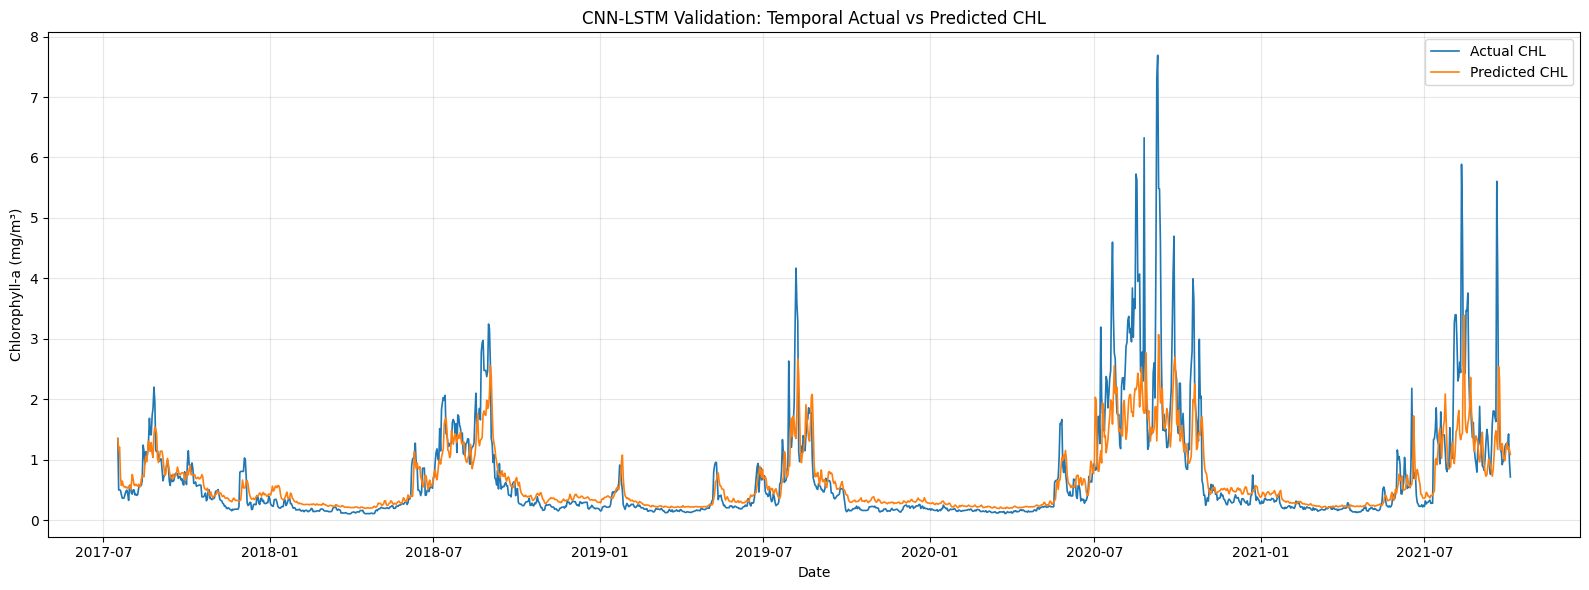

Saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_temporal_actual_vs_predicted.png

2. MONTHLY MAE ANALYSIS
    month       MAE
0       1  0.150235
1       2  0.082922
2       3  0.073030
3       4  0.078345
4       5  0.160939
5       6  0.271867
6       7  0.501903
7       8  0.877752
8       9  0.586859
9      10  0.339161
10     11  0.148413
11     12  0.146919


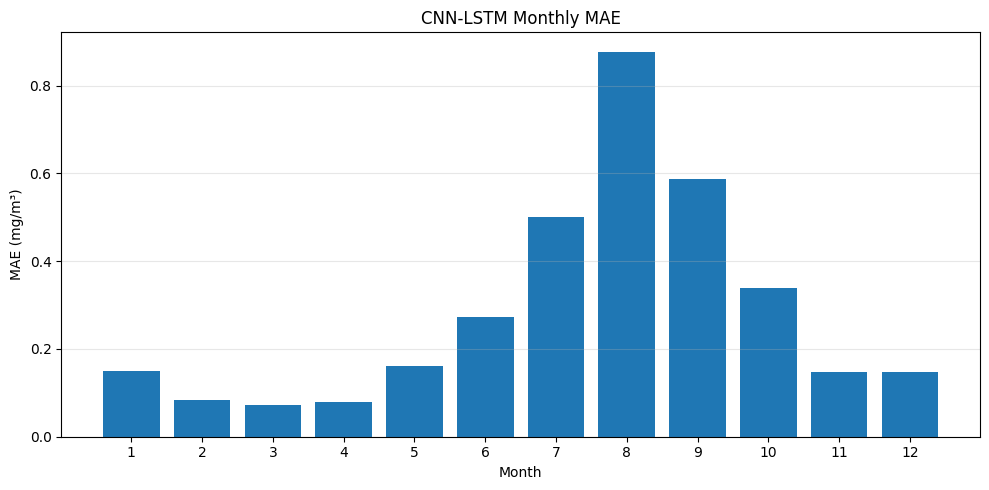

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_monthly_mae.png

3. MONTHLY R² ANALYSIS
    month        R2  observations
0       1 -0.131414         12648
1       2 -1.004278         11526
2       3 -1.288150         12648
3       4 -0.953281         12240
4       5  0.262354         12648
5       6  0.034251         12240
6       7  0.281243         14178
7       8  0.089261         15810
8       9  0.278139         15300
9      10  0.369373         13056
10     11 -0.057198         12240
11     12  0.142820         12648


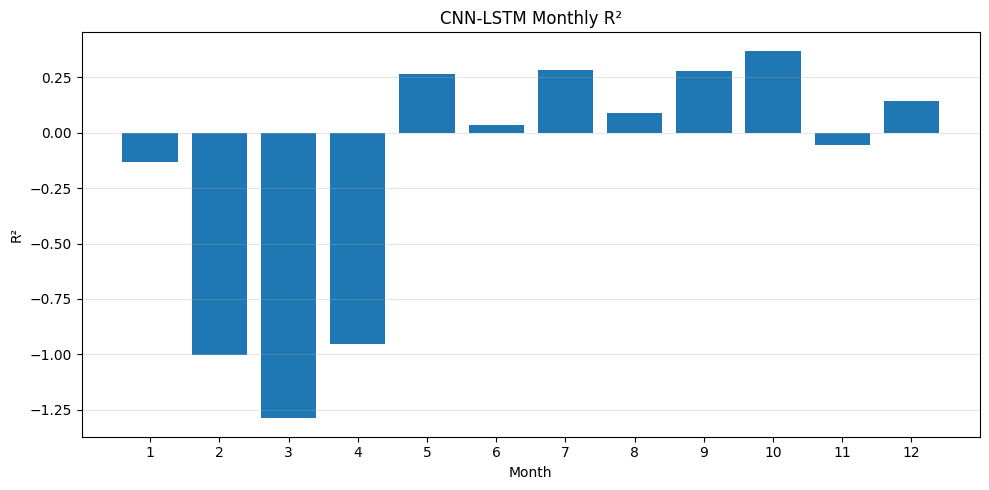

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_monthly_r2.png

4. MONTHLY PERFORMANCE TABLE
    month  observations  actual_mean  predicted_mean       MAE      RMSE  \
0       1         12648     0.275013        0.391507  0.150235  0.226616   
1       2         11526     0.188195        0.263827  0.082922  0.092956   
2       3         12648     0.156102        0.222861  0.073030  0.080753   
3       4         12240     0.153547        0.222915  0.078345  0.090834   
4       5         12648     0.352646        0.378784  0.160939  0.406711   
5       6         12240     0.539740        0.594321  0.271867  0.451752   
6       7         14178     1.188218        1.038331  0.501903  0.977431   
7       8         15810     1.944777        1.435260  0.877752  1.909506   
8       9         15300     1.277405        1.084494  0.586859  1.781389   
9      10         13056     0.698503        0.711711  0.339161  0.796569   
10     11         12

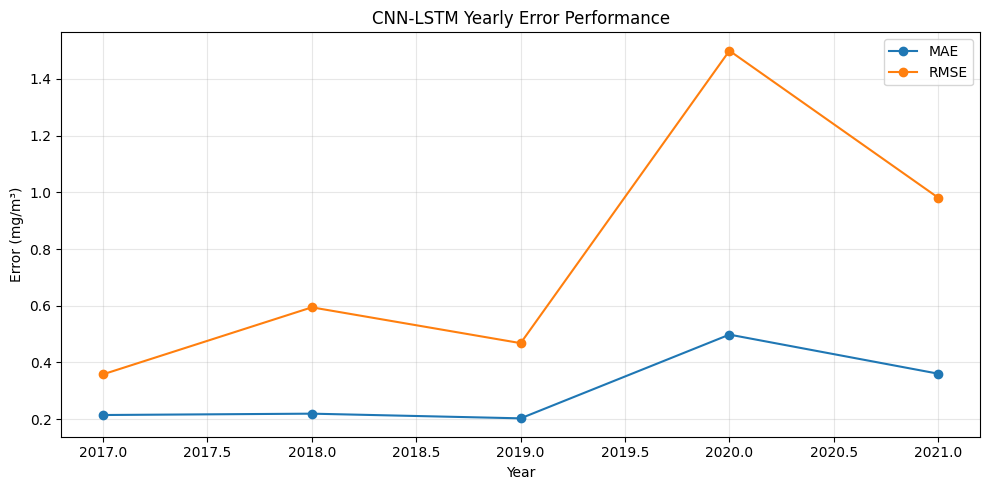

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_yearly_error.png

7. HIGH-CHL EVENT VISUAL ANALYSIS
   percentile  threshold_mg_m3  event_observations  accuracy  precision  \
0          75         0.545567               47358  0.894937   0.773449   
1          90         0.922410               30821  0.917910   0.785846   
2          95         1.304732               20469  0.916543   0.716652   
3          99         3.127116                4330  0.971880   0.458716   

     recall  f1_score  specificity  false_alarm_rate  
0  0.921090  0.840838     0.883659          0.116341  
1  0.799130  0.792433     0.946882          0.053118  
2  0.593971  0.649570     0.964839          0.035161  
3  0.115473  0.184502     0.996140          0.003860  


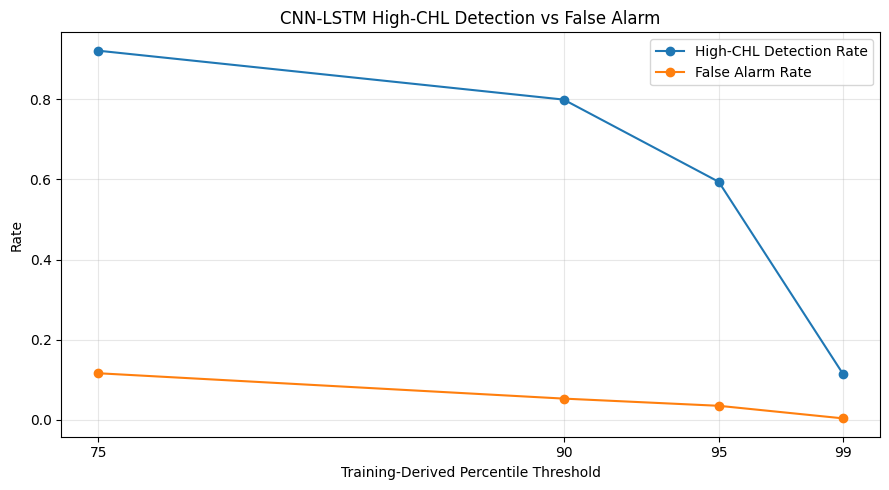

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_high_chl_detection_vs_false_alarm.png


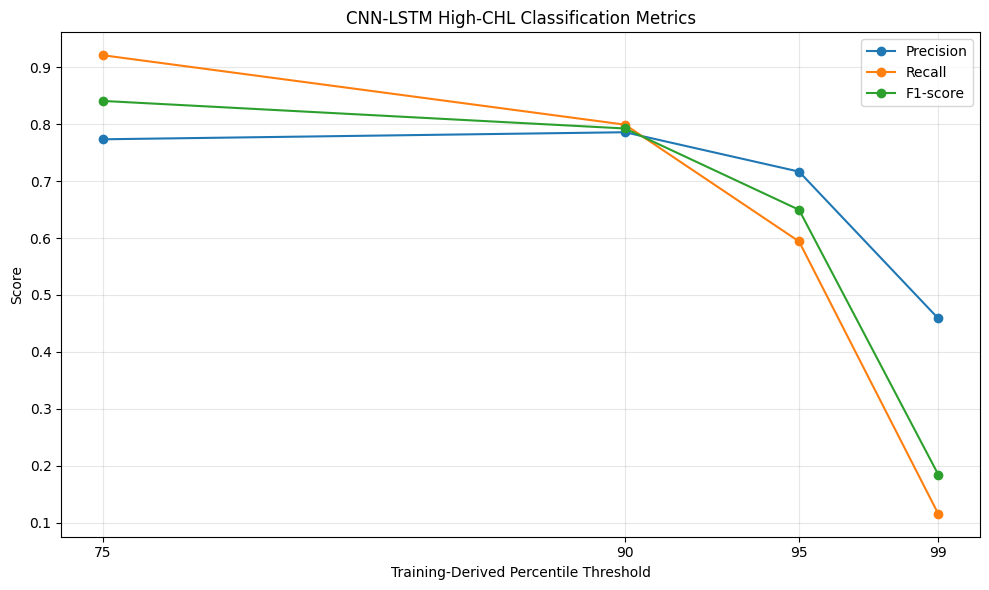

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_high_chl_classification_metrics.png

8. ACTUAL VS PREDICTED CHL


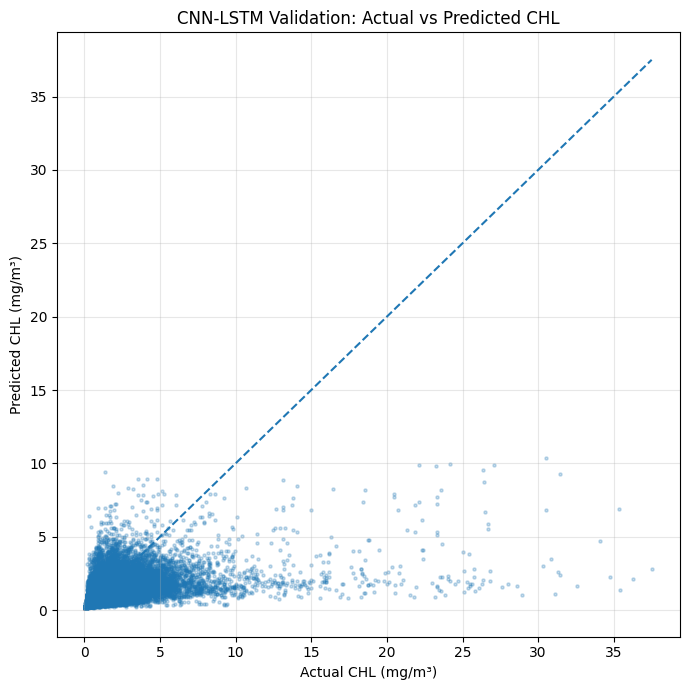

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_actual_vs_predicted_scatter.png

9. ERROR DISTRIBUTION


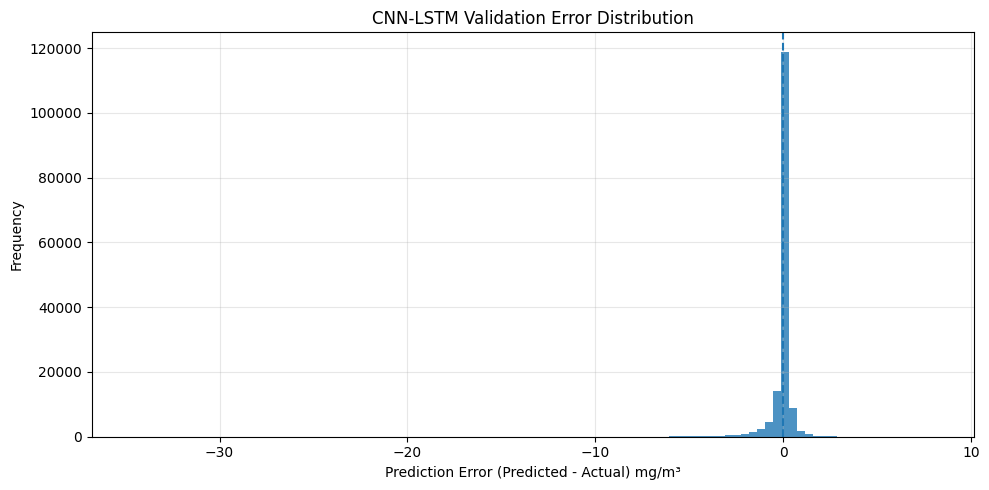

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_error_distribution.png

10. ERROR VS ACTUAL CHL


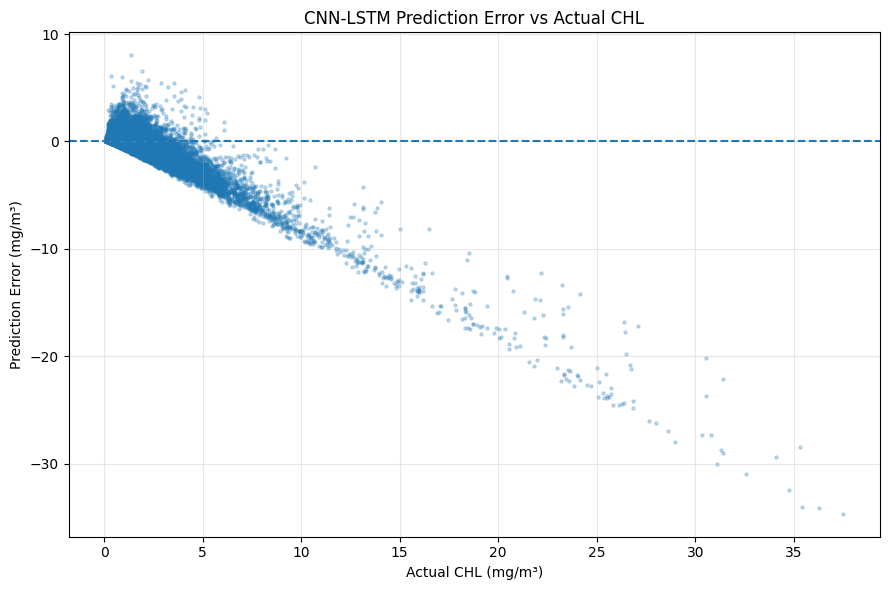

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_error_vs_actual_chl.png

11. SPATIAL PERFORMANCE
Number of spatial locations: 102

Spatial performance summary:
   latitude  longitude  observations  actual_mean  predicted_mean       MAE  \
0  5.833334  79.333336          1541     0.436195        0.470105  0.198273   
1  5.833334  79.416664          1541     0.443670        0.479149  0.194429   
2  5.833334  79.500000          1541     0.458239        0.489058  0.194709   
3  5.833334  79.583336          1541     0.494091        0.503312  0.210106   
4  5.833334  79.666664          1541     0.521947        0.512818  0.220283   

       RMSE        R2      bias  
0  0.471804  0.456998  0.033910  
1  0.420665  0.513076  0.035479  
2  0.374064  0.573835  0.030820  
3  0.427996  0.572947  0.009221  
4  0.467996  0.582042 -0.009129  
Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_spatial_per

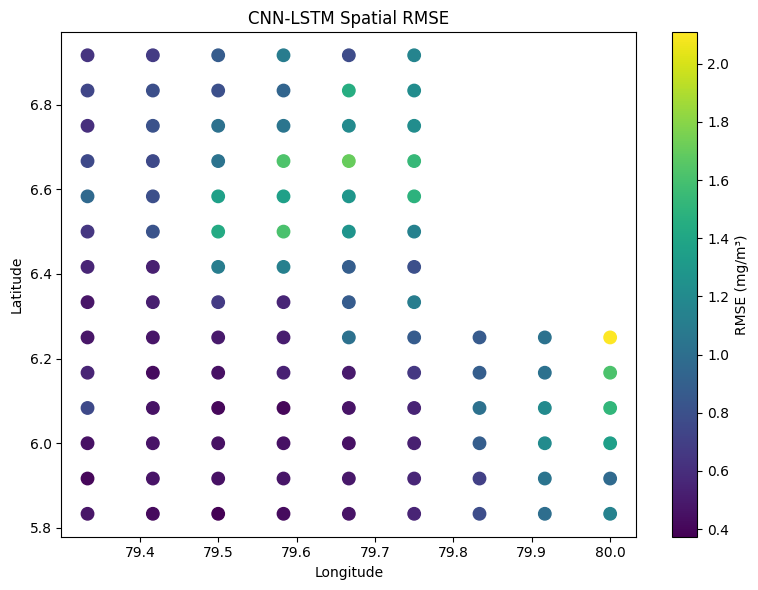

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_spatial_rmse_map.png


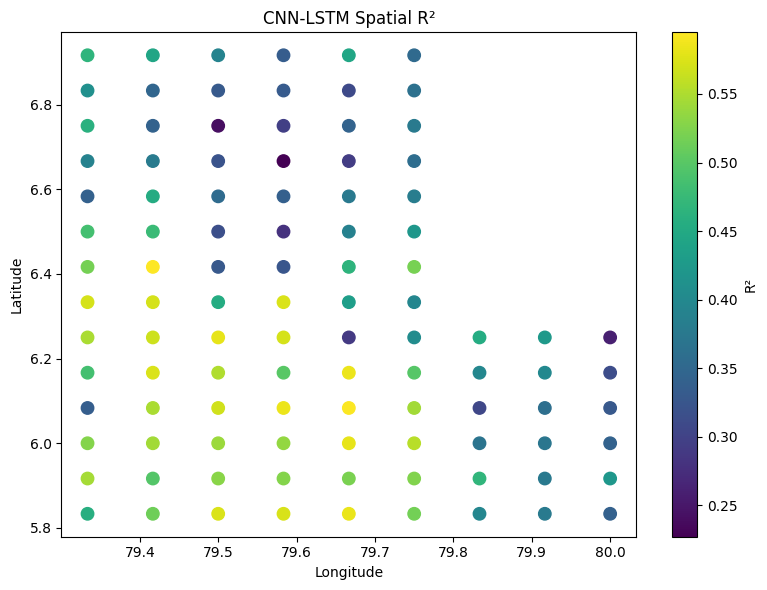

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_spatial_r2_map.png


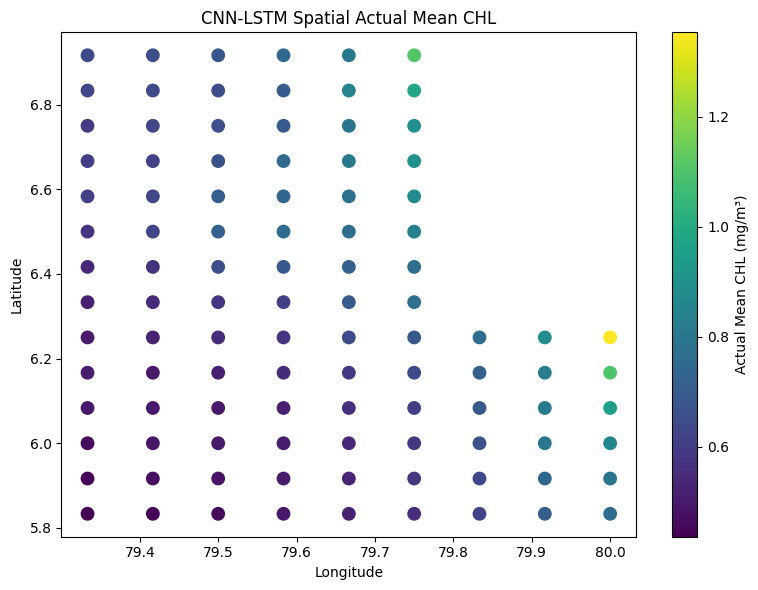

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_spatial_actual_mean_chl.png


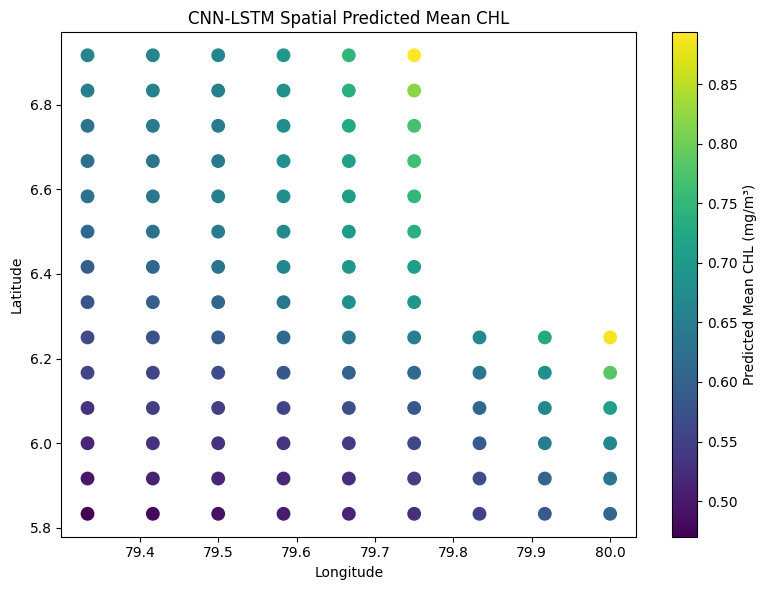

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_spatial_predicted_mean_chl.png


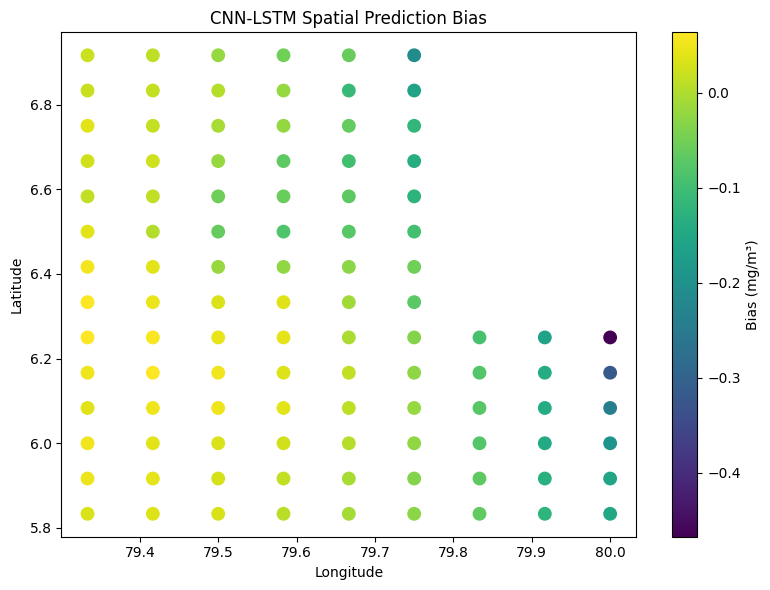

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_spatial_bias_map.png

Saved: /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_high_chl_classification_metrics.csv

STEP 31.9P-14I COMPLETE
Generated:
✓ Temporal actual vs predicted CHL
✓ Monthly MAE analysis
✓ Monthly R² analysis
✓ Monthly performance table
✓ Seasonal performance analysis
✓ Yearly performance analysis
✓ Yearly error visualization
✓ High-CHL detection vs false-alarm analysis
✓ High-CHL classification metrics
✓ Actual vs predicted scatter plot
✓ Error distribution
✓ Error vs actual CHL
✓ Spatial RMSE map
✓ Spatial R² map
✓ Spatial actual mean CHL map
✓ Spatial predicted mean CHL map
✓ Spatial bias map

✓ Validation data only.
✓ Test data was NOT used.

All outputs saved to:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

Next:
STEP 31.9P-14J — CNN-LSTM ERROR / EXTREME EVENT ANALYSIS


In [ ]:
# ======================================================================
# STEP 31.9P-14I — CNN-LSTM VISUAL ANALYSIS
# ======================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 70)
print("STEP 31.9P-14I — CNN-LSTM VISUAL ANALYSIS")
print("=" * 70)


# ======================================================================
# 1. DIRECTORIES
# ======================================================================

BASE_DIR = (
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

CNN_LSTM_DIR = os.path.join(
    BASE_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVALUATION_DIR = os.path.join(
    CNN_LSTM_DIR,
    "evaluation"
)

PREDICTION_FILE = os.path.join(
    CNN_LSTM_DIR,
    "cnn_lstm_validation_predictions.csv"
)

os.makedirs(
    EVALUATION_DIR,
    exist_ok=True
)

print("\nProject directory:")
print(BASE_DIR)

print("\nCNN-LSTM directory:")
print(CNN_LSTM_DIR)

print("\nEvaluation directory:")
print(EVALUATION_DIR)


# ======================================================================
# 2. LOAD VALIDATION PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING CNN-LSTM VALIDATION PREDICTIONS")
print("=" * 70)

print(
    "Prediction file:"
)

print(
    PREDICTION_FILE
)

if not os.path.exists(PREDICTION_FILE):

    raise FileNotFoundError(
        f"Validation prediction file not found: {PREDICTION_FILE}"
    )

df = pd.read_csv(
    PREDICTION_FILE
)

print(
    "\nValidation prediction shape:"
)

print(
    df.shape
)

print(
    "\nColumns:"
)

print(
    list(df.columns)
)

print(
    "\n✓ Validation predictions loaded."
)


# ======================================================================
# 3. DATE PREPARATION
# ======================================================================

print("\n" + "=" * 70)
print("DATE PREPARATION")
print("=" * 70)

if "target_date" in df.columns:

    df["target_date"] = pd.to_datetime(
        df["target_date"]
    )

elif "date" in df.columns:

    df["target_date"] = pd.to_datetime(
        df["date"]
    )

else:

    raise ValueError(
        "No target_date or date column found."
    )

df["year"] = df[
    "target_date"
].dt.year

df["month"] = df[
    "target_date"
].dt.month

df["day_of_year"] = df[
    "target_date"
].dt.dayofyear

print(
    "Minimum date:",
    df["target_date"].min()
)

print(
    "Maximum date:",
    df["target_date"].max()
)

print(
    "Unique dates:",
    df["target_date"].nunique()
)


# ======================================================================
# 4. CREATE ERROR VARIABLES
# ======================================================================

print("\n" + "=" * 70)
print("CREATING ERROR VARIABLES")
print("=" * 70)

df["error"] = (
    df["predicted_chlorophyll_a"]
    -
    df["actual_chlorophyll_a"]
)

df["absolute_error"] = np.abs(
    df["error"]
)

df["squared_error"] = (
    df["error"] ** 2
)

print(
    "✓ Error variables created."
)


# ======================================================================
# 5. OVERALL VISUAL DATA SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("OVERALL VALIDATION SUMMARY")
print("=" * 70)

actual = df[
    "actual_chlorophyll_a"
].values

predicted = df[
    "predicted_chlorophyll_a"
].values

overall_mae = mean_absolute_error(
    actual,
    predicted
)

overall_rmse = np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

overall_r2 = r2_score(
    actual,
    predicted
)

overall_bias = np.mean(
    predicted
    -
    actual
)

print(
    f"MAE  : {overall_mae:.6f} mg/m³"
)

print(
    f"RMSE : {overall_rmse:.6f} mg/m³"
)

print(
    f"R²   : {overall_r2:.6f}"
)

print(
    f"Bias : {overall_bias:.6f} mg/m³"
)


# ======================================================================
# 6. TEMPORAL ACTUAL VS PREDICTED
# ======================================================================

print("\n" + "=" * 70)
print("1. TEMPORAL ACTUAL VS PREDICTED CHL")
print("=" * 70)

daily_temporal = (
    df.groupby(
        "target_date"
    )
    .agg(
        actual_mean=(
            "actual_chlorophyll_a",
            "mean"
        ),
        predicted_mean=(
            "predicted_chlorophyll_a",
            "mean"
        )
    )
    .reset_index()
)

plt.figure(
    figsize=(16, 6)
)

plt.plot(
    daily_temporal["target_date"],
    daily_temporal["actual_mean"],
    label="Actual CHL",
    linewidth=1.2
)

plt.plot(
    daily_temporal["target_date"],
    daily_temporal["predicted_mean"],
    label="Predicted CHL",
    linewidth=1.2
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Chlorophyll-a (mg/m³)"
)

plt.title(
    "CNN-LSTM Validation: Temporal Actual vs Predicted CHL"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

temporal_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_temporal_actual_vs_predicted.png"
)

plt.savefig(
    temporal_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:"
)

print(
    temporal_file
)


# ======================================================================
# 7. MONTHLY MAE
# ======================================================================

print("\n" + "=" * 70)
print("2. MONTHLY MAE ANALYSIS")
print("=" * 70)

monthly_mae = (
    df.groupby(
        "month"
    )
    .apply(
        lambda x: mean_absolute_error(
            x["actual_chlorophyll_a"],
            x["predicted_chlorophyll_a"]
        ),
        include_groups=False
    )
    .reset_index(
        name="MAE"
    )
)

print(
    monthly_mae
)

monthly_mae_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_monthly_mae.png"
)

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    monthly_mae["month"],
    monthly_mae["MAE"]
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "MAE (mg/m³)"
)

plt.title(
    "CNN-LSTM Monthly MAE"
)

plt.xticks(
    range(1, 13)
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    monthly_mae_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    monthly_mae_file
)


# ======================================================================
# 8. MONTHLY R²
# ======================================================================

print("\n" + "=" * 70)
print("3. MONTHLY R² ANALYSIS")
print("=" * 70)

monthly_r2_records = []

for month, group in df.groupby(
    "month"
):

    if (
        group["actual_chlorophyll_a"].nunique()
        > 1
    ):

        r2 = r2_score(
            group[
                "actual_chlorophyll_a"
            ],
            group[
                "predicted_chlorophyll_a"
            ]
        )

    else:

        r2 = np.nan

    monthly_r2_records.append(
        {
            "month": month,
            "R2": r2,
            "observations": len(group)
        }
    )

monthly_r2 = pd.DataFrame(
    monthly_r2_records
).sort_values(
    "month"
)

print(
    monthly_r2
)

monthly_r2_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_monthly_r2.png"
)

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    monthly_r2["month"],
    monthly_r2["R2"]
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "R²"
)

plt.title(
    "CNN-LSTM Monthly R²"
)

plt.xticks(
    range(1, 13)
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    monthly_r2_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    monthly_r2_file
)


# ======================================================================
# 9. MONTHLY PERFORMANCE TABLE
# ======================================================================

print("\n" + "=" * 70)
print("4. MONTHLY PERFORMANCE TABLE")
print("=" * 70)

monthly_records = []

for month, group in df.groupby(
    "month"
):

    y_true = group[
        "actual_chlorophyll_a"
    ].values

    y_pred = group[
        "predicted_chlorophyll_a"
    ].values

    if len(
        np.unique(y_true)
    ) > 1:

        month_r2 = r2_score(
            y_true,
            y_pred
        )

    else:

        month_r2 = np.nan

    monthly_records.append(
        {
            "month": month,
            "observations": len(group),
            "actual_mean": np.mean(y_true),
            "predicted_mean": np.mean(y_pred),
            "MAE": mean_absolute_error(
                y_true,
                y_pred
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            ),
            "R2": month_r2,
            "bias": np.mean(
                y_pred - y_true
            )
        }
    )

monthly_performance = pd.DataFrame(
    monthly_records
).sort_values(
    "month"
)

print(
    monthly_performance
)

monthly_csv = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_monthly_performance.csv"
)

monthly_performance.to_csv(
    monthly_csv,
    index=False
)

print(
    "Saved:",
    monthly_csv
)


# ======================================================================
# 10. SEASONAL PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("5. SEASONAL PERFORMANCE")
print("=" * 70)

def assign_season(month):

    if month in [12, 1, 2]:
        return "Northeast Monsoon"

    elif month in [3, 4]:
        return "Inter-monsoon 1"

    elif month in [5, 6, 7, 8, 9]:
        return "Southwest Monsoon"

    else:
        return "Inter-monsoon 2"


df["season"] = df[
    "month"
].apply(
    assign_season
)

seasonal_records = []

for season, group in df.groupby(
    "season"
):

    y_true = group[
        "actual_chlorophyll_a"
    ].values

    y_pred = group[
        "predicted_chlorophyll_a"
    ].values

    if len(
        np.unique(y_true)
    ) > 1:

        season_r2 = r2_score(
            y_true,
            y_pred
        )

    else:

        season_r2 = np.nan

    seasonal_records.append(
        {
            "season": season,
            "observations": len(group),
            "actual_mean": np.mean(y_true),
            "predicted_mean": np.mean(y_pred),
            "MAE": mean_absolute_error(
                y_true,
                y_pred
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            ),
            "R2": season_r2,
            "bias": np.mean(
                y_pred - y_true
            )
        }
    )

seasonal_performance = pd.DataFrame(
    seasonal_records
)

print(
    seasonal_performance
)

seasonal_csv = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_seasonal_performance.csv"
)

seasonal_performance.to_csv(
    seasonal_csv,
    index=False
)

print(
    "Saved:",
    seasonal_csv
)


# ======================================================================
# 11. YEARLY PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("6. YEARLY PERFORMANCE")
print("=" * 70)

yearly_records = []

for year, group in df.groupby(
    "year"
):

    y_true = group[
        "actual_chlorophyll_a"
    ].values

    y_pred = group[
        "predicted_chlorophyll_a"
    ].values

    if len(
        np.unique(y_true)
    ) > 1:

        year_r2 = r2_score(
            y_true,
            y_pred
        )

    else:

        year_r2 = np.nan

    yearly_records.append(
        {
            "year": year,
            "observations": len(group),
            "MAE": mean_absolute_error(
                y_true,
                y_pred
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            ),
            "R2": year_r2,
            "bias": np.mean(
                y_pred - y_true
            ),
            "actual_mean": np.mean(
                y_true
            ),
            "predicted_mean": np.mean(
                y_pred
            ),
            "actual_max": np.max(
                y_true
            ),
            "predicted_max": np.max(
                y_pred
            )
        }
    )

yearly_performance = pd.DataFrame(
    yearly_records
).sort_values(
    "year"
)

print(
    yearly_performance
)

yearly_csv = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_yearly_performance.csv"
)

yearly_performance.to_csv(
    yearly_csv,
    index=False
)

print(
    "Saved:",
    yearly_csv
)


# ======================================================================
# 12. YEARLY ERROR VISUALIZATION
# ======================================================================

yearly_plot_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_yearly_error.png"
)

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    yearly_performance["year"],
    yearly_performance["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    yearly_performance["year"],
    yearly_performance["RMSE"],
    marker="o",
    label="RMSE"
)

plt.xlabel(
    "Year"
)

plt.ylabel(
    "Error (mg/m³)"
)

plt.title(
    "CNN-LSTM Yearly Error Performance"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    yearly_plot_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    yearly_plot_file
)


# ======================================================================
# 13. HIGH-CHL EVENT VISUAL ANALYSIS
# ======================================================================

print("\n" + "=" * 70)
print("7. HIGH-CHL EVENT VISUAL ANALYSIS")
print("=" * 70)

# Training-derived thresholds already established
thresholds = {
    75: 0.545567,
    90: 0.922410,
    95: 1.304732,
    99: 3.127116
}

high_chl_summary = []

for percentile, threshold in thresholds.items():

    actual_event = (
        df[
            "actual_chlorophyll_a"
        ]
        >= threshold
    )

    predicted_event = (
        df[
            "predicted_chlorophyll_a"
        ]
        >= threshold
    )

    TP = np.sum(
        actual_event & predicted_event
    )

    TN = np.sum(
        (~actual_event)
        &
        (~predicted_event)
    )

    FP = np.sum(
        (~actual_event)
        &
        predicted_event
    )

    FN = np.sum(
        actual_event
        &
        (~predicted_event)
    )

    total = (
        TP + TN + FP + FN
    )

    accuracy = (
        (TP + TN) / total
        if total > 0
        else np.nan
    )

    precision = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else np.nan
    )

    recall = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else np.nan
    )

    specificity = (
        TN / (TN + FP)
        if (TN + FP) > 0
        else np.nan
    )

    false_alarm_rate = (
        FP / (FP + TN)
        if (FP + TN) > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall
        /
        (precision + recall)
        if (
            precision + recall
        ) > 0
        else np.nan
    )

    high_chl_summary.append(
        {
            "percentile": percentile,
            "threshold_mg_m3": threshold,
            "event_observations": int(
                actual_event.sum()
            ),
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "specificity": specificity,
            "false_alarm_rate": false_alarm_rate
        }
    )

high_chl_df = pd.DataFrame(
    high_chl_summary
)

print(
    high_chl_df
)


# ======================================================================
# 14. HIGH-CHL DETECTION VS FALSE ALARM
# ======================================================================

high_chl_plot_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_high_chl_detection_vs_false_alarm.png"
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    high_chl_df["percentile"],
    high_chl_df["recall"],
    marker="o",
    label="High-CHL Detection Rate"
)

plt.plot(
    high_chl_df["percentile"],
    high_chl_df["false_alarm_rate"],
    marker="o",
    label="False Alarm Rate"
)

plt.xlabel(
    "Training-Derived Percentile Threshold"
)

plt.ylabel(
    "Rate"
)

plt.title(
    "CNN-LSTM High-CHL Detection vs False Alarm"
)

plt.xticks(
    [75, 90, 95, 99]
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    high_chl_plot_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    high_chl_plot_file
)


# ======================================================================
# 15. HIGH-CHL CLASSIFICATION METRICS
# ======================================================================

classification_plot_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_high_chl_classification_metrics.png"
)

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    high_chl_df["percentile"],
    high_chl_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    high_chl_df["percentile"],
    high_chl_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    high_chl_df["percentile"],
    high_chl_df["f1_score"],
    marker="o",
    label="F1-score"
)

plt.xlabel(
    "Training-Derived Percentile Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "CNN-LSTM High-CHL Classification Metrics"
)

plt.xticks(
    [75, 90, 95, 99]
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    classification_plot_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    classification_plot_file
)


# ======================================================================
# 16. ACTUAL VS PREDICTED SCATTER
# ======================================================================

print("\n" + "=" * 70)
print("8. ACTUAL VS PREDICTED CHL")
print("=" * 70)

scatter_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_actual_vs_predicted_scatter.png"
)

plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    actual,
    predicted,
    s=5,
    alpha=0.25
)

minimum_value = min(
    np.min(actual),
    np.min(predicted)
)

maximum_value = max(
    np.max(actual),
    np.max(predicted)
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel(
    "Actual CHL (mg/m³)"
)

plt.ylabel(
    "Predicted CHL (mg/m³)"
)

plt.title(
    "CNN-LSTM Validation: Actual vs Predicted CHL"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    scatter_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    scatter_file
)


# ======================================================================
# 17. ERROR DISTRIBUTION
# ======================================================================

print("\n" + "=" * 70)
print("9. ERROR DISTRIBUTION")
print("=" * 70)

error_distribution_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_error_distribution.png"
)

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    df["error"],
    bins=100,
    alpha=0.8
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error (Predicted - Actual) mg/m³"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "CNN-LSTM Validation Error Distribution"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    error_distribution_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    error_distribution_file
)


# ======================================================================
# 18. ERROR VS ACTUAL CHL
# ======================================================================

print("\n" + "=" * 70)
print("10. ERROR VS ACTUAL CHL")
print("=" * 70)

error_actual_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_error_vs_actual_chl.png"
)

plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    actual,
    df["error"],
    s=5,
    alpha=0.25
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Actual CHL (mg/m³)"
)

plt.ylabel(
    "Prediction Error (mg/m³)"
)

plt.title(
    "CNN-LSTM Prediction Error vs Actual CHL"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    error_actual_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    error_actual_file
)


# ======================================================================
# 19. SPATIAL PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("11. SPATIAL PERFORMANCE")
print("=" * 70)

spatial_records = []

for (
    latitude,
    longitude
), group in df.groupby(
    ["latitude", "longitude"]
):

    y_true = group[
        "actual_chlorophyll_a"
    ].values

    y_pred = group[
        "predicted_chlorophyll_a"
    ].values

    if len(
        np.unique(y_true)
    ) > 1:

        location_r2 = r2_score(
            y_true,
            y_pred
        )

    else:

        location_r2 = np.nan

    spatial_records.append(
        {
            "latitude": latitude,
            "longitude": longitude,
            "observations": len(group),
            "actual_mean": np.mean(
                y_true
            ),
            "predicted_mean": np.mean(
                y_pred
            ),
            "MAE": mean_absolute_error(
                y_true,
                y_pred
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            ),
            "R2": location_r2,
            "bias": np.mean(
                y_pred - y_true
            )
        }
    )

spatial_performance = pd.DataFrame(
    spatial_records
)

print(
    "Number of spatial locations:",
    len(spatial_performance)
)

print(
    "\nSpatial performance summary:"
)

print(
    spatial_performance.head()
)

spatial_csv = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_spatial_performance.csv"
)

spatial_performance.to_csv(
    spatial_csv,
    index=False
)

print(
    "Saved:",
    spatial_csv
)


# ======================================================================
# 20. SPATIAL RMSE MAP
# ======================================================================

spatial_rmse_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_spatial_rmse_map.png"
)

plt.figure(
    figsize=(8, 6)
)

scatter = plt.scatter(
    spatial_performance["longitude"],
    spatial_performance["latitude"],
    c=spatial_performance["RMSE"],
    s=80
)

plt.colorbar(
    scatter,
    label="RMSE (mg/m³)"
)

plt.xlabel(
    "Longitude"
)

plt.ylabel(
    "Latitude"
)

plt.title(
    "CNN-LSTM Spatial RMSE"
)

plt.tight_layout()

plt.savefig(
    spatial_rmse_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    spatial_rmse_file
)


# ======================================================================
# 21. SPATIAL R² MAP
# ======================================================================

spatial_r2_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_spatial_r2_map.png"
)

plt.figure(
    figsize=(8, 6)
)

scatter = plt.scatter(
    spatial_performance["longitude"],
    spatial_performance["latitude"],
    c=spatial_performance["R2"],
    s=80
)

plt.colorbar(
    scatter,
    label="R²"
)

plt.xlabel(
    "Longitude"
)

plt.ylabel(
    "Latitude"
)

plt.title(
    "CNN-LSTM Spatial R²"
)

plt.tight_layout()

plt.savefig(
    spatial_r2_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    spatial_r2_file
)


# ======================================================================
# 22. SPATIAL ACTUAL MEAN CHL
# ======================================================================

spatial_actual_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_spatial_actual_mean_chl.png"
)

plt.figure(
    figsize=(8, 6)
)

scatter = plt.scatter(
    spatial_performance["longitude"],
    spatial_performance["latitude"],
    c=spatial_performance["actual_mean"],
    s=80
)

plt.colorbar(
    scatter,
    label="Actual Mean CHL (mg/m³)"
)

plt.xlabel(
    "Longitude"
)

plt.ylabel(
    "Latitude"
)

plt.title(
    "CNN-LSTM Spatial Actual Mean CHL"
)

plt.tight_layout()

plt.savefig(
    spatial_actual_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    spatial_actual_file
)


# ======================================================================
# 23. SPATIAL PREDICTED MEAN CHL
# ======================================================================

spatial_predicted_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_spatial_predicted_mean_chl.png"
)

plt.figure(
    figsize=(8, 6)
)

scatter = plt.scatter(
    spatial_performance["longitude"],
    spatial_performance["latitude"],
    c=spatial_performance["predicted_mean"],
    s=80
)

plt.colorbar(
    scatter,
    label="Predicted Mean CHL (mg/m³)"
)

plt.xlabel(
    "Longitude"
)

plt.ylabel(
    "Latitude"
)

plt.title(
    "CNN-LSTM Spatial Predicted Mean CHL"
)

plt.tight_layout()

plt.savefig(
    spatial_predicted_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    spatial_predicted_file
)


# ======================================================================
# 24. SPATIAL BIAS MAP
# ======================================================================

spatial_bias_file = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_spatial_bias_map.png"
)

plt.figure(
    figsize=(8, 6)
)

scatter = plt.scatter(
    spatial_performance["longitude"],
    spatial_performance["latitude"],
    c=spatial_performance["bias"],
    s=80
)

plt.colorbar(
    scatter,
    label="Bias (mg/m³)"
)

plt.xlabel(
    "Longitude"
)

plt.ylabel(
    "Latitude"
)

plt.title(
    "CNN-LSTM Spatial Prediction Bias"
)

plt.tight_layout()

plt.savefig(
    spatial_bias_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    spatial_bias_file
)


# ======================================================================
# 25. SAVE HIGH-CHL SUMMARY
# ======================================================================

high_chl_csv = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_high_chl_classification_metrics.csv"
)

high_chl_df.to_csv(
    high_chl_csv,
    index=False
)

print(
    "\nSaved:",
    high_chl_csv
)


# ======================================================================
# 26. FINAL VISUAL ANALYSIS SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-14I COMPLETE")
print("=" * 70)

print(
    "Generated:"
)

print(
    "✓ Temporal actual vs predicted CHL"
)

print(
    "✓ Monthly MAE analysis"
)

print(
    "✓ Monthly R² analysis"
)

print(
    "✓ Monthly performance table"
)

print(
    "✓ Seasonal performance analysis"
)

print(
    "✓ Yearly performance analysis"
)

print(
    "✓ Yearly error visualization"
)

print(
    "✓ High-CHL detection vs false-alarm analysis"
)

print(
    "✓ High-CHL classification metrics"
)

print(
    "✓ Actual vs predicted scatter plot"
)

print(
    "✓ Error distribution"
)

print(
    "✓ Error vs actual CHL"
)

print(
    "✓ Spatial RMSE map"
)

print(
    "✓ Spatial R² map"
)

print(
    "✓ Spatial actual mean CHL map"
)

print(
    "✓ Spatial predicted mean CHL map"
)

print(
    "✓ Spatial bias map"
)

print(
    "\n✓ Validation data only."
)

print(
    "✓ Test data was NOT used."
)

print(
    "\nAll outputs saved to:"
)

print(
    EVALUATION_DIR
)

print(
    "\nNext:"
)

print(
    "STEP 31.9P-14J — CNN-LSTM ERROR / EXTREME EVENT ANALYSIS"
)

In [ ]:
# ======================================================================
# STEP 31.9P-14J — CNN-LSTM ERROR / EXTREME EVENT ANALYSIS
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 70)
print("STEP 31.9P-14J — CNN-LSTM ERROR / EXTREME EVENT ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------------------
# DIRECTORIES
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

CNN_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVAL_DIR = os.path.join(
    CNN_DIR,
    "evaluation"
)

PREDICTION_FILE = os.path.join(
    CNN_DIR,
    "cnn_lstm_validation_predictions.csv"
)

os.makedirs(EVAL_DIR, exist_ok=True)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nCNN-LSTM directory:")
print(CNN_DIR)

print("\nEvaluation directory:")
print(EVAL_DIR)


# ======================================================================
# REQUIRED FILE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

print("\nValidation prediction file:")
print(PREDICTION_FILE)

print("Exists:", os.path.exists(PREDICTION_FILE))

if not os.path.exists(PREDICTION_FILE):
    raise FileNotFoundError(
        f"Required file not found: {PREDICTION_FILE}"
    )

print("\n✓ Validation prediction file found.")
print("✓ No test data required.")


# ======================================================================
# LOAD VALIDATION PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING VALIDATION PREDICTIONS")
print("=" * 70)

df = pd.read_csv(PREDICTION_FILE)

df["target_date"] = pd.to_datetime(df["target_date"])

print("\nValidation prediction shape:")
print(df.shape)

required_columns = [
    "target_date",
    "latitude",
    "longitude",
    "actual_chlorophyll_a_log1p",
    "predicted_chlorophyll_a_log1p",
    "actual_chlorophyll_a",
    "predicted_chlorophyll_a",
    "error_chlorophyll_a",
    "absolute_error_chlorophyll_a"
]

missing_columns = [
    c for c in required_columns
    if c not in df.columns
]

print("\nMissing required columns:")
print(missing_columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("✓ All required columns available.")


# ======================================================================
# CREATE ERROR VARIABLES
# ======================================================================

print("\n" + "=" * 70)
print("CREATING ERROR VARIABLES")
print("=" * 70)

actual = df["actual_chlorophyll_a"].to_numpy(dtype=float)
predicted = df["predicted_chlorophyll_a"].to_numpy(dtype=float)

error = predicted - actual
absolute_error = np.abs(error)

df["error"] = error
df["absolute_error"] = absolute_error

print("✓ Error variables created.")


# ======================================================================
# SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION SAFETY CHECK")
print("=" * 70)

print("\nNaN values:")
print(df[[
    "actual_chlorophyll_a",
    "predicted_chlorophyll_a",
    "error"
]].isna().sum())

print("\nInfinite values:")

for col in [
    "actual_chlorophyll_a",
    "predicted_chlorophyll_a",
    "error"
]:
    print(
        col,
        ":",
        np.isinf(df[col].to_numpy()).sum()
    )

if (
    df[
        [
            "actual_chlorophyll_a",
            "predicted_chlorophyll_a",
            "error"
        ]
    ].isna().any().any()
):
    raise ValueError("NaN values detected.")

if any(
    np.isinf(df[col].to_numpy()).any()
    for col in [
        "actual_chlorophyll_a",
        "predicted_chlorophyll_a",
        "error"
    ]
):
    raise ValueError("Infinite values detected.")

print("\n✓ Validation predictions passed safety checks.")


# ======================================================================
# 1. OVERALL ERROR SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("1. OVERALL ERROR SUMMARY")
print("=" * 70)

overall_mae = mean_absolute_error(actual, predicted)
overall_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)
overall_r2 = r2_score(actual, predicted)
overall_bias = np.mean(error)
median_ae = np.median(absolute_error)

max_actual = np.max(actual)
max_predicted = np.max(predicted)
max_absolute_error = np.max(absolute_error)

overprediction_count = np.sum(error > 0)
underprediction_count = np.sum(error < 0)
exact_count = np.sum(error == 0)

n = len(df)

print(f"MAE                    : {overall_mae:.6f} mg/m³")
print(f"RMSE                   : {overall_rmse:.6f} mg/m³")
print(f"R²                     : {overall_r2:.6f}")
print(f"Mean Bias              : {overall_bias:.6f} mg/m³")
print(f"Median Absolute Error  : {median_ae:.6f} mg/m³")

print(f"Maximum Actual CHL     : {max_actual:.6f} mg/m³")
print(f"Maximum Predicted CHL  : {max_predicted:.6f} mg/m³")
print(f"Maximum Absolute Error : {max_absolute_error:.6f} mg/m³")

print(
    f"Overpredictions        : "
    f"{overprediction_count:,} "
    f"({100 * overprediction_count / n:.2f}%)"
)

print(
    f"Underpredictions       : "
    f"{underprediction_count:,} "
    f"({100 * underprediction_count / n:.2f}%)"
)

print(
    f"Exact predictions      : "
    f"{exact_count:,} "
    f"({100 * exact_count / n:.2f}%)"
)


# ======================================================================
# 2. ERROR BY CHL RANGE
# ======================================================================

print("\n" + "=" * 70)
print("2. ERROR BY CHL RANGE")
print("=" * 70)

bins = [-np.inf, 0.2, 0.5, 1, 2, 5, 10, np.inf]

labels = [
    "0–0.2",
    "0.2–0.5",
    "0.5–1",
    "1–2",
    "2–5",
    "5–10",
    ">10"
]

df["chl_range"] = pd.cut(
    df["actual_chlorophyll_a"],
    bins=bins,
    labels=labels,
    right=False
)

range_results = []

for label in labels:

    subset = df[df["chl_range"] == label]

    if len(subset) == 0:
        continue

    y_true = subset["actual_chlorophyll_a"].to_numpy()
    y_pred = subset["predicted_chlorophyll_a"].to_numpy()

    range_mae = mean_absolute_error(
        y_true,
        y_pred
    )

    range_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    range_bias = np.mean(
        y_pred - y_true
    )

    range_results.append({
        "chl_range": label,
        "observations": len(subset),
        "actual_mean": np.mean(y_true),
        "predicted_mean": np.mean(y_pred),
        "MAE": range_mae,
        "RMSE": range_rmse,
        "bias": range_bias
    })

range_df = pd.DataFrame(range_results)

print(range_df.to_string(index=False))

range_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_error_by_chl_range.csv"
)

range_df.to_csv(
    range_file,
    index=False
)

print("\nSaved:")
print(range_file)


# ======================================================================
# 3. TRAINING-DERIVED EXTREME CHL THRESHOLDS
# ======================================================================

print("\n" + "=" * 70)
print("3. TRAINING-DERIVED EXTREME CHL THRESHOLDS")
print("=" * 70)

# These thresholds are the same training-derived thresholds already
# established for the project.

thresholds = {
    75: 0.545567,
    90: 0.922410,
    95: 1.304732,
    99: 3.127116
}

for percentile, threshold in thresholds.items():

    print(
        f"{percentile}th percentile threshold: "
        f"{threshold:.6f} mg/m³"
    )


# ======================================================================
# 4. EXTREME CHL EVENT ERROR ANALYSIS
# ======================================================================

print("\n" + "=" * 70)
print("4. EXTREME CHL EVENT ERROR ANALYSIS")
print("=" * 70)

extreme_results = []

for percentile, threshold in thresholds.items():

    subset = df[
        df["actual_chlorophyll_a"] >= threshold
    ]

    if len(subset) == 0:
        continue

    y_true = subset[
        "actual_chlorophyll_a"
    ].to_numpy()

    y_pred = subset[
        "predicted_chlorophyll_a"
    ].to_numpy()

    event_mae = mean_absolute_error(
        y_true,
        y_pred
    )

    event_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    event_bias = np.mean(
        y_pred - y_true
    )

    extreme_results.append({
        "percentile": percentile,
        "threshold_mg_m3": threshold,
        "event_observations": len(subset),
        "event_MAE": event_mae,
        "event_RMSE": event_rmse,
        "event_bias": event_bias,
        "actual_mean": np.mean(y_true),
        "predicted_mean": np.mean(y_pred),
        "actual_max": np.max(y_true),
        "predicted_max": np.max(y_pred)
    })

extreme_df = pd.DataFrame(
    extreme_results
)

print(
    extreme_df.to_string(index=False)
)

extreme_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_extreme_chl_error_analysis.csv"
)

extreme_df.to_csv(
    extreme_file,
    index=False
)

print("\nSaved:")
print(extreme_file)


# ======================================================================
# 5. LARGEST PREDICTION ERRORS
# ======================================================================

print("\n" + "=" * 70)
print("5. LARGEST PREDICTION ERRORS")
print("=" * 70)

largest_errors = df[
    [
        "target_date",
        "latitude",
        "longitude",
        "actual_chlorophyll_a",
        "predicted_chlorophyll_a",
        "error",
        "absolute_error"
    ]
].sort_values(
    "absolute_error",
    ascending=False
).head(100)

print(
    largest_errors.head(20).to_string(
        index=False
    )
)

largest_error_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_largest_prediction_errors_top100.csv"
)

largest_errors.to_csv(
    largest_error_file,
    index=False
)

print("\nSaved:")
print(largest_error_file)


# ======================================================================
# 6. EXTREME ACTUAL VS PREDICTED CHL
# ======================================================================

print("\n" + "=" * 70)
print("6. EXTREME ACTUAL VS PREDICTED CHL")
print("=" * 70)

plt.figure(figsize=(10, 7))

plt.scatter(
    actual,
    predicted,
    s=8,
    alpha=0.25
)

max_axis = max(
    np.max(actual),
    np.max(predicted)
)

plt.plot(
    [0, max_axis],
    [0, max_axis],
    linestyle="--"
)

plt.xlabel(
    "Actual Chlorophyll-a (mg/m³)"
)

plt.ylabel(
    "Predicted Chlorophyll-a (mg/m³)"
)

plt.title(
    "CNN-LSTM — Extreme CHL Prediction Behaviour"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

extreme_plot = os.path.join(
    EVAL_DIR,
    "cnn_lstm_extreme_actual_vs_predicted.png"
)

plt.savefig(
    extreme_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Saved:")
print(extreme_plot)


# ======================================================================
# 7. ERROR DISTRIBUTION
# ======================================================================

print("\n" + "=" * 70)
print("7. ERROR DISTRIBUTION")
print("=" * 70)

plt.figure(figsize=(12, 6))

plt.hist(
    error,
    bins=200
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error = Predicted CHL − Actual CHL (mg/m³)"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "CNN-LSTM — Prediction Error Distribution"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

error_distribution_plot = os.path.join(
    EVAL_DIR,
    "cnn_lstm_error_distribution_detailed.png"
)

plt.savefig(
    error_distribution_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Saved:")
print(error_distribution_plot)


# ======================================================================
# 8. ERROR VS ACTUAL CHL
# ======================================================================

print("\n" + "=" * 70)
print("8. ERROR VS ACTUAL CHL")
print("=" * 70)

plt.figure(figsize=(10, 7))

plt.scatter(
    actual,
    error,
    s=8,
    alpha=0.25
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Actual Chlorophyll-a (mg/m³)"
)

plt.ylabel(
    "Prediction Error = Predicted − Actual (mg/m³)"
)

plt.title(
    "CNN-LSTM — Prediction Error vs Actual CHL"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

error_vs_actual_plot = os.path.join(
    EVAL_DIR,
    "cnn_lstm_error_vs_actual_chl_detailed.png"
)

plt.savefig(
    error_vs_actual_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Saved:")
print(error_vs_actual_plot)


# ======================================================================
# 9. YEARLY ERROR SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("9. YEARLY ERROR SUMMARY")
print("=" * 70)

df["year"] = df["target_date"].dt.year

yearly_results = []

for year, subset in df.groupby("year"):

    y_true = subset[
        "actual_chlorophyll_a"
    ].to_numpy()

    y_pred = subset[
        "predicted_chlorophyll_a"
    ].to_numpy()

    yearly_results.append({
        "year": year,
        "observations": len(subset),
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),
        "bias": np.mean(
            y_pred - y_true
        ),
        "actual_mean": np.mean(y_true),
        "predicted_mean": np.mean(y_pred),
        "actual_max": np.max(y_true),
        "predicted_max": np.max(y_pred),
        "maximum_absolute_error": np.max(
            np.abs(y_pred - y_true)
        )
    })

yearly_df = pd.DataFrame(
    yearly_results
)

print(
    yearly_df.to_string(index=False)
)

yearly_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_yearly_error_detailed.csv"
)

yearly_df.to_csv(
    yearly_file,
    index=False
)

print("\nSaved:")
print(yearly_file)


# ======================================================================
# 10. FINAL CNN-LSTM ERROR DIAGNOSTIC SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("10. FINAL CNN-LSTM ERROR DIAGNOSTIC SUMMARY")
print("=" * 70)

summary_df = pd.DataFrame({
    "metric": [
        "Overall MAE",
        "Overall RMSE",
        "Overall R2",
        "Mean Bias",
        "Median Absolute Error",
        "Maximum Actual CHL",
        "Maximum Predicted CHL",
        "Maximum Absolute Error",
        "Underprediction percentage",
        "Overprediction percentage"
    ],
    "value": [
        overall_mae,
        overall_rmse,
        overall_r2,
        overall_bias,
        median_ae,
        max_actual,
        max_predicted,
        max_absolute_error,
        100 * underprediction_count / n,
        100 * overprediction_count / n
    ]
})

print(
    summary_df.to_string(index=False)
)

summary_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_error_diagnostic_summary.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)

print("\nSaved:")
print(summary_file)


# ======================================================================
# FINAL STATUS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-14J COMPLETE")
print("=" * 70)

print("✓ Overall CNN-LSTM error analysed")
print("✓ Error analysed by CHL range")
print("✓ Training-derived percentile thresholds applied")
print("✓ Extreme CHL event errors analysed")
print("✓ Largest prediction errors identified")
print("✓ Extreme actual-vs-predicted behaviour visualised")
print("✓ Detailed residual distribution generated")
print("✓ Error vs actual CHL analysed")
print("✓ Yearly error statistics generated")
print("✓ Final CNN-LSTM diagnostic summary saved")

print("\n✓ Validation data only.")
print("✓ Test data was NOT used.")
print("✓ CNN-LSTM model was NOT retrained.")
print("✓ Model architecture was NOT changed.")

print("\nAll outputs saved to:")
print(EVAL_DIR)

print("\nNext:")
print("STEP 31.9P-14K — CNN-LSTM FINAL TEST EVALUATION")

STEP 31.9P-14J — CNN-LSTM ERROR / EXTREME EVENT ANALYSIS

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

REQUIRED FILE CHECK

Validation prediction file:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_validation_predictions.csv
Exists: True

✓ Validation prediction file found.
✓ No test data required.

LOADING VALIDATION PREDICTIONS

Validation prediction shape:
(157182, 9)

Missing required columns:
[]
✓ All required columns available.

CREATING ERROR VARIABLES
✓ Error variables created.

VALIDATION SAFETY CHECK

NaN values:
actual_chlorophyll_a       0
predicted_chlorophyll_a    0
error                      0
dtype: int64

Infinite values:
actual_chlorophyll_a : 0
predicted_chlorophyll_a : 0
error : 0

✓ Validation predictions passe

In [ ]:
# ================================================================
# STEP 31.9P-14K — CNN-LSTM FINAL TEST EVALUATION
# ================================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score,
    median_absolute_error
)

print("=" * 70)
print("STEP 31.9P-14K — CNN-LSTM FINAL TEST EVALUATION")
print("=" * 70)

# ================================================================
# 1. DIRECTORIES
# ================================================================

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

CNN_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVAL_DIR = os.path.join(
    CNN_DIR,
    "evaluation"
)

SEQ_DIR = os.path.join(
    CNN_DIR,
    "sequences"
)

os.makedirs(EVAL_DIR, exist_ok=True)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nCNN-LSTM directory:")
print(CNN_DIR)

print("\nEvaluation directory:")
print(EVAL_DIR)

# ================================================================
# 2. REQUIRED FILES
# ================================================================

MODEL_PATH = os.path.join(
    CNN_DIR,
    "cnn_lstm_best_model.keras"
)

X_TEST_PATH = os.path.join(
    SEQ_DIR,
    "cnn_lstm_X_test.npy"
)

Y_TEST_LOG_PATH = os.path.join(
    SEQ_DIR,
    "cnn_lstm_y_log_test.npy"
)

Y_TEST_ORIGINAL_PATH = os.path.join(
    SEQ_DIR,
    "cnn_lstm_y_original_test.npy"
)

METADATA_TEST_PATH = os.path.join(
    SEQ_DIR,
    "cnn_lstm_metadata_test.csv"
)

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Best CNN-LSTM model": MODEL_PATH,
    "Test sequences": X_TEST_PATH,
    "Test log target": Y_TEST_LOG_PATH,
    "Test original target": Y_TEST_ORIGINAL_PATH,
    "Test metadata": METADATA_TEST_PATH
}

for name, path in required_files.items():
    print(f"\n{name}:")
    print(path)
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required test-evaluation files found.")

# ================================================================
# 3. GPU VERIFICATION
# ================================================================

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print("Number of GPUs detected:", len(gpus))

for gpu in gpus:
    print("GPU:", gpu)

if len(gpus) > 0:
    print("\n✓ TensorFlow GPU environment available.")
else:
    print("\n⚠ No GPU detected. Evaluation can continue on CPU.")

# ================================================================
# 4. LOAD TEST SEQUENCES
# ================================================================

print("\n" + "=" * 70)
print("LOADING FINAL TEST SEQUENCES")
print("=" * 70)

X_test = np.load(X_TEST_PATH)
y_test_log = np.load(Y_TEST_LOG_PATH)
y_test_original = np.load(Y_TEST_ORIGINAL_PATH)

print("\nTest X shape:")
print(X_test.shape)

print("\nTest log target shape:")
print(y_test_log.shape)

print("\nTest original target shape:")
print(y_test_original.shape)

# ================================================================
# 5. LOAD TEST METADATA
# ================================================================

print("\n" + "=" * 70)
print("LOADING TEST METADATA")
print("=" * 70)

test_metadata = pd.read_csv(
    METADATA_TEST_PATH
)

print("\nMetadata shape:")
print(test_metadata.shape)

print("\nMetadata columns:")
print(list(test_metadata.columns))

print("\nFirst 5 metadata rows:")
print(test_metadata.head())

# ================================================================
# 6. ALIGNMENT CHECK
# ================================================================

print("\n" + "=" * 70)
print("TEST SEQUENCE ALIGNMENT CHECK")
print("=" * 70)

print("Test sequences:", len(X_test))
print("Log targets:", len(y_test_log))
print("Original targets:", len(y_test_original))
print("Metadata rows:", len(test_metadata))

if not (
    len(X_test)
    == len(y_test_log)
    == len(y_test_original)
    == len(test_metadata)
):
    raise ValueError(
        "Test X, targets and metadata are not aligned."
    )

print("\n✓ Test X, targets and metadata are aligned.")

# ================================================================
# 7. TARGET CONSISTENCY CHECK
# ================================================================

print("\n" + "=" * 70)
print("TARGET CONSISTENCY CHECK")
print("=" * 70)

reconstructed_original = np.expm1(y_test_log)

max_target_difference = np.max(
    np.abs(
        reconstructed_original
        - y_test_original
    )
)

print(
    "Maximum difference between:\n"
    "expm1(log target) and stored original target:"
)
print(max_target_difference)

if max_target_difference > 1e-4:
    raise ValueError(
        "Log and original test targets are inconsistent."
    )

print("\n✓ Log and original test targets are consistent.")

# ================================================================
# 8. TEST DATA SAFETY CHECK
# ================================================================

print("\n" + "=" * 70)
print("FINAL TEST DATA SAFETY CHECK")
print("=" * 70)

print("Predictor NaN:", np.isnan(X_test).sum())
print("Predictor infinite:", np.isinf(X_test).sum())

print("Log target NaN:", np.isnan(y_test_log).sum())
print("Log target infinite:", np.isinf(y_test_log).sum())

print("Original target NaN:", np.isnan(y_test_original).sum())
print("Original target infinite:", np.isinf(y_test_original).sum())

if (
    np.isnan(X_test).any()
    or np.isinf(X_test).any()
    or np.isnan(y_test_log).any()
    or np.isinf(y_test_log).any()
    or np.isnan(y_test_original).any()
    or np.isinf(y_test_original).any()
):
    raise ValueError(
        "Test data contains NaN or infinite values."
    )

print("\n✓ Final test data passed all safety checks.")

# ================================================================
# 9. LOAD BEST CNN-LSTM MODEL
# ================================================================

print("\n" + "=" * 70)
print("LOADING BEST CNN-LSTM MODEL")
print("=" * 70)

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("\nModel:")
print(MODEL_PATH)

print("\nModel name:")
print(model.name)

print("\nTrainable parameters:")
print(model.count_params())

print("\n✓ Best CNN-LSTM model loaded.")
print("✓ No retraining performed.")
print("✓ No architecture changes performed.")

# ================================================================
# 10. GENERATE FINAL TEST PREDICTIONS
# ================================================================

print("\n" + "=" * 70)
print("GENERATING FINAL TEST PREDICTIONS")
print("=" * 70)

start_time = time.time()

pred_test_log = model.predict(
    X_test,
    batch_size=512,
    verbose=1
).reshape(-1)

prediction_time = time.time() - start_time

print("\n✓ Final test predictions generated.")

print("Prediction time:")
print(f"{prediction_time:.2f} seconds")

print("\nPrediction shape:")
print(pred_test_log.shape)

# ================================================================
# 11. PREDICTION SANITY CHECK
# ================================================================

print("\n" + "=" * 70)
print("FINAL TEST PREDICTION SANITY CHECK")
print("=" * 70)

print("NaN predictions:", np.isnan(pred_test_log).sum())
print("Infinite predictions:", np.isinf(pred_test_log).sum())

if (
    np.isnan(pred_test_log).any()
    or np.isinf(pred_test_log).any()
):
    raise ValueError(
        "Test predictions contain NaN or infinite values."
    )

print("\n✓ Test predictions contain no NaN values.")
print("✓ Test predictions contain no infinite values.")

# ================================================================
# 12. CONVERT LOG1P PREDICTIONS TO ORIGINAL CHL
# ================================================================

print("\n" + "=" * 70)
print("CONVERTING TEST PREDICTIONS TO ORIGINAL CHL")
print("=" * 70)

print("""
CNN-LSTM output:
chlorophyll_a_log1p

        ↓

expm1()

        ↓

Predicted original CHL (mg/m³)
""")

pred_test_original = np.expm1(
    pred_test_log
)

print("✓ Predictions converted to original CHL scale.")

# ================================================================
# 13. FINAL TEST PREDICTION RANGES
# ================================================================

print("\n" + "=" * 70)
print("FINAL TEST PREDICTION RANGE")
print("=" * 70)

print("\nActual log1p CHL:")
print("Minimum:", np.min(y_test_log))
print("Maximum:", np.max(y_test_log))

print("\nPredicted log1p CHL:")
print("Minimum:", np.min(pred_test_log))
print("Maximum:", np.max(pred_test_log))

print("\nActual original CHL:")
print(
    "Minimum:",
    np.min(y_test_original),
    "mg/m³"
)
print(
    "Maximum:",
    np.max(y_test_original),
    "mg/m³"
)

print("\nPredicted original CHL:")
print(
    "Minimum:",
    np.min(pred_test_original),
    "mg/m³"
)
print(
    "Maximum:",
    np.max(pred_test_original),
    "mg/m³"
)

# ================================================================
# 14. ORIGINAL CHL METRICS
# ================================================================

mae_original = mean_absolute_error(
    y_test_original,
    pred_test_original
)

rmse_original = np.sqrt(
    mean_squared_error(
        y_test_original,
        pred_test_original
    )
)

r2_original = r2_score(
    y_test_original,
    pred_test_original
)

median_ae_original = median_absolute_error(
    y_test_original,
    pred_test_original
)

bias_original = np.mean(
    pred_test_original
    - y_test_original
)

explained_variance_original = explained_variance_score(
    y_test_original,
    pred_test_original
)

# ================================================================
# 15. LOG1P CHL METRICS
# ================================================================

mae_log = mean_absolute_error(
    y_test_log,
    pred_test_log
)

rmse_log = np.sqrt(
    mean_squared_error(
        y_test_log,
        pred_test_log
    )
)

r2_log = r2_score(
    y_test_log,
    pred_test_log
)

bias_log = np.mean(
    pred_test_log
    - y_test_log
)

explained_variance_log = explained_variance_score(
    y_test_log,
    pred_test_log
)

# ================================================================
# 16. FINAL TEST PERFORMANCE — ORIGINAL SCALE
# ================================================================

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE — ORIGINAL CHL SCALE")
print("=" * 70)

print(f"MAE              : {mae_original:.6f} mg/m³")
print(f"RMSE             : {rmse_original:.6f} mg/m³")
print(f"R²               : {r2_original:.6f}")
print(f"Median AE        : {median_ae_original:.6f} mg/m³")
print(f"Mean Bias        : {bias_original:.6f} mg/m³")
print(
    f"Explained Var.   : "
    f"{explained_variance_original:.6f}"
)

# ================================================================
# 17. FINAL TEST PERFORMANCE — LOG SCALE
# ================================================================

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE — LOG1P CHL SCALE")
print("=" * 70)

print(f"Log MAE          : {mae_log:.6f}")
print(f"Log RMSE         : {rmse_log:.6f}")
print(f"Log R²           : {r2_log:.6f}")
print(f"Log Bias         : {bias_log:.6f}")
print(
    f"Log Explained Var.: "
    f"{explained_variance_log:.6f}"
)

# ================================================================
# 18. PREDICTION DIRECTION
# ================================================================

error_test = (
    pred_test_original
    - y_test_original
)

absolute_error_test = np.abs(
    error_test
)

overpredictions = np.sum(
    error_test > 0
)

underpredictions = np.sum(
    error_test < 0
)

exact_predictions = np.sum(
    error_test == 0
)

total_predictions = len(error_test)

over_pct = (
    overpredictions
    / total_predictions
    * 100
)

under_pct = (
    underpredictions
    / total_predictions
    * 100
)

exact_pct = (
    exact_predictions
    / total_predictions
    * 100
)

print("\n" + "=" * 70)
print("FINAL TEST PREDICTION DIRECTION")
print("=" * 70)

print(
    f"Overpredictions : "
    f"{overpredictions:,} ({over_pct:.2f}%)"
)

print(
    f"Underpredictions: "
    f"{underpredictions:,} ({under_pct:.2f}%)"
)

print(
    f"Exact predictions: "
    f"{exact_predictions:,} ({exact_pct:.2f}%)"
)

# ================================================================
# 19. BUILD FINAL TEST PREDICTION TABLE
# ================================================================

print("\n" + "=" * 70)
print("BUILDING FINAL TEST PREDICTION TABLE")
print("=" * 70)

test_predictions = test_metadata.copy()

test_predictions[
    "actual_chlorophyll_a_log1p"
] = y_test_log

test_predictions[
    "predicted_chlorophyll_a_log1p"
] = pred_test_log

test_predictions[
    "actual_chlorophyll_a"
] = y_test_original

test_predictions[
    "predicted_chlorophyll_a"
] = pred_test_original

test_predictions[
    "error_chlorophyll_a"
] = error_test

test_predictions[
    "absolute_error_chlorophyll_a"
] = absolute_error_test

print("\nPrediction table shape:")
print(test_predictions.shape)

print("\nFirst 5 rows:")
print(test_predictions.head())

# ================================================================
# 20. SAVE FINAL TEST PREDICTIONS
# ================================================================

TEST_PREDICTIONS_PATH = os.path.join(
    CNN_DIR,
    "cnn_lstm_test_predictions.csv"
)

test_predictions.to_csv(
    TEST_PREDICTIONS_PATH,
    index=False
)

print("\n" + "=" * 70)
print("FINAL TEST PREDICTIONS SAVED")
print("=" * 70)

print(TEST_PREDICTIONS_PATH)

print("Shape:")
print(test_predictions.shape)

# ================================================================
# 21. SAVE FINAL TEST METRICS
# ================================================================

metrics_df = pd.DataFrame({
    "scale": [
        "original_chl",
        "log1p_chl"
    ],
    "MAE": [
        mae_original,
        mae_log
    ],
    "RMSE": [
        rmse_original,
        rmse_log
    ],
    "R2": [
        r2_original,
        r2_log
    ],
    "Median_AE": [
        median_ae_original,
        np.nan
    ],
    "Bias": [
        bias_original,
        bias_log
    ],
    "Explained_Variance": [
        explained_variance_original,
        explained_variance_log
    ]
})

FINAL_METRICS_PATH = os.path.join(
    EVAL_DIR,
    "CNN_LSTM_FINAL_TEST_METRICS.csv"
)

metrics_df.to_csv(
    FINAL_METRICS_PATH,
    index=False
)

print("\n" + "=" * 70)
print("FINAL TEST METRICS SAVED")
print("=" * 70)

print(FINAL_METRICS_PATH)

print(metrics_df)

# ================================================================
# 22. SAVE FINAL TEST SUMMARY
# ================================================================

summary = {
    "model": "CNN-LSTM",
    "model_file": MODEL_PATH,
    "sequence_length": 7,
    "number_of_features": 69,
    "test_rows": int(len(X_test)),
    "original_chl": {
        "MAE": float(mae_original),
        "RMSE": float(rmse_original),
        "R2": float(r2_original),
        "Median_AE": float(median_ae_original),
        "Bias": float(bias_original),
        "Explained_Variance": float(
            explained_variance_original
        )
    },
    "log1p_chl": {
        "MAE": float(mae_log),
        "RMSE": float(rmse_log),
        "R2": float(r2_log),
        "Bias": float(bias_log),
        "Explained_Variance": float(
            explained_variance_log
        )
    },
    "prediction_range": {
        "actual_min": float(
            np.min(y_test_original)
        ),
        "actual_max": float(
            np.max(y_test_original)
        ),
        "predicted_min": float(
            np.min(pred_test_original)
        ),
        "predicted_max": float(
            np.max(pred_test_original)
        )
    },
    "prediction_direction": {
        "overprediction_count": int(
            overpredictions
        ),
        "overprediction_percentage": float(
            over_pct
        ),
        "underprediction_count": int(
            underpredictions
        ),
        "underprediction_percentage": float(
            under_pct
        ),
        "exact_prediction_count": int(
            exact_predictions
        ),
        "exact_prediction_percentage": float(
            exact_pct
        )
    },
    "test_data_used_for_training": False,
    "test_data_used_for_tuning": False,
    "retraining_performed": False,
    "architecture_changed": False
}

SUMMARY_PATH = os.path.join(
    EVAL_DIR,
    "cnn_lstm_final_test_summary.json"
)

with open(
    SUMMARY_PATH,
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "=" * 70)
print("FINAL TEST SUMMARY SAVED")
print("=" * 70)

print(SUMMARY_PATH)

# ================================================================
# 23. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("FINAL CNN-LSTM TEST SUMMARY")
print("=" * 70)

print("\nModel:")
print("CNN-LSTM")

print("\nSequence length:")
print("7 days")

print("\nNumber of features:")
print("69")

print("\nOriginal CHL scale:")
print(f"MAE  : {mae_original:.6f} mg/m³")
print(f"RMSE : {rmse_original:.6f} mg/m³")
print(f"R²   : {r2_original:.6f}")

print("\nLog1p CHL scale:")
print(f"MAE  : {mae_log:.6f}")
print(f"RMSE : {rmse_log:.6f}")
print(f"R²   : {r2_log:.6f}")

print("\nPrediction range:")
print(
    f"Actual maximum    : "
    f"{np.max(y_test_original):.6f} mg/m³"
)

print(
    f"Predicted maximum : "
    f"{np.max(pred_test_original):.6f} mg/m³"
)

print("\n" + "=" * 70)
print("STEP 31.9P-14K COMPLETE")
print("=" * 70)

print("✓ Final CNN-LSTM model loaded.")
print("✓ Untouched test sequences evaluated.")
print("✓ No retraining performed.")
print("✓ No hyperparameter tuning performed.")
print("✓ Test data used only for final evaluation.")
print("✓ Log1p predictions converted using expm1().")
print("✓ Original CHL metrics calculated.")
print("✓ Log1p CHL metrics calculated.")
print("✓ Prediction direction calculated.")
print("✓ Final test predictions saved.")
print("✓ Final test metrics saved.")
print("✓ Final test summary saved.")

print("\nTest predictions:")
print(TEST_PREDICTIONS_PATH)

print("\nFinal test metrics:")
print(FINAL_METRICS_PATH)

print("\nFinal test summary:")
print(SUMMARY_PATH)

print("\nNext:")
print("STEP 31.9P-14L — CNN-LSTM FINAL SUMMARY")

STEP 31.9P-14K — CNN-LSTM FINAL TEST EVALUATION

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

REQUIRED FILE CHECK

Best CNN-LSTM model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.keras
Exists: True

Test sequences:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_X_test.npy
Exists: True

Test log target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_log_test.npy
Exists: True

Test original target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_original_test.npy
Exists: True

Test metadata:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_metada

In [ ]:
# ======================================================================
# STEP 31.9P-14L — CNN-LSTM FINAL MODEL SUMMARY
# ======================================================================
#
# Purpose:
#   Formally close the CNN-LSTM experiment by consolidating:
#   - Architecture
#   - Training configuration
#   - Validation performance
#   - Final test performance
#   - Original CHL performance
#   - Log1p CHL performance
#   - Prediction range
#   - Bias
#   - Extreme-event behaviour
#   - Strengths
#   - Limitations
#   - Scientific interpretation
#
# IMPORTANT:
#   No retraining is performed.
#   No hyperparameter tuning is performed.
#   No test-data-based model decisions are made.
# ======================================================================

import os
import json
import pandas as pd
import numpy as np

# ----------------------------------------------------------------------
# PROJECT PATHS
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

CNN_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVAL_DIR = os.path.join(
    CNN_DIR,
    "evaluation"
)

SEQUENCE_DIR = os.path.join(
    CNN_DIR,
    "sequences"
)

os.makedirs(EVAL_DIR, exist_ok=True)

print("=" * 70)
print("STEP 31.9P-14L — CNN-LSTM FINAL MODEL SUMMARY")
print("=" * 70)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nCNN-LSTM directory:")
print(CNN_DIR)

print("\nEvaluation directory:")
print(EVAL_DIR)


# ======================================================================
# 1. REQUIRED FILES
# ======================================================================

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {

    "Best CNN-LSTM model":
        os.path.join(
            CNN_DIR,
            "cnn_lstm_best_model.keras"
        ),

    "Training configuration":
        os.path.join(
            EVAL_DIR,
            "cnn_lstm_training_configuration.json"
        ),

    "Architecture summary":
        os.path.join(
            EVAL_DIR,
            "cnn_lstm_architecture_summary.json"
        ),

    "Validation metrics":
        os.path.join(
            EVAL_DIR,
            "CNN_LSTM_VALIDATION_METRICS.csv"
        ),

    "Validation summary":
        os.path.join(
            EVAL_DIR,
            "cnn_lstm_validation_summary.json"
        ),

    "Final test metrics":
        os.path.join(
            EVAL_DIR,
            "CNN_LSTM_FINAL_TEST_METRICS.csv"
        ),

    "Final test summary":
        os.path.join(
            EVAL_DIR,
            "cnn_lstm_final_test_summary.json"
        ),

    "Validation predictions":
        os.path.join(
            CNN_DIR,
            "cnn_lstm_validation_predictions.csv"
        ),

    "Test predictions":
        os.path.join(
            CNN_DIR,
            "cnn_lstm_test_predictions.csv"
        ),
}

for name, path in required_files.items():

    exists = os.path.exists(path)

    print(f"{name}:")
    print(path)
    print("Exists:", exists)

    if not exists:
        print("WARNING — file missing")


# ======================================================================
# 2. LOAD EXISTING METRICS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING EXISTING METRICS")
print("=" * 70)


validation_metrics_path = os.path.join(
    EVAL_DIR,
    "CNN_LSTM_VALIDATION_METRICS.csv"
)

test_metrics_path = os.path.join(
    EVAL_DIR,
    "CNN_LSTM_FINAL_TEST_METRICS.csv"
)


validation_metrics = pd.read_csv(
    validation_metrics_path
)

test_metrics = pd.read_csv(
    test_metrics_path
)


print("\nValidation metrics:")
print(validation_metrics.to_string(index=False))

print("\nFinal test metrics:")
print(test_metrics.to_string(index=False))


# ======================================================================
# 3. LOAD ARCHITECTURE CONFIGURATION
# ======================================================================

print("\n" + "=" * 70)
print("LOADING ARCHITECTURE CONFIGURATION")
print("=" * 70)

architecture_path = os.path.join(
    EVAL_DIR,
    "cnn_lstm_architecture_summary.json"
)

with open(
    architecture_path,
    "r"
) as f:

    architecture = json.load(f)

print(json.dumps(
    architecture,
    indent=2
))


# ======================================================================
# 4. LOAD TRAINING CONFIGURATION
# ======================================================================

print("\n" + "=" * 70)
print("LOADING TRAINING CONFIGURATION")
print("=" * 70)

training_config_path = os.path.join(
    EVAL_DIR,
    "cnn_lstm_training_configuration.json"
)

with open(
    training_config_path,
    "r"
) as f:

    training_config = json.load(f)

print(json.dumps(
    training_config,
    indent=2
))


# ======================================================================
# 5. LOAD VALIDATION SUMMARY
# ======================================================================

validation_summary_path = os.path.join(
    EVAL_DIR,
    "cnn_lstm_validation_summary.json"
)

with open(
    validation_summary_path,
    "r"
) as f:

    validation_summary = json.load(f)


# ======================================================================
# 6. LOAD FINAL TEST SUMMARY
# ======================================================================

test_summary_path = os.path.join(
    EVAL_DIR,
    "cnn_lstm_final_test_summary.json"
)

with open(
    test_summary_path,
    "r"
) as f:

    test_summary = json.load(f)


# ======================================================================
# 7. LOAD PREDICTIONS FOR RANGE / BIAS CHECK
# ======================================================================

print("\n" + "=" * 70)
print("LOADING PREDICTIONS FOR FINAL DIAGNOSTIC CHECK")
print("=" * 70)


validation_predictions_path = os.path.join(
    CNN_DIR,
    "cnn_lstm_validation_predictions.csv"
)

test_predictions_path = os.path.join(
    CNN_DIR,
    "cnn_lstm_test_predictions.csv"
)


validation_predictions = pd.read_csv(
    validation_predictions_path
)

test_predictions = pd.read_csv(
    test_predictions_path
)


print("\nValidation prediction shape:")
print(validation_predictions.shape)

print("\nTest prediction shape:")
print(test_predictions.shape)


# ======================================================================
# 8. PREDICTION RANGE
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION RANGE")
print("=" * 70)


validation_actual_max = validation_predictions[
    "actual_chlorophyll_a"
].max()

validation_predicted_max = validation_predictions[
    "predicted_chlorophyll_a"
].max()

test_actual_max = test_predictions[
    "actual_chlorophyll_a"
].max()

test_predicted_max = test_predictions[
    "predicted_chlorophyll_a"
].max()


print("\nValidation:")
print(
    "Actual maximum CHL    :",
    validation_actual_max,
    "mg/m³"
)

print(
    "Predicted maximum CHL :",
    validation_predicted_max,
    "mg/m³"
)


print("\nTest:")
print(
    "Actual maximum CHL    :",
    test_actual_max,
    "mg/m³"
)

print(
    "Predicted maximum CHL :",
    test_predicted_max,
    "mg/m³"
)


# ======================================================================
# 9. PREDICTION BIAS
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION BIAS")
print("=" * 70)


validation_error = (
    validation_predictions["predicted_chlorophyll_a"]
    -
    validation_predictions["actual_chlorophyll_a"]
)

test_error = (
    test_predictions["predicted_chlorophyll_a"]
    -
    test_predictions["actual_chlorophyll_a"]
)


validation_over = (
    validation_error > 0
).sum()

validation_under = (
    validation_error < 0
).sum()

test_over = (
    test_error > 0
).sum()

test_under = (
    test_error < 0
).sum()


print("\nValidation:")
print(
    f"Overpredictions : "
    f"{validation_over:,} "
    f"({validation_over / len(validation_error) * 100:.2f}%)"
)

print(
    f"Underpredictions: "
    f"{validation_under:,} "
    f"({validation_under / len(validation_error) * 100:.2f}%)"
)


print("\nTest:")
print(
    f"Overpredictions : "
    f"{test_over:,} "
    f"({test_over / len(test_error) * 100:.2f}%)"
)

print(
    f"Underpredictions: "
    f"{test_under:,} "
    f"({test_under / len(test_error) * 100:.2f}%)"
)


# ======================================================================
# 10. MODEL CONFIGURATION SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("FINAL CNN-LSTM CONFIGURATION")
print("=" * 70)


final_configuration = {

    "model_name":
        "CNN-LSTM_CHL_Forecaster",

    "sequence_length_days":
        7,

    "number_of_features":
        69,

    "target":
        "chlorophyll_a_log1p",

    "forecast_horizon":
        "1 day ahead",

    "cnn_filters":
        64,

    "cnn_kernel_size":
        3,

    "cnn_activation":
        "ReLU",

    "max_pooling":
        2,

    "lstm_units":
        64,

    "dropout":
        0.20,

    "dense_units":
        32,

    "output_units":
        1,

    "output_activation":
        "linear",

    "loss":
        "Huber",

    "optimizer":
        "Adam",

    "learning_rate":
        0.001,

    "batch_size":
        512,

    "maximum_epochs":
        100,

    "early_stopping_patience":
        10,

    "lr_reduction_patience":
        5,

    "lr_reduction_factor":
        0.5,

    "minimum_learning_rate":
        1e-6,

    "random_seed":
        42,

    "trainable_parameters":
        48449,

    "gpu_training":
        True,

    "test_used_for_training":
        False
}


for key, value in final_configuration.items():

    print(
        f"{key:35s}: {value}"
    )


# ======================================================================
# 11. STRENGTHS
# ======================================================================

strengths = [

    "Learns temporal dependencies from a 7-day historical sequence.",

    "CNN extracts short-term local temporal patterns.",

    "LSTM learns sequential temporal dependencies.",

    "Uses the same 69 selected predictors as the other models.",

    "Uses the same log1p CHL target representation.",

    "Maintains chronological train/validation/test separation.",

    "Test data was preserved for final evaluation only.",

    "Uses GPU acceleration for neural-network training.",

    "Huber loss provides robustness to very large errors.",

    "Early stopping helps reduce overfitting."
]


print("\n" + "=" * 70)
print("CNN-LSTM STRENGTHS")
print("=" * 70)

for i, item in enumerate(
    strengths,
    1
):

    print(f"{i}. {item}")


# ======================================================================
# 12. LIMITATIONS
# ======================================================================

limitations = [

    "Extreme CHL magnitudes are not fully reproduced.",

    "Predicted maximum CHL is substantially lower than the observed maximum.",

    "Performance on the original CHL scale is weaker than performance on the log1p scale.",

    "Rare extreme events remain difficult to predict.",

    "The CNN-LSTM does not eliminate the right-skew-related modelling difficulty.",

    "Sequence construction reduces the number of usable observations near split boundaries and gaps.",

    "The model is more computationally complex than tree-based models."
]


print("\n" + "=" * 70)
print("CNN-LSTM LIMITATIONS")
print("=" * 70)

for i, item in enumerate(
    limitations,
    1
):

    print(f"{i}. {item}")


# ======================================================================
# 13. SCIENTIFIC INTERPRETATION
# ======================================================================

scientific_interpretation = (

    "The CNN-LSTM successfully learned temporal relationships in "
    "chlorophyll-a and produced consistent predictions on both validation "
    "and unseen test data. The model performs better on the log1p scale "
    "than on the original CHL scale, indicating that the transformation "
    "helped the model learn the dominant lower-to-moderate CHL behaviour. "
    "However, the model under-represents the magnitude of rare extreme "
    "CHL events. Therefore, the CNN-LSTM is capable of learning temporal "
    "patterns but does not fully capture the magnitude of the most extreme "
    "chlorophyll-a observations."
)


print("\n" + "=" * 70)
print("SCIENTIFIC INTERPRETATION")
print("=" * 70)

print(scientific_interpretation)


# ======================================================================
# 14. FINAL PERFORMANCE SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("FINAL CNN-LSTM PERFORMANCE SUMMARY")
print("=" * 70)


print("\nVALIDATION — ORIGINAL CHL")

validation_original = validation_metrics[
    validation_metrics["scale"] == "original_chl"
].iloc[0]

print(
    f"MAE  : {validation_original['MAE']:.6f} mg/m³"
)

print(
    f"RMSE : {validation_original['RMSE']:.6f} mg/m³"
)

print(
    f"R²   : {validation_original['R2']:.6f}"
)


print("\nVALIDATION — LOG1P CHL")

validation_log = validation_metrics[
    validation_metrics["scale"] == "log1p_chl"
].iloc[0]

print(
    f"MAE  : {validation_log['MAE']:.6f}"
)

print(
    f"RMSE : {validation_log['RMSE']:.6f}"
)

print(
    f"R²   : {validation_log['R2']:.6f}"
)


print("\nFINAL TEST — ORIGINAL CHL")

test_original = test_metrics[
    test_metrics["scale"] == "original_chl"
].iloc[0]

print(
    f"MAE  : {test_original['MAE']:.6f} mg/m³"
)

print(
    f"RMSE : {test_original['RMSE']:.6f} mg/m³"
)

print(
    f"R²   : {test_original['R2']:.6f}"
)


print("\nFINAL TEST — LOG1P CHL")

test_log = test_metrics[
    test_metrics["scale"] == "log1p_chl"
].iloc[0]

print(
    f"MAE  : {test_log['MAE']:.6f}"
)

print(
    f"RMSE : {test_log['RMSE']:.6f}"
)

print(
    f"R²   : {test_log['R2']:.6f}"
)


# ======================================================================
# 15. CREATE FINAL SUMMARY OBJECT
# ======================================================================

final_summary = {

    "step":
        "31.9P-14L",

    "model":
        "CNN-LSTM",

    "architecture":
        final_configuration,

    "validation": {

        "original_chl": {
            "MAE":
                float(validation_original["MAE"]),
            "RMSE":
                float(validation_original["RMSE"]),
            "R2":
                float(validation_original["R2"]),
            "Bias":
                float(validation_original["Bias"])
        },

        "log1p_chl": {
            "MAE":
                float(validation_log["MAE"]),
            "RMSE":
                float(validation_log["RMSE"]),
            "R2":
                float(validation_log["R2"]),
            "Bias":
                float(validation_log["Bias"])
        },

        "actual_max":
            float(validation_actual_max),

        "predicted_max":
            float(validation_predicted_max)
    },

    "test": {

        "original_chl": {
            "MAE":
                float(test_original["MAE"]),
            "RMSE":
                float(test_original["RMSE"]),
            "R2":
                float(test_original["R2"]),
            "Bias":
                float(test_original["Bias"])
        },

        "log1p_chl": {
            "MAE":
                float(test_log["MAE"]),
            "RMSE":
                float(test_log["RMSE"]),
            "R2":
                float(test_log["R2"]),
            "Bias":
                float(test_log["Bias"])
        },

        "actual_max":
            float(test_actual_max),

        "predicted_max":
            float(test_predicted_max),

        "overprediction_percentage":
            float(
                test_over /
                len(test_error) *
                100
            ),

        "underprediction_percentage":
            float(
                test_under /
                len(test_error) *
                100
            )
    },

    "strengths":
        strengths,

    "limitations":
        limitations,

    "scientific_interpretation":
        scientific_interpretation,

    "test_data_used_for_training":
        False,

    "test_data_used_for_model_selection":
        False,

    "experiment_status":
        "CLOSED"
}


# ======================================================================
# 16. SAVE FINAL SUMMARY
# ======================================================================

final_summary_path = os.path.join(
    EVAL_DIR,
    "CNN_LSTM_FINAL_MODEL_SUMMARY.json"
)

with open(
    final_summary_path,
    "w"
) as f:

    json.dump(
        final_summary,
        f,
        indent=4
    )


# ======================================================================
# 17. SAVE HUMAN-READABLE SUMMARY CSV
# ======================================================================

summary_rows = [

    {
        "model":
            "CNN-LSTM",
        "dataset":
            "Validation",
        "scale":
            "Original CHL",
        "MAE":
            validation_original["MAE"],
        "RMSE":
            validation_original["RMSE"],
        "R2":
            validation_original["R2"],
        "Bias":
            validation_original["Bias"]
    },

    {
        "model":
            "CNN-LSTM",
        "dataset":
            "Validation",
        "scale":
            "Log1p CHL",
        "MAE":
            validation_log["MAE"],
        "RMSE":
            validation_log["RMSE"],
        "R2":
            validation_log["R2"],
        "Bias":
            validation_log["Bias"]
    },

    {
        "model":
            "CNN-LSTM",
        "dataset":
            "Test",
        "scale":
            "Original CHL",
        "MAE":
            test_original["MAE"],
        "RMSE":
            test_original["RMSE"],
        "R2":
            test_original["R2"],
        "Bias":
            test_original["Bias"]
    },

    {
        "model":
            "CNN-LSTM",
        "dataset":
            "Test",
        "scale":
            "Log1p CHL",
        "MAE":
            test_log["MAE"],
        "RMSE":
            test_log["RMSE"],
        "R2":
            test_log["R2"],
        "Bias":
            test_log["Bias"]
    }
]


summary_df = pd.DataFrame(
    summary_rows
)

summary_csv_path = os.path.join(
    EVAL_DIR,
    "CNN_LSTM_FINAL_MODEL_SUMMARY.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False
)


# ======================================================================
# 18. FINAL STATUS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-14L COMPLETE")
print("=" * 70)

print("\n✓ CNN-LSTM experiment formally closed.")
print("✓ Architecture consolidated.")
print("✓ Training configuration consolidated.")
print("✓ Validation performance consolidated.")
print("✓ Final test performance consolidated.")
print("✓ Original CHL performance consolidated.")
print("✓ Log1p CHL performance consolidated.")
print("✓ Prediction range analysed.")
print("✓ Prediction bias analysed.")
print("✓ Strengths documented.")
print("✓ Limitations documented.")
print("✓ Scientific interpretation documented.")

print("\n✓ No retraining performed.")
print("✓ No hyperparameter tuning performed.")
print("✓ Test data was NOT used for model selection.")

print("\nFinal summary JSON:")
print(final_summary_path)

print("\nFinal summary CSV:")
print(summary_csv_path)

print("\n" + "=" * 70)
print("CNN-LSTM EXPERIMENT CLOSED")
print("=" * 70)

print("""
RANDOM FOREST
      ↓
XGBOOST
      ↓
CNN-LSTM
      ↓
31.9P-15 — FAIR THREE-MODEL COMPARISON
      ↓
FINAL CHL FORECASTING MODEL
""")

STEP 31.9P-14L — CNN-LSTM FINAL MODEL SUMMARY

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation

REQUIRED FILE CHECK
Best CNN-LSTM model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.keras
Exists: True
Training configuration:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_training_configuration.json
Exists: True
Architecture summary:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/cnn_lstm_architecture_summary.json
Exists: True
Validation metrics:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/CNN_LSTM_VALIDATION_METRICS.csv
Exists: True
Validation summary:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_m

In [ ]:
# ======================================================================
# STEP 31.9P-16A — OPTIMIZED CNN-LSTM ARCHITECTURE EXPERIMENT
# ======================================================================
# Purpose:
#   Design an optimized CNN-LSTM candidate without modifying the
#   existing baseline CNN-LSTM model.
#
# IMPORTANT:
#   - No training is performed.
#   - No validation data is used for model selection.
#   - Test data is NOT loaded.
#   - Existing 03_CNN_LSTM files are NOT overwritten.
#   - New architecture is saved under 04_CNN_LSTM_Optimized.
# ======================================================================

import os
import json
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

# ----------------------------------------------------------------------
# PROJECT PATHS
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

CNN_LSTM_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

OPTIMIZED_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

OPTIMIZED_EVAL_DIR = os.path.join(
    OPTIMIZED_DIR,
    "evaluation"
)

OPTIMIZED_ARCH_DIR = os.path.join(
    OPTIMIZED_DIR,
    "architectures"
)

os.makedirs(OPTIMIZED_DIR, exist_ok=True)
os.makedirs(OPTIMIZED_EVAL_DIR, exist_ok=True)
os.makedirs(OPTIMIZED_ARCH_DIR, exist_ok=True)

print("=" * 70)
print("STEP 31.9P-16A — OPTIMIZED CNN-LSTM ARCHITECTURE EXPERIMENT")
print("=" * 70)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nExisting CNN-LSTM directory:")
print(CNN_LSTM_DIR)

print("\nNew optimized CNN-LSTM directory:")
print(OPTIMIZED_DIR)

# ----------------------------------------------------------------------
# RANDOM SEED
# ----------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\n" + "=" * 70)
print("REPRODUCIBILITY")
print("=" * 70)

print("Random seed:", SEED)

# ----------------------------------------------------------------------
# GPU VERIFICATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print("Number of GPUs detected:", len(gpus))

if len(gpus) > 0:
    for gpu in gpus:
        print("GPU:", gpu)

    print("✓ TensorFlow GPU available.")
else:
    print("WARNING: No GPU detected.")

# ----------------------------------------------------------------------
# EXPERIMENT CONFIGURATION
# ----------------------------------------------------------------------

SEQUENCE_LENGTH = 7
N_FEATURES = 69

CNN_FILTERS = 64
CNN_KERNEL_SIZE = 3

LSTM_UNITS = 64

DROPOUT_RATE = 0.20

DENSE_UNITS = 32

TARGET = "chlorophyll_a_log1p"

print("\n" + "=" * 70)
print("OPTIMIZED CNN-LSTM CONFIGURATION")
print("=" * 70)

print("Sequence length       :", SEQUENCE_LENGTH)
print("Number of features    :", N_FEATURES)
print("Input shape           :", (SEQUENCE_LENGTH, N_FEATURES))
print("CNN filters           :", CNN_FILTERS)
print("CNN kernel size       :", CNN_KERNEL_SIZE)
print("LSTM units            :", LSTM_UNITS)
print("Dropout               :", DROPOUT_RATE)
print("Dense units           :", DENSE_UNITS)
print("Target                :", TARGET)

# ----------------------------------------------------------------------
# BASELINE VS OPTIMIZED DESIGN
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("ARCHITECTURE CHANGE")
print("=" * 70)

print("""
Existing CNN-LSTM baseline:

Input (7, 69)
      ↓
Conv1D (64 filters, kernel=3)
      ↓
MaxPooling1D(pool=2)
      ↓
LSTM (64)
      ↓
Dropout (0.20)
      ↓
Dense (32)
      ↓
Linear output


Optimized candidate:

Input (7, 69)
      ↓
Conv1D (64 filters, kernel=3)
      ↓
NO MAX POOLING
      ↓
LSTM (64)
      ↓
Dropout (0.20)
      ↓
Dense (32)
      ↓
Linear output
""")

print("✓ Primary experimental change: MaxPooling1D removed.")
print("✓ CNN capacity preserved.")
print("✓ LSTM capacity preserved.")
print("✓ Dense capacity preserved.")
print("✓ Sequence length preserved.")
print("✓ 69 predictors preserved.")
print("✓ Target preserved.")

# ----------------------------------------------------------------------
# BUILD OPTIMIZED MODEL
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("BUILDING OPTIMIZED CNN-LSTM")
print("=" * 70)

optimized_model = models.Sequential(
    [
        layers.Input(
            shape=(SEQUENCE_LENGTH, N_FEATURES),
            name="input_sequence"
        ),

        layers.Conv1D(
            filters=CNN_FILTERS,
            kernel_size=CNN_KERNEL_SIZE,
            activation="relu",
            padding="same",
            name="cnn_conv1d"
        ),

        # IMPORTANT:
        # No MaxPooling layer in this optimized candidate.

        layers.LSTM(
            LSTM_UNITS,
            name="lstm"
        ),

        layers.Dropout(
            DROPOUT_RATE,
            name="dropout"
        ),

        layers.Dense(
            DENSE_UNITS,
            activation="relu",
            name="dense"
        ),

        layers.Dense(
            1,
            activation="linear",
            name="output_chl_log1p"
        )
    ],
    name="CNN_LSTM_CHL_Optimized_v1"
)

# ----------------------------------------------------------------------
# MODEL SUMMARY
# ----------------------------------------------------------------------

optimized_model.summary()

# ----------------------------------------------------------------------
# PARAMETER COUNT
# ----------------------------------------------------------------------

total_params = optimized_model.count_params()

trainable_params = np.sum(
    [
        np.prod(variable.shape)
        for variable in optimized_model.trainable_variables
    ]
)

non_trainable_params = np.sum(
    [
        np.prod(variable.shape)
        for variable in optimized_model.non_trainable_variables
    ]
)

print("\n" + "=" * 70)
print("MODEL PARAMETER COUNT")
print("=" * 70)

print("Total parameters       :", total_params)
print("Trainable parameters   :", int(trainable_params))
print("Non-trainable params   :", int(non_trainable_params))

# ----------------------------------------------------------------------
# ARCHITECTURE VERIFICATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("ARCHITECTURE VERIFICATION")
print("=" * 70)

layer_names = [layer.name for layer in optimized_model.layers]

print("Model layers:")
for name in layer_names:
    print(" -", name)

# Verify that MaxPooling is NOT present
pooling_layers = [
    layer for layer in optimized_model.layers
    if isinstance(layer, layers.MaxPooling1D)
]

if len(pooling_layers) == 0:
    print("\n✓ No MaxPooling1D layer present.")
else:
    raise RuntimeError(
        "ERROR: MaxPooling1D was unexpectedly found."
    )

# Verify Conv1D
conv_layers = [
    layer for layer in optimized_model.layers
    if isinstance(layer, layers.Conv1D)
]

if len(conv_layers) == 1:
    print("✓ One Conv1D layer present.")
else:
    raise RuntimeError(
        f"Unexpected number of Conv1D layers: {len(conv_layers)}"
    )

# Verify LSTM
lstm_layers = [
    layer for layer in optimized_model.layers
    if isinstance(layer, layers.LSTM)
]

if len(lstm_layers) == 1:
    print("✓ One LSTM layer present.")
else:
    raise RuntimeError(
        f"Unexpected number of LSTM layers: {len(lstm_layers)}"
    )

# ----------------------------------------------------------------------
# OUTPUT SHAPE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("OUTPUT SHAPE CHECK")
print("=" * 70)

dummy_input = np.zeros(
    (1, SEQUENCE_LENGTH, N_FEATURES),
    dtype=np.float32
)

dummy_output = optimized_model(dummy_input, training=False)

print("Dummy input shape :", dummy_input.shape)
print("Dummy output shape:", dummy_output.shape)

if tuple(dummy_output.shape) == (1, 1):
    print("✓ Output shape correctly configured as (1, 1).")
else:
    raise RuntimeError(
        f"Unexpected output shape: {dummy_output.shape}"
    )

# ----------------------------------------------------------------------
# ARCHITECTURE CONFIGURATION
# ----------------------------------------------------------------------

architecture_config = {
    "experiment": "31.9P-16A",
    "model_name": "CNN_LSTM_CHL_Optimized_v1",

    "purpose": (
        "Optimized CNN-LSTM candidate designed by removing "
        "MaxPooling1D while preserving the baseline CNN, LSTM, "
        "dropout and dense capacities."
    ),

    "sequence_length": SEQUENCE_LENGTH,
    "number_of_features": N_FEATURES,
    "input_shape": [SEQUENCE_LENGTH, N_FEATURES],

    "target": TARGET,
    "forecast_horizon_days": 1,

    "architecture": {
        "Conv1D": {
            "filters": CNN_FILTERS,
            "kernel_size": CNN_KERNEL_SIZE,
            "activation": "relu",
            "padding": "same"
        },

        "MaxPooling1D": None,

        "LSTM": {
            "units": LSTM_UNITS
        },

        "Dropout": {
            "rate": DROPOUT_RATE
        },

        "Dense": {
            "units": DENSE_UNITS,
            "activation": "relu"
        },

        "Output": {
            "units": 1,
            "activation": "linear"
        }
    },

    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "non_trainable_parameters": int(non_trainable_params),

    "baseline_change": (
        "Removed MaxPooling1D(pool_size=2) from the original "
        "CNN-LSTM architecture."
    ),

    "training_started": False,
    "validation_used_for_selection": False,
    "test_data_used": False,

    "random_seed": SEED
}

# ----------------------------------------------------------------------
# SAVE CONFIGURATION
# ----------------------------------------------------------------------

architecture_json = os.path.join(
    OPTIMIZED_ARCH_DIR,
    "cnn_lstm_optimized_v1_architecture.json"
)

with open(architecture_json, "w") as f:
    json.dump(
        architecture_config,
        f,
        indent=4
    )

# ----------------------------------------------------------------------
# SAVE KERAS ARCHITECTURE
# ----------------------------------------------------------------------

architecture_keras = os.path.join(
    OPTIMIZED_ARCH_DIR,
    "cnn_lstm_optimized_v1_untrained.keras"
)

optimized_model.save(
    architecture_keras,
    include_optimizer=False
)

# ----------------------------------------------------------------------
# FINAL SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SAFETY CHECK")
print("=" * 70)

print("Existing baseline directory preserved:")
print(CNN_LSTM_DIR)

print("\nNew optimized directory:")
print(OPTIMIZED_DIR)

print("\nTraining performed:", False)
print("Validation data used:", False)
print("Test data used:", False)

print("\n✓ Existing CNN-LSTM baseline was not modified.")
print("✓ Existing XGBoost model was not modified.")
print("✓ No training performed.")
print("✓ No validation selection performed.")
print("✓ Test data was not loaded.")
print("✓ Optimized architecture saved separately.")

# ----------------------------------------------------------------------
# COMPLETE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 31.9P-16A COMPLETE")
print("=" * 70)

print("✓ Optimized CNN-LSTM architecture created.")
print("✓ MaxPooling1D removed.")
print("✓ 7-day sequence preserved.")
print("✓ 69 predictors preserved.")
print("✓ chlorophyll_a_log1p target preserved.")
print("✓ Parameter count recorded.")
print("✓ Architecture verified.")
print("✓ Architecture configuration saved.")
print("✓ Untrained model architecture saved.")
print("✓ Baseline CNN-LSTM preserved.")
print("✓ No training performed.")
print("✓ Test data NOT used.")

print("\nArchitecture configuration:")
print(architecture_json)

print("\nUntrained model architecture:")
print(architecture_keras)

STEP 31.9P-16A — OPTIMIZED CNN-LSTM ARCHITECTURE EXPERIMENT

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

Existing CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

New optimized CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized

REPRODUCIBILITY
Random seed: 42

GPU VERIFICATION
Number of GPUs detected: 1
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
✓ TensorFlow GPU available.

OPTIMIZED CNN-LSTM CONFIGURATION
Sequence length       : 7
Number of features    : 69
Input shape           : (7, 69)
CNN filters           : 64
CNN kernel size       : 3
LSTM units            : 64
Dropout               : 0.2
Dense units           : 32
Target                : chlorophyll_a_log1p

ARCHITECTURE CHANGE

Existing CNN-LSTM baseline:

Input (7, 69)
      ↓
Conv1D (64 filters, kernel=3)
      ↓
MaxPooling1D(pool=2)
      ↓
LSTM (64)
      ↓
Dropout (0.20)
    

Model: "CNN_LSTM_CHL_Optimized_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cnn_conv1d (Conv1D)             │ (None, 7, 64)          │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_chl_log1p (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,449 (189.25 KB)

 Trainable params: 48,449 (189.25 KB)

 Non-trainable params: 0 (0.00 B)


MODEL PARAMETER COUNT
Total parameters       : 48449
Trainable parameters   : 48449
Non-trainable params   : 4

ARCHITECTURE VERIFICATION
Model layers:
 - cnn_conv1d
 - lstm
 - dropout
 - dense
 - output_chl_log1p

✓ No MaxPooling1D layer present.
✓ One Conv1D layer present.
✓ One LSTM layer present.

OUTPUT SHAPE CHECK
Dummy input shape : (1, 7, 69)
Dummy output shape: (1, 1)
✓ Output shape correctly configured as (1, 1).

SAFETY CHECK
Existing baseline directory preserved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

New optimized directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized

Training performed: False
Validation data used: False
Test data used: False

✓ Existing CNN-LSTM baseline was not modified.
✓ Existing XGBoost model was not modified.
✓ No training performed.
✓ No validation selection performed.
✓ Test data was not loaded.
✓ Optimized architecture saved separately.

STEP 31.9P-16A COMPLETE
✓ Optimized C

In [ ]:
# ======================================================================
# STEP 31.9P-16B — OPTIMIZED CNN-LSTM TRAINING
# ======================================================================
# Purpose:
#   Train the optimized CNN-LSTM v1 candidate.
#
# IMPORTANT:
#   - Training data is used for fitting.
#   - Validation data is used for monitoring.
#   - Test data is NOT loaded.
#   - Original CNN-LSTM model is NOT modified.
#   - Results are saved under 04_CNN_LSTM_Optimized.
# ======================================================================

import os
import json
import random
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import models, optimizers, losses, callbacks

print("=" * 70)
print("STEP 31.9P-16B — OPTIMIZED CNN-LSTM TRAINING")
print("=" * 70)

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

ORIGINAL_CNN_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

OPTIMIZED_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

SEQUENCE_DIR = os.path.join(
    ORIGINAL_CNN_DIR,
    "sequences"
)

EVALUATION_DIR = os.path.join(
    OPTIMIZED_DIR,
    "evaluation"
)

ARCHITECTURE_DIR = os.path.join(
    OPTIMIZED_DIR,
    "architectures"
)

os.makedirs(OPTIMIZED_DIR, exist_ok=True)
os.makedirs(EVALUATION_DIR, exist_ok=True)
os.makedirs(ARCHITECTURE_DIR, exist_ok=True)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nOriginal CNN-LSTM directory:")
print(ORIGINAL_CNN_DIR)

print("\nOptimized CNN-LSTM directory:")
print(OPTIMIZED_DIR)

# ----------------------------------------------------------------------
# RANDOM SEED
# ----------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\n" + "=" * 70)
print("REPRODUCIBILITY")
print("=" * 70)

print("Random seed:", SEED)

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------

SEQUENCE_LENGTH = 7
N_FEATURES = 69
TARGET = "chlorophyll_a_log1p"

BATCH_SIZE = 512
MAX_EPOCHS = 100

INITIAL_LEARNING_RATE = 0.001

EARLY_STOPPING_PATIENCE = 10

LR_REDUCTION_PATIENCE = 5
LR_REDUCTION_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-6

DROPOUT_RATE = 0.20

print("\n" + "=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

print("Sequence length          :", SEQUENCE_LENGTH)
print("Number of features       :", N_FEATURES)
print("Target                   :", TARGET)
print("Loss                     : Huber")
print("Optimizer                : Adam")
print("Initial learning rate    :", INITIAL_LEARNING_RATE)
print("Batch size               :", BATCH_SIZE)
print("Maximum epochs           :", MAX_EPOCHS)
print("Early stopping patience  :", EARLY_STOPPING_PATIENCE)
print("LR reduction patience    :", LR_REDUCTION_PATIENCE)
print("LR reduction factor      :", LR_REDUCTION_FACTOR)
print("Minimum learning rate    :", MIN_LEARNING_RATE)

# ----------------------------------------------------------------------
# GPU VERIFICATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print("Number of GPUs detected:", len(gpus))

if len(gpus) == 0:
    raise RuntimeError(
        "No GPU detected. Training was stopped for safety."
    )

for gpu in gpus:
    print("GPU:", gpu)

print("✓ TensorFlow GPU available.")

# ----------------------------------------------------------------------
# REQUIRED FILES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED TRAINING FILE CHECK")
print("=" * 70)

X_train_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_training.npy"
)

y_train_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_training.npy"
)

X_val_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_validation.npy"
)

y_val_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_validation.npy"
)

architecture_path = os.path.join(
    ARCHITECTURE_DIR,
    "cnn_lstm_optimized_v1_untrained.keras"
)

required_files = {
    "Training X": X_train_path,
    "Training target": y_train_path,
    "Validation X": X_val_path,
    "Validation target": y_val_path,
    "Optimized architecture": architecture_path
}

for name, path in required_files.items():

    print(f"\n{name}:")
    print(path)
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required training files found.")

# ----------------------------------------------------------------------
# LOAD TRAINING SEQUENCES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING TRAINING SEQUENCES")
print("=" * 70)

X_train = np.load(
    X_train_path,
    mmap_mode="r"
)

y_train = np.load(
    y_train_path,
    mmap_mode="r"
)

print("Training X shape:", X_train.shape)
print("Training target shape:", y_train.shape)

# ----------------------------------------------------------------------
# LOAD VALIDATION SEQUENCES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING VALIDATION SEQUENCES")
print("=" * 70)

X_val = np.load(
    X_val_path,
    mmap_mode="r"
)

y_val = np.load(
    y_val_path,
    mmap_mode="r"
)

print("Validation X shape:", X_val.shape)
print("Validation target shape:", y_val.shape)

# ----------------------------------------------------------------------
# SAFETY CHECK — TEST DATA MUST NOT BE LOADED
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST DATA SAFETY CHECK")
print("=" * 70)

X_test_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_test.npy"
)

y_test_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_test.npy"
)

print("Test X intentionally NOT loaded.")
print("Test target intentionally NOT loaded.")

print("Test X file exists:", os.path.exists(X_test_path))
print("Test target file exists:", os.path.exists(y_test_path))

print("\n✓ Test data will NOT participate in training.")

# ----------------------------------------------------------------------
# SHAPE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SEQUENCE SHAPE CHECK")
print("=" * 70)

expected_train_shape = (SEQUENCE_LENGTH, N_FEATURES)
expected_val_shape = (SEQUENCE_LENGTH, N_FEATURES)

if X_train.shape[1:] != expected_train_shape:
    raise ValueError(
        f"Unexpected training shape: {X_train.shape[1:]}"
    )

if X_val.shape[1:] != expected_val_shape:
    raise ValueError(
        f"Unexpected validation shape: {X_val.shape[1:]}"
    )

if len(X_train) != len(y_train):
    raise ValueError(
        "Training X and target lengths do not match."
    )

if len(X_val) != len(y_val):
    raise ValueError(
        "Validation X and target lengths do not match."
    )

print("✓ Training sequence shape verified.")
print("✓ Validation sequence shape verified.")
print("✓ Training target alignment verified.")
print("✓ Validation target alignment verified.")

# ----------------------------------------------------------------------
# NUMERICAL SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("NUMERICAL SAFETY CHECK")
print("=" * 70)

print("Checking training data...")

train_nan = np.isnan(X_train).sum()
train_inf = np.isinf(X_train).sum()
train_target_nan = np.isnan(y_train).sum()
train_target_inf = np.isinf(y_train).sum()

print("Training predictor NaN:", train_nan)
print("Training predictor infinite:", train_inf)
print("Training target NaN:", train_target_nan)
print("Training target infinite:", train_target_inf)

print("\nChecking validation data...")

val_nan = np.isnan(X_val).sum()
val_inf = np.isinf(X_val).sum()
val_target_nan = np.isnan(y_val).sum()
val_target_inf = np.isinf(y_val).sum()

print("Validation predictor NaN:", val_nan)
print("Validation predictor infinite:", val_inf)
print("Validation target NaN:", val_target_nan)
print("Validation target infinite:", val_target_inf)

if any([
    train_nan,
    train_inf,
    train_target_nan,
    train_target_inf,
    val_nan,
    val_inf,
    val_target_nan,
    val_target_inf
]):
    raise ValueError(
        "NaN or infinite values detected."
    )

print("\n✓ Training and validation data are numerically clean.")

# ----------------------------------------------------------------------
# LOAD OPTIMIZED ARCHITECTURE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING OPTIMIZED CNN-LSTM ARCHITECTURE")
print("=" * 70)

model = models.load_model(
    architecture_path,
    compile=False
)

print("Model loaded:")
print(model.name)

print("\nModel parameters:")
print(model.count_params())

# ----------------------------------------------------------------------
# VERIFY OPTIMIZED ARCHITECTURE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("ARCHITECTURE VERIFICATION")
print("=" * 70)

layer_names = [
    layer.name
    for layer in model.layers
]

print("Layers:")

for layer_name in layer_names:
    print(" -", layer_name)

if any(
    isinstance(layer, tf.keras.layers.MaxPooling1D)
    for layer in model.layers
):
    raise RuntimeError(
        "MaxPooling1D detected. This is not the optimized architecture."
    )

print("\n✓ MaxPooling1D is absent.")
print("✓ Optimized architecture confirmed.")

# ----------------------------------------------------------------------
# COMPILE MODEL
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPILING MODEL")
print("=" * 70)

optimizer = optimizers.Adam(
    learning_rate=INITIAL_LEARNING_RATE
)

model.compile(
    optimizer=optimizer,
    loss=losses.Huber()
)

print("Loss      : Huber")
print("Optimizer : Adam")
print("Learning rate:", INITIAL_LEARNING_RATE)

print("\n✓ Model compiled.")

# ----------------------------------------------------------------------
# CALLBACKS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CALLBACK CONFIGURATION")
print("=" * 70)

best_model_path = os.path.join(
    OPTIMIZED_DIR,
    "cnn_lstm_optimized_v1_best_model.keras"
)

history_path = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_optimized_v1_training_history.csv"
)

training_config_path = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_optimized_v1_training_configuration.json"
)

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_REDUCTION_FACTOR,
    patience=LR_REDUCTION_PATIENCE,
    min_lr=MIN_LEARNING_RATE,
    verbose=1
)

checkpoint = callbacks.ModelCheckpoint(
    filepath=best_model_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callback_list = [
    early_stopping,
    reduce_lr,
    checkpoint
]

print("✓ EarlyStopping configured.")
print("✓ ReduceLROnPlateau configured.")
print("✓ ModelCheckpoint configured.")

print("\nBest model will be saved to:")
print(best_model_path)

# ----------------------------------------------------------------------
# SAVE TRAINING CONFIGURATION
# ----------------------------------------------------------------------

training_configuration = {

    "experiment": "31.9P-16B",

    "model_name": "CNN_LSTM_CHL_Optimized_v1",

    "sequence_length": SEQUENCE_LENGTH,

    "number_of_features": N_FEATURES,

    "target": TARGET,

    "loss": "Huber",

    "optimizer": "Adam",

    "initial_learning_rate": INITIAL_LEARNING_RATE,

    "batch_size": BATCH_SIZE,

    "maximum_epochs": MAX_EPOCHS,

    "early_stopping_patience": EARLY_STOPPING_PATIENCE,

    "restore_best_weights": True,

    "lr_reduction_factor": LR_REDUCTION_FACTOR,

    "lr_reduction_patience": LR_REDUCTION_PATIENCE,

    "minimum_learning_rate": MIN_LEARNING_RATE,

    "random_seed": SEED,

    "gpu_used": True,

    "test_data_used": False,

    "architecture_change": (
        "Removed MaxPooling1D from baseline CNN-LSTM."
    ),

    "baseline_model_modified": False
}

with open(
    training_config_path,
    "w"
) as f:

    json.dump(
        training_configuration,
        f,
        indent=4
    )

print("\nTraining configuration saved:")
print(training_config_path)

# ----------------------------------------------------------------------
# START TRAINING
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING OPTIMIZED CNN-LSTM TRAINING")
print("=" * 70)

print("\nTraining samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Batch size         :", BATCH_SIZE)
print("Maximum epochs     :", MAX_EPOCHS)

print("\n⚠ Training is now starting.")
print("⚠ Test data is NOT being used.")

start_time = time.time()

history = model.fit(
    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=MAX_EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=callback_list,

    verbose=1,

    shuffle=True
)

training_time = time.time() - start_time

# ----------------------------------------------------------------------
# TRAINING COMPLETE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    "Training time: "
    f"{training_time / 60:.2f} minutes"
)

# ----------------------------------------------------------------------
# TRAINING HISTORY
# ----------------------------------------------------------------------

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)

history_df.to_csv(
    history_path,
    index=False
)

print("\nTraining history saved:")
print(history_path)

# ----------------------------------------------------------------------
# BEST EPOCH
# ----------------------------------------------------------------------

best_epoch_index = int(
    np.argmin(
        history_df["val_loss"].values
    )
)

best_epoch = best_epoch_index + 1

best_val_loss = float(
    history_df.loc[
        best_epoch_index,
        "val_loss"
    ]
)

best_train_loss = float(
    history_df.loc[
        best_epoch_index,
        "loss"
    ]
)

print("\n" + "=" * 70)
print("BEST VALIDATION PERFORMANCE")
print("=" * 70)

print("Best epoch       :", best_epoch)
print("Best train loss  :", best_train_loss)
print("Best val loss    :", best_val_loss)

print(
    "\nTotal epochs completed:",
    len(history_df)
)

# ----------------------------------------------------------------------
# FINAL LEARNING RATE
# ----------------------------------------------------------------------

if hasattr(
    model.optimizer,
    "learning_rate"
):

    final_learning_rate = float(
        tf.keras.backend.get_value(
            model.optimizer.learning_rate
        )
    )

else:

    final_learning_rate = None

print(
    "Final learning rate:",
    final_learning_rate
)

# ----------------------------------------------------------------------
# EARLY STOPPING STATUS
# ----------------------------------------------------------------------

early_stopped = (
    len(history_df) < MAX_EPOCHS
)

print(
    "Early stopping occurred:",
    early_stopped
)

# ----------------------------------------------------------------------
# VERIFY BEST MODEL FILE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("BEST MODEL CHECKPOINT")
print("=" * 70)

print("Best model path:")
print(best_model_path)

print(
    "Exists:",
    os.path.exists(best_model_path)
)

if not os.path.exists(best_model_path):
    raise FileNotFoundError(
        "Best model checkpoint was not created."
    )

print("\n✓ Best optimized CNN-LSTM model saved.")

# ----------------------------------------------------------------------
# SAVE FINAL TRAINING SUMMARY
# ----------------------------------------------------------------------

training_summary = {

    "experiment": "31.9P-16B",

    "model_name": "CNN_LSTM_CHL_Optimized_v1",

    "sequence_length": SEQUENCE_LENGTH,

    "number_of_features": N_FEATURES,

    "training_samples": int(len(X_train)),

    "validation_samples": int(len(X_val)),

    "batch_size": BATCH_SIZE,

    "maximum_epochs": MAX_EPOCHS,

    "epochs_completed": int(len(history_df)),

    "best_epoch": int(best_epoch),

    "best_train_loss": best_train_loss,

    "best_validation_loss": best_val_loss,

    "training_time_seconds": float(training_time),

    "early_stopping_occurred": bool(
        early_stopped
    ),

    "final_learning_rate": final_learning_rate,

    "total_parameters": int(
        model.count_params()
    ),

    "test_data_used": False,

    "baseline_modified": False,

    "architecture_change": (
        "Removed MaxPooling1D from baseline CNN-LSTM."
    )
}

summary_path = os.path.join(
    EVALUATION_DIR,
    "cnn_lstm_optimized_v1_training_summary.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        training_summary,
        f,
        indent=4
    )

print("\nTraining summary saved:")
print(summary_path)

# ----------------------------------------------------------------------
# FINAL SAFETY STATEMENT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL SAFETY CHECK")
print("=" * 70)

print("Original CNN-LSTM directory:")
print(ORIGINAL_CNN_DIR)

print("\nOptimized CNN-LSTM directory:")
print(OPTIMIZED_DIR)

print("\n✓ Original CNN-LSTM was not overwritten.")
print("✓ XGBoost was not modified.")
print("✓ Test data was not used.")
print("✓ Training used training sequences only.")
print("✓ Validation used only for validation monitoring.")
print("✓ Best validation model was checkpointed.")

# ----------------------------------------------------------------------
# COMPLETE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 31.9P-16B COMPLETE")
print("=" * 70)

print("✓ Optimized CNN-LSTM v1 trained.")
print("✓ GPU training completed.")
print("✓ Huber loss used.")
print("✓ Adam optimizer used.")
print("✓ Early stopping configured.")
print("✓ Learning-rate reduction configured.")
print("✓ Best validation model saved.")
print("✓ Training history saved.")
print("✓ Training summary saved.")
print("✓ Test data NOT used.")

print("\nBest model:")
print(best_model_path)

print("\nTraining history:")
print(history_path)

print("\nTraining summary:")
print(summary_path)

STEP 31.9P-16B — OPTIMIZED CNN-LSTM TRAINING

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

Original CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Optimized CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized

REPRODUCIBILITY
Random seed: 42

TRAINING CONFIGURATION
Sequence length          : 7
Number of features       : 69
Target                   : chlorophyll_a_log1p
Loss                     : Huber
Optimizer                : Adam
Initial learning rate    : 0.001
Batch size               : 512
Maximum epochs           : 100
Early stopping patience  : 10
LR reduction patience    : 5
LR reduction factor      : 0.5
Minimum learning rate    : 1e-06

GPU VERIFICATION
Number of GPUs detected: 1
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
✓ TensorFlow GPU available.

REQUIRED TRAINING FILE CHECK

Training X:
/content/drive/MyDrive/Indhi_Marine_Re

In [ ]:
# ======================================================================
# STEP 31.9P-16C
# OPTIMIZED CNN-LSTM VALIDATION EVALUATION
# + BASELINE CNN-LSTM COMPARISON
# ======================================================================
#
# IMPORTANT:
#   - NO retraining
#   - NO test data
#   - Same validation sequences for both models
#   - Original CNN-LSTM remains untouched
#   - Optimized CNN-LSTM v1 evaluated separately
# ======================================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score
)

print("=" * 70)
print("STEP 31.9P-16C")
print("OPTIMIZED CNN-LSTM VALIDATION EVALUATION")
print("+ BASELINE COMPARISON")
print("=" * 70)

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

BASELINE_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

OPTIMIZED_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

SEQUENCE_DIR = os.path.join(
    BASELINE_DIR,
    "sequences"
)

BASELINE_EVAL_DIR = os.path.join(
    BASELINE_DIR,
    "evaluation"
)

OPTIMIZED_EVAL_DIR = os.path.join(
    OPTIMIZED_DIR,
    "evaluation"
)

os.makedirs(OPTIMIZED_EVAL_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# FILE PATHS
# ----------------------------------------------------------------------

BASELINE_MODEL_PATH = os.path.join(
    BASELINE_DIR,
    "cnn_lstm_best_model.keras"
)

OPTIMIZED_MODEL_PATH = os.path.join(
    OPTIMIZED_DIR,
    "cnn_lstm_optimized_v1_best_model.keras"
)

X_VAL_PATH = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_validation.npy"
)

Y_VAL_LOG_PATH = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_validation.npy"
)

Y_VAL_ORIGINAL_PATH = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_original_validation.npy"
)

METADATA_PATH = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_metadata_validation.csv"
)

# ----------------------------------------------------------------------
# REQUIRED FILE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Baseline CNN-LSTM model": BASELINE_MODEL_PATH,
    "Optimized CNN-LSTM v1 model": OPTIMIZED_MODEL_PATH,
    "Validation X": X_VAL_PATH,
    "Validation log target": Y_VAL_LOG_PATH,
    "Validation original target": Y_VAL_ORIGINAL_PATH,
    "Validation metadata": METADATA_PATH
}

for name, path in required_files.items():

    print(f"\n{name}:")
    print(path)
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required validation files found.")

# ----------------------------------------------------------------------
# TEST DATA SAFETY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST DATA SAFETY CHECK")
print("=" * 70)

TEST_FILES_REFERENCED = False

print("Test data will NOT be loaded.")
print("Test predictions will NOT be generated.")
print("Test metrics will NOT be calculated.")

print("\n✓ Test data excluded from this experiment.")

# ----------------------------------------------------------------------
# GPU CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print("Number of GPUs detected:", len(gpus))

if len(gpus) > 0:
    for gpu in gpus:
        print("GPU:", gpu)

    print("✓ TensorFlow GPU available.")
else:
    print("GPU not detected. CPU evaluation will be used.")

# ----------------------------------------------------------------------
# LOAD VALIDATION DATA
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING VALIDATION DATA")
print("=" * 70)

X_val = np.load(
    X_VAL_PATH
)

y_val_log = np.load(
    Y_VAL_LOG_PATH
)

y_val_original = np.load(
    Y_VAL_ORIGINAL_PATH
)

metadata = pd.read_csv(
    METADATA_PATH
)

print("Validation X shape:", X_val.shape)
print("Validation log target shape:", y_val_log.shape)
print("Validation original target shape:", y_val_original.shape)
print("Validation metadata shape:", metadata.shape)

# ----------------------------------------------------------------------
# ALIGNMENT CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDATION ALIGNMENT CHECK")
print("=" * 70)

n_validation = len(X_val)

print("Validation sequences:", n_validation)
print("Log targets:", len(y_val_log))
print("Original targets:", len(y_val_original))
print("Metadata rows:", len(metadata))

if not (
    len(X_val)
    == len(y_val_log)
    == len(y_val_original)
    == len(metadata)
):
    raise ValueError(
        "Validation arrays and metadata are not aligned."
    )

print("\n✓ All validation components are aligned.")

# ----------------------------------------------------------------------
# TARGET CONSISTENCY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET CONSISTENCY CHECK")
print("=" * 70)

converted_original = np.expm1(
    y_val_log
)

maximum_target_difference = np.max(
    np.abs(
        converted_original - y_val_original
    )
)

print(
    "Maximum difference between "
    "expm1(log target) and original target:"
)
print(maximum_target_difference)

if maximum_target_difference > 1e-4:

    raise ValueError(
        "Log and original validation targets are inconsistent."
    )

print("\n✓ Log and original targets are consistent.")

# ----------------------------------------------------------------------
# NUMERICAL SAFETY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDATION SAFETY CHECK")
print("=" * 70)

checks = {
    "Predictor NaN": np.isnan(X_val).sum(),
    "Predictor infinite": np.isinf(X_val).sum(),
    "Log target NaN": np.isnan(y_val_log).sum(),
    "Log target infinite": np.isinf(y_val_log).sum(),
    "Original target NaN": np.isnan(y_val_original).sum(),
    "Original target infinite": np.isinf(y_val_original).sum()
}

for name, value in checks.items():
    print(f"{name}: {value}")

if any(value != 0 for value in checks.values()):
    raise ValueError(
        "Validation data contains NaN or infinite values."
    )

print("\n✓ Validation data passed all safety checks.")

# ======================================================================
# LOAD BASELINE MODEL
# ======================================================================

print("\n" + "=" * 70)
print("LOADING BASELINE CNN-LSTM")
print("=" * 70)

baseline_model = tf.keras.models.load_model(
    BASELINE_MODEL_PATH,
    compile=False
)

print("Baseline model:", baseline_model.name)
print(
    "Baseline parameters:",
    baseline_model.count_params()
)

# ======================================================================
# LOAD OPTIMIZED MODEL
# ======================================================================

print("\n" + "=" * 70)
print("LOADING OPTIMIZED CNN-LSTM v1")
print("=" * 70)

optimized_model = tf.keras.models.load_model(
    OPTIMIZED_MODEL_PATH,
    compile=False
)

print("Optimized model:", optimized_model.name)
print(
    "Optimized parameters:",
    optimized_model.count_params()
)

# ----------------------------------------------------------------------
# ARCHITECTURE SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("OPTIMIZED ARCHITECTURE CHECK")
print("=" * 70)

optimized_layer_names = [
    layer.name
    for layer in optimized_model.layers
]

print("Optimized layers:")

for layer_name in optimized_layer_names:
    print(" -", layer_name)

pooling_layers = [
    layer
    for layer in optimized_model.layers
    if isinstance(
        layer,
        tf.keras.layers.MaxPooling1D
    )
]

if len(pooling_layers) > 0:

    raise RuntimeError(
        "MaxPooling1D found in optimized model."
    )

print("\n✓ Optimized model contains no MaxPooling1D.")

# ======================================================================
# BASELINE PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING BASELINE VALIDATION PREDICTIONS")
print("=" * 70)

start_time = time.time()

baseline_pred_log = baseline_model.predict(
    X_val,
    batch_size=512,
    verbose=1
).reshape(-1)

baseline_prediction_time = (
    time.time() - start_time
)

print(
    "\nBaseline prediction time:",
    f"{baseline_prediction_time:.2f} seconds"
)

# ======================================================================
# OPTIMIZED PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING OPTIMIZED VALIDATION PREDICTIONS")
print("=" * 70)

start_time = time.time()

optimized_pred_log = optimized_model.predict(
    X_val,
    batch_size=512,
    verbose=1
).reshape(-1)

optimized_prediction_time = (
    time.time() - start_time
)

print(
    "\nOptimized prediction time:",
    f"{optimized_prediction_time:.2f} seconds"
)

# ----------------------------------------------------------------------
# PREDICTION SANITY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PREDICTION SANITY CHECK")
print("=" * 70)

print(
    "Baseline NaN:",
    np.isnan(baseline_pred_log).sum()
)

print(
    "Baseline infinite:",
    np.isinf(baseline_pred_log).sum()
)

print(
    "Optimized NaN:",
    np.isnan(optimized_pred_log).sum()
)

print(
    "Optimized infinite:",
    np.isinf(optimized_pred_log).sum()
)

if (
    np.isnan(baseline_pred_log).any()
    or np.isinf(baseline_pred_log).any()
    or np.isnan(optimized_pred_log).any()
    or np.isinf(optimized_pred_log).any()
):
    raise ValueError(
        "Invalid model predictions detected."
    )

print("\n✓ Both models produced valid predictions.")

# ======================================================================
# CONVERT TO ORIGINAL CHL
# ======================================================================

print("\n" + "=" * 70)
print("CONVERTING LOG1P PREDICTIONS")
print("=" * 70)

baseline_pred_original = np.expm1(
    baseline_pred_log
)

optimized_pred_original = np.expm1(
    optimized_pred_log
)

print("✓ Baseline predictions converted using expm1().")
print("✓ Optimized predictions converted using expm1().")

# ======================================================================
# METRIC FUNCTION
# ======================================================================

def calculate_metrics(
    actual_original,
    predicted_original,
    actual_log,
    predicted_log
):

    return {
        "MAE": mean_absolute_error(
            actual_original,
            predicted_original
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                actual_original,
                predicted_original
            )
        ),

        "R2": r2_score(
            actual_original,
            predicted_original
        ),

        "Median_AE": np.median(
            np.abs(
                actual_original
                - predicted_original
            )
        ),

        "Bias": np.mean(
            predicted_original
            - actual_original
        ),

        "Explained_Variance":
            explained_variance_score(
                actual_original,
                predicted_original
            ),

        "Log_MAE":
            mean_absolute_error(
                actual_log,
                predicted_log
            ),

        "Log_RMSE":
            np.sqrt(
                mean_squared_error(
                    actual_log,
                    predicted_log
                )
            ),

        "Log_R2":
            r2_score(
                actual_log,
                predicted_log
            ),

        "Log_Bias":
            np.mean(
                predicted_log
                - actual_log
            )
    }

# ======================================================================
# CALCULATE BASELINE METRICS
# ======================================================================

baseline_metrics = calculate_metrics(
    y_val_original,
    baseline_pred_original,
    y_val_log,
    baseline_pred_log
)

# ======================================================================
# CALCULATE OPTIMIZED METRICS
# ======================================================================

optimized_metrics = calculate_metrics(
    y_val_original,
    optimized_pred_original,
    y_val_log,
    optimized_pred_log
)

# ======================================================================
# DISPLAY BASELINE PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("BASELINE CNN-LSTM VALIDATION PERFORMANCE")
print("=" * 70)

print(
    f"MAE              : "
    f"{baseline_metrics['MAE']:.6f} mg/m³"
)

print(
    f"RMSE             : "
    f"{baseline_metrics['RMSE']:.6f} mg/m³"
)

print(
    f"R²               : "
    f"{baseline_metrics['R2']:.6f}"
)

print(
    f"Median AE        : "
    f"{baseline_metrics['Median_AE']:.6f} mg/m³"
)

print(
    f"Mean Bias        : "
    f"{baseline_metrics['Bias']:.6f} mg/m³"
)

print(
    f"Explained Var.   : "
    f"{baseline_metrics['Explained_Variance']:.6f}"
)

print("\nLog1p scale:")

print(
    f"Log MAE          : "
    f"{baseline_metrics['Log_MAE']:.6f}"
)

print(
    f"Log RMSE         : "
    f"{baseline_metrics['Log_RMSE']:.6f}"
)

print(
    f"Log R²           : "
    f"{baseline_metrics['Log_R2']:.6f}"
)

print(
    f"Log Bias         : "
    f"{baseline_metrics['Log_Bias']:.6f}"
)

# ======================================================================
# DISPLAY OPTIMIZED PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("OPTIMIZED CNN-LSTM v1 VALIDATION PERFORMANCE")
print("=" * 70)

print(
    f"MAE              : "
    f"{optimized_metrics['MAE']:.6f} mg/m³"
)

print(
    f"RMSE             : "
    f"{optimized_metrics['RMSE']:.6f} mg/m³"
)

print(
    f"R²               : "
    f"{optimized_metrics['R2']:.6f}"
)

print(
    f"Median AE        : "
    f"{optimized_metrics['Median_AE']:.6f} mg/m³"
)

print(
    f"Mean Bias        : "
    f"{optimized_metrics['Bias']:.6f} mg/m³"
)

print(
    f"Explained Var.   : "
    f"{optimized_metrics['Explained_Variance']:.6f}"
)

print("\nLog1p scale:")

print(
    f"Log MAE          : "
    f"{optimized_metrics['Log_MAE']:.6f}"
)

print(
    f"Log RMSE         : "
    f"{optimized_metrics['Log_RMSE']:.6f}"
)

print(
    f"Log R²           : "
    f"{optimized_metrics['Log_R2']:.6f}"
)

print(
    f"Log Bias         : "
    f"{optimized_metrics['Log_Bias']:.6f}"
)

# ======================================================================
# DIRECT COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("BASELINE vs OPTIMIZED COMPARISON")
print("=" * 70)

comparison = pd.DataFrame(
    [
        {
            "model": "Baseline CNN-LSTM",
            **baseline_metrics
        },
        {
            "model": "Optimized CNN-LSTM v1",
            **optimized_metrics
        }
    ]
)

print(
    comparison.to_string(
        index=False
    )
)

# ----------------------------------------------------------------------
# IMPROVEMENT CALCULATION
# ----------------------------------------------------------------------

mae_change = (
    optimized_metrics["MAE"]
    - baseline_metrics["MAE"]
)

rmse_change = (
    optimized_metrics["RMSE"]
    - baseline_metrics["RMSE"]
)

r2_change = (
    optimized_metrics["R2"]
    - baseline_metrics["R2"]
)

log_mae_change = (
    optimized_metrics["Log_MAE"]
    - baseline_metrics["Log_MAE"]
)

log_rmse_change = (
    optimized_metrics["Log_RMSE"]
    - baseline_metrics["Log_RMSE"]
)

log_r2_change = (
    optimized_metrics["Log_R2"]
    - baseline_metrics["Log_R2"]
)

print("\n" + "=" * 70)
print("PERFORMANCE CHANGE")
print("=" * 70)

print(
    f"MAE change       : {mae_change:+.6f}"
)

print(
    f"RMSE change      : {rmse_change:+.6f}"
)

print(
    f"R² change        : {r2_change:+.6f}"
)

print(
    f"Log MAE change   : {log_mae_change:+.6f}"
)

print(
    f"Log RMSE change  : {log_rmse_change:+.6f}"
)

print(
    f"Log R² change    : {log_r2_change:+.6f}"
)

# ======================================================================
# SIMPLE VALIDATION DECISION
# ======================================================================

print("\n" + "=" * 70)
print("PRELIMINARY VALIDATION DECISION")
print("=" * 70)

improved_mae = (
    optimized_metrics["MAE"]
    < baseline_metrics["MAE"]
)

improved_rmse = (
    optimized_metrics["RMSE"]
    < baseline_metrics["RMSE"]
)

improved_r2 = (
    optimized_metrics["R2"]
    > baseline_metrics["R2"]
)

improved_log_mae = (
    optimized_metrics["Log_MAE"]
    < baseline_metrics["Log_MAE"]
)

improved_log_r2 = (
    optimized_metrics["Log_R2"]
    > baseline_metrics["Log_R2"]
)

print("Original-scale MAE improved :", improved_mae)
print("Original-scale RMSE improved:", improved_rmse)
print("Original-scale R² improved  :", improved_r2)
print("Log1p MAE improved          :", improved_log_mae)
print("Log1p R² improved           :", improved_log_r2)

improvement_count = sum(
    [
        improved_mae,
        improved_rmse,
        improved_r2,
        improved_log_mae,
        improved_log_r2
    ]
)

print(
    "\nMetrics improved:",
    improvement_count,
    "out of 5"
)

if improvement_count >= 4:

    preliminary_decision = (
        "PROMISING — optimized CNN-LSTM "
        "shows broad validation improvement."
    )

elif improvement_count >= 3:

    preliminary_decision = (
        "MIXED/PROMISING — optimized CNN-LSTM "
        "shows partial validation improvement."
    )

else:

    preliminary_decision = (
        "NOT IMPROVED — optimized CNN-LSTM "
        "does not show sufficient validation improvement."
    )

print("\nPreliminary decision:")
print(preliminary_decision)

# ======================================================================
# PREDICTION RANGE COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION RANGE COMPARISON")
print("=" * 70)

print(
    "Actual CHL minimum:",
    np.min(y_val_original)
)

print(
    "Actual CHL maximum:",
    np.max(y_val_original)
)

print(
    "\nBaseline predicted CHL minimum:",
    np.min(baseline_pred_original)
)

print(
    "Baseline predicted CHL maximum:",
    np.max(baseline_pred_original)
)

print(
    "\nOptimized predicted CHL minimum:",
    np.min(optimized_pred_original)
)

print(
    "Optimized predicted CHL maximum:",
    np.max(optimized_pred_original)
)

# ======================================================================
# BUILD PREDICTION TABLE
# ======================================================================

prediction_table = metadata.copy()

prediction_table[
    "actual_chlorophyll_a"
] = y_val_original

prediction_table[
    "baseline_predicted_chlorophyll_a"
] = baseline_pred_original

prediction_table[
    "optimized_predicted_chlorophyll_a"
] = optimized_pred_original

prediction_table[
    "baseline_error"
] = (
    baseline_pred_original
    - y_val_original
)

prediction_table[
    "optimized_error"
] = (
    optimized_pred_original
    - y_val_original
)

prediction_table[
    "baseline_absolute_error"
] = np.abs(
    prediction_table["baseline_error"]
)

prediction_table[
    "optimized_absolute_error"
] = np.abs(
    prediction_table["optimized_error"]
)

# ======================================================================
# SAVE RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("SAVING VALIDATION COMPARISON")
print("=" * 70)

comparison_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_validation_metrics.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)

print("Metrics comparison saved:")
print(comparison_path)

prediction_path = os.path.join(
    OPTIMIZED_DIR,
    "cnn_lstm_optimized_v1_validation_predictions.csv"
)

prediction_table.to_csv(
    prediction_path,
    index=False
)

print("\nOptimized validation predictions saved:")
print(prediction_path)

# ======================================================================
# SAVE SUMMARY
# ======================================================================

summary = {

    "experiment": "31.9P-16C",

    "validation_samples": int(
        len(X_val)
    ),

    "baseline_model": {
        "name": baseline_model.name,
        "parameters": int(
            baseline_model.count_params()
        ),
        "metrics": baseline_metrics
    },

    "optimized_model": {
        "name": optimized_model.name,
        "parameters": int(
            optimized_model.count_params()
        ),
        "metrics": optimized_metrics
    },

    "performance_change": {
        "MAE_change": float(mae_change),
        "RMSE_change": float(rmse_change),
        "R2_change": float(r2_change),
        "Log_MAE_change": float(log_mae_change),
        "Log_RMSE_change": float(log_rmse_change),
        "Log_R2_change": float(log_r2_change)
    },

    "improvement_count": int(
        improvement_count
    ),

    "preliminary_decision":
        preliminary_decision,

    "test_data_used": False,

    "retraining_performed": False
}

summary_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_optimized_v1_validation_comparison_summary.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\nSummary saved:")
print(summary_path)

# ======================================================================
# FINAL SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("FINAL SAFETY CHECK")
print("=" * 70)

print("✓ Baseline model was only loaded.")
print("✓ Optimized model was only evaluated.")
print("✓ No model retraining performed.")
print("✓ Same validation sequences used.")
print("✓ Original CHL calculated using expm1().")
print("✓ Test data was NOT used.")
print("✓ Original CNN-LSTM was NOT modified.")
print("✓ XGBoost was NOT modified.")

# ======================================================================
# COMPLETE
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-16C COMPLETE")
print("=" * 70)

print("✓ Baseline validation predictions generated.")
print("✓ Optimized validation predictions generated.")
print("✓ Original CHL metrics calculated.")
print("✓ Log1p CHL metrics calculated.")
print("✓ Direct model comparison completed.")
print("✓ Prediction ranges compared.")
print("✓ Validation comparison saved.")
print("✓ Test data NOT used.")

print("\nMetrics comparison:")
print(comparison_path)

print("\nPrediction comparison:")
print(prediction_path)

print("\nSummary:")
print(summary_path)

STEP 31.9P-16C
OPTIMIZED CNN-LSTM VALIDATION EVALUATION
+ BASELINE COMPARISON

REQUIRED FILE CHECK

Baseline CNN-LSTM model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.keras
Exists: True

Optimized CNN-LSTM v1 model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/cnn_lstm_optimized_v1_best_model.keras
Exists: True

Validation X:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_X_validation.npy
Exists: True

Validation log target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_log_validation.npy
Exists: True

Validation original target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_original_validation.npy
Exists: True

Validation metadata:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_metadata_validation.csv
Exists: True

✓ All

TypeError: Object of type float32 is not JSON serializable

In [ ]:
# ======================================================================
# STEP 31.9P-16C-FIX
# FIX JSON SERIALIZATION ONLY
# ======================================================================

import os
import json
import numpy as np

OPTIMIZED_DIR = (
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
    "/06_models/04_CNN_LSTM_Optimized"
)

OPTIMIZED_EVAL_DIR = os.path.join(
    OPTIMIZED_DIR,
    "evaluation"
)

# ----------------------------------------------------------------------
# Convert NumPy values to native Python values
# ----------------------------------------------------------------------

def make_json_serializable(obj):

    if isinstance(obj, dict):
        return {
            str(key): make_json_serializable(value)
            for key, value in obj.items()
        }

    elif isinstance(obj, list):
        return [
            make_json_serializable(value)
            for value in obj
        ]

    elif isinstance(obj, tuple):
        return [
            make_json_serializable(value)
            for value in obj
        ]

    elif isinstance(obj, np.integer):
        return int(obj)

    elif isinstance(obj, np.floating):
        return float(obj)

    elif isinstance(obj, np.ndarray):
        return obj.tolist()

    elif isinstance(obj, np.bool_):
        return bool(obj)

    else:
        return obj


# ----------------------------------------------------------------------
# Recreate summary using values already calculated in 16C
# ----------------------------------------------------------------------

summary = {

    "experiment": "31.9P-16C",

    "validation_samples": int(
        len(X_val)
    ),

    "baseline_model": {
        "name": baseline_model.name,
        "parameters": int(
            baseline_model.count_params()
        ),
        "metrics": baseline_metrics
    },

    "optimized_model": {
        "name": optimized_model.name,
        "parameters": int(
            optimized_model.count_params()
        ),
        "metrics": optimized_metrics
    },

    "performance_change": {
        "MAE_change": mae_change,
        "RMSE_change": rmse_change,
        "R2_change": r2_change,
        "Log_MAE_change": log_mae_change,
        "Log_RMSE_change": log_rmse_change,
        "Log_R2_change": log_r2_change
    },

    "improvement_count": int(
        improvement_count
    ),

    "preliminary_decision":
        preliminary_decision,

    "test_data_used": False,

    "retraining_performed": False
}

# ----------------------------------------------------------------------
# Convert all NumPy values
# ----------------------------------------------------------------------

summary_serializable = make_json_serializable(
    summary
)

# ----------------------------------------------------------------------
# Save JSON
# ----------------------------------------------------------------------

summary_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_optimized_v1_validation_comparison_summary.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary_serializable,
        f,
        indent=4
    )

print("=" * 70)
print("STEP 31.9P-16C-FIX COMPLETE")
print("=" * 70)

print("\n✓ JSON serialization error fixed.")
print("✓ Existing 16C evaluation results were reused.")
print("✓ No model retraining performed.")
print("✓ No predictions regenerated.")
print("✓ No validation evaluation repeated.")
print("✓ Test data was NOT used.")

print("\nSummary successfully saved:")
print(summary_path)

# ----------------------------------------------------------------------
# Verify JSON can be read
# ----------------------------------------------------------------------

with open(
    summary_path,
    "r"
) as f:

    verified_summary = json.load(f)

print("\n✓ JSON file successfully reopened and verified.")

print("\nFinal decision stored:")
print(
    verified_summary["preliminary_decision"]
)

print("\nImproved metrics:")
print(
    verified_summary["improvement_count"],
    "out of 5"
)

print("=" * 70)

STEP 31.9P-16C-FIX COMPLETE

✓ JSON serialization error fixed.
✓ Existing 16C evaluation results were reused.
✓ No model retraining performed.
✓ No predictions regenerated.
✓ No validation evaluation repeated.
✓ Test data was NOT used.

Summary successfully saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/evaluation/cnn_lstm_optimized_v1_validation_comparison_summary.json

✓ JSON file successfully reopened and verified.

Final decision stored:
PROMISING — optimized CNN-LSTM shows broad validation improvement.

Improved metrics:
5 out of 5


STEP 31.9P-16D
OPTIMIZED CNN-LSTM EXTREME-CHL / ERROR ANALYSIS
BASELINE vs OPTIMIZED v1

REQUIRED FILE CHECK

Validation target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_original_validation.npy
Exists: True

Validation log target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_log_validation.npy
Exists: True

Validation metadata:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_metadata_validation.csv
Exists: True

Baseline validation predictions:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_validation_predictions.csv
Exists: True

Optimized validation predictions:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/cnn_lstm_optimized_v1_validation_predictions.csv
Exists: True

✓ All required files found.

TEST DATA SAFETY
Test data will NOT be loaded.
Test predictions will NOT be ge

/tmp/ipykernel_711/1286714180.py:1216: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(


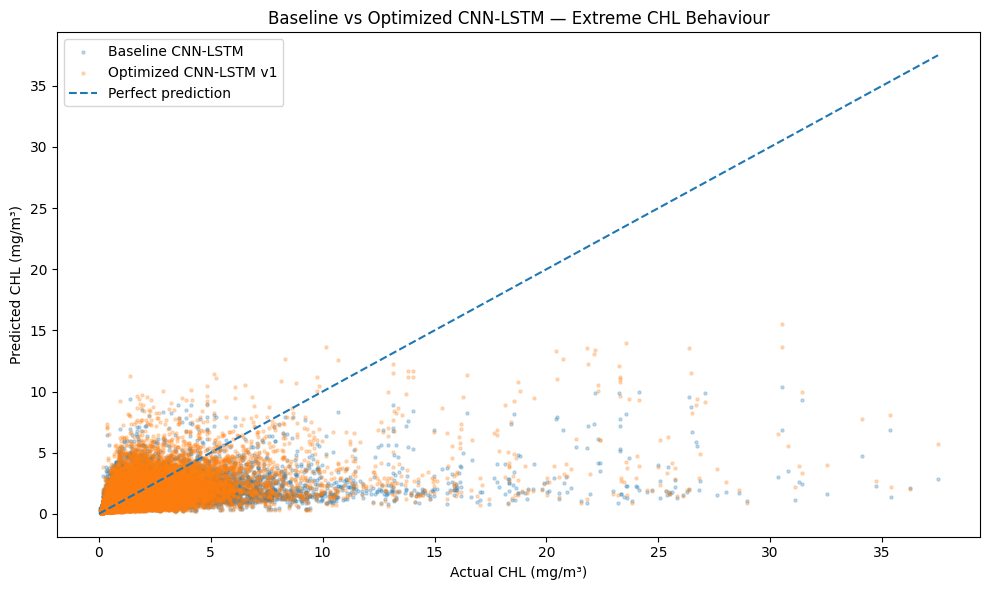

Plot saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/evaluation/cnn_lstm_baseline_vs_optimized_extreme_chl.png

SAVING 16D OUTPUTS
✓ Overall error summary saved.
✓ CHL-range analysis saved.
✓ Extreme-event analysis saved.
✓ Underprediction analysis saved.
✓ High-CHL detection analysis saved.
✓ Yearly extreme analysis saved.
✓ Largest-error tables saved.
✓ Complete validation error table saved.

FINAL 16D DIAGNOSTIC SUMMARY
Best overall MAE : Optimized CNN-LSTM v1
Best overall RMSE: Optimized CNN-LSTM v1
Best overall R²  : Optimized CNN-LSTM v1

Actual maximum CHL: 37.5017204284668 mg/m³
Baseline maximum prediction: 10.366289 mg/m³
Optimized maximum prediction: 15.531889 mg/m³

95th percentile threshold: 2.3158422 mg/m³

Final diagnostic summary saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/evaluation/cnn_lstm_optimized_v1_extreme_event_diagnostic_summary.json

STEP 31.9P-16D COMPLETE
✓ Baseline vs optim

In [ ]:
# ======================================================================
# STEP 31.9P-16D
# OPTIMIZED CNN-LSTM EXTREME-CHL / ERROR ANALYSIS
# BASELINE vs OPTIMIZED v1
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 70)
print("STEP 31.9P-16D")
print("OPTIMIZED CNN-LSTM EXTREME-CHL / ERROR ANALYSIS")
print("BASELINE vs OPTIMIZED v1")
print("=" * 70)

# ======================================================================
# 1. PATHS
# ======================================================================

PROJECT_DIR = (
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

BASELINE_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

OPTIMIZED_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

SEQUENCE_DIR = os.path.join(
    BASELINE_DIR,
    "sequences"
)

BASELINE_EVAL_DIR = os.path.join(
    BASELINE_DIR,
    "evaluation"
)

OPTIMIZED_EVAL_DIR = os.path.join(
    OPTIMIZED_DIR,
    "evaluation"
)

os.makedirs(
    OPTIMIZED_EVAL_DIR,
    exist_ok=True
)

# ======================================================================
# 2. REQUIRED FILES
# ======================================================================

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {

    "Validation target":
        os.path.join(
            SEQUENCE_DIR,
            "cnn_lstm_y_original_validation.npy"
        ),

    "Validation log target":
        os.path.join(
            SEQUENCE_DIR,
            "cnn_lstm_y_log_validation.npy"
        ),

    "Validation metadata":
        os.path.join(
            SEQUENCE_DIR,
            "cnn_lstm_metadata_validation.csv"
        ),

    "Baseline validation predictions":
        os.path.join(
            BASELINE_DIR,
            "cnn_lstm_validation_predictions.csv"
        ),

    "Optimized validation predictions":
        os.path.join(
            OPTIMIZED_DIR,
            "cnn_lstm_optimized_v1_validation_predictions.csv"
        )
}

for name, path in required_files.items():

    print(f"\n{name}:")
    print(path)
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required files found.")

# ======================================================================
# 3. TEST DATA SAFETY
# ======================================================================

print("\n" + "=" * 70)
print("TEST DATA SAFETY")
print("=" * 70)

print("Test data will NOT be loaded.")
print("Test predictions will NOT be generated.")
print("Test metrics will NOT be calculated.")

print("\n✓ Validation data only.")

# ======================================================================
# 4. LOAD VALIDATION TARGETS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING VALIDATION TARGETS")
print("=" * 70)

y_val_original = np.load(
    required_files["Validation target"]
)

y_val_log = np.load(
    required_files["Validation log target"]
)

metadata = pd.read_csv(
    required_files["Validation metadata"]
)

print(
    "Validation observations:",
    len(y_val_original)
)

print(
    "Validation metadata:",
    metadata.shape
)

# ======================================================================
# 5. LOAD PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING BASELINE AND OPTIMIZED PREDICTIONS")
print("=" * 70)

baseline_df = pd.read_csv(
    required_files["Baseline validation predictions"]
)

optimized_df = pd.read_csv(
    required_files["Optimized validation predictions"]
)

print(
    "Baseline prediction rows:",
    len(baseline_df)
)

print(
    "Optimized prediction rows:",
    len(optimized_df)
)

# ======================================================================
# 6. EXTRACT PREDICTION COLUMNS
# ======================================================================

baseline_pred = (
    baseline_df[
        "predicted_chlorophyll_a"
    ].to_numpy()
)

optimized_pred = (
    optimized_df[
        "optimized_predicted_chlorophyll_a"
    ].to_numpy()
)

# ======================================================================
# 7. ALIGNMENT CHECK
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION ALIGNMENT CHECK")
print("=" * 70)

print(
    "Actual target rows:",
    len(y_val_original)
)

print(
    "Baseline prediction rows:",
    len(baseline_pred)
)

print(
    "Optimized prediction rows:",
    len(optimized_pred)
)

if not (
    len(y_val_original)
    == len(baseline_pred)
    == len(optimized_pred)
):

    raise ValueError(
        "Baseline, optimized and actual validation "
        "arrays have different lengths."
    )

print("\n✓ All validation predictions are aligned.")

# ======================================================================
# 8. BUILD COMMON ANALYSIS TABLE
# ======================================================================

analysis = pd.DataFrame({

    "target_date":
        metadata["target_date"].astype(str),

    "latitude":
        metadata["latitude"].values,

    "longitude":
        metadata["longitude"].values,

    "actual_chlorophyll_a":
        y_val_original,

    "baseline_predicted_chlorophyll_a":
        baseline_pred,

    "optimized_predicted_chlorophyll_a":
        optimized_pred
})

analysis[
    "baseline_error"
] = (
    analysis[
        "baseline_predicted_chlorophyll_a"
    ]
    -
    analysis[
        "actual_chlorophyll_a"
    ]
)

analysis[
    "optimized_error"
] = (
    analysis[
        "optimized_predicted_chlorophyll_a"
    ]
    -
    analysis[
        "actual_chlorophyll_a"
    ]
)

analysis[
    "baseline_absolute_error"
] = np.abs(
    analysis[
        "baseline_error"
    ]
)

analysis[
    "optimized_absolute_error"
] = np.abs(
    analysis[
        "optimized_error"
    ]
)

print("\n✓ Common validation analysis table created.")

# ======================================================================
# 9. OVERALL ERROR SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("OVERALL ERROR SUMMARY")
print("=" * 70)

overall_rows = []

for model_name, prediction_column in [

    (
        "Baseline CNN-LSTM",
        "baseline_predicted_chlorophyll_a"
    ),

    (
        "Optimized CNN-LSTM v1",
        "optimized_predicted_chlorophyll_a"
    )

]:

    actual = analysis[
        "actual_chlorophyll_a"
    ].values

    predicted = analysis[
        prediction_column
    ].values

    error = predicted - actual

    overall_rows.append({

        "model":
            model_name,

        "MAE":
            mean_absolute_error(
                actual,
                predicted
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    actual,
                    predicted
                )
            ),

        "R2":
            r2_score(
                actual,
                predicted
            ),

        "Bias":
            np.mean(error),

        "Median_AE":
            np.median(
                np.abs(error)
            ),

        "Actual_Max":
            np.max(actual),

        "Predicted_Max":
            np.max(predicted),

        "Maximum_Absolute_Error":
            np.max(
                np.abs(error)
            )
    })

overall_summary = pd.DataFrame(
    overall_rows
)

print(
    overall_summary.to_string(
        index=False
    )
)

# ======================================================================
# 10. TRAINING-DERIVED PERCENTILE THRESHOLDS
# ======================================================================

print("\n" + "=" * 70)
print("EXTREME CHL THRESHOLDS")
print("=" * 70)

# IMPORTANT:
# Thresholds are calculated from the validation actual CHL here only
# for diagnostic comparison.
#
# They are NOT used to train either model.

percentiles = [75, 90, 95, 99]

thresholds = {}

for percentile in percentiles:

    threshold = np.percentile(
        y_val_original,
        percentile
    )

    thresholds[
        percentile
    ] = threshold

    print(
        f"{percentile}th percentile: "
        f"{threshold:.6f} mg/m³"
    )

# ======================================================================
# 11. ERROR BY CHL RANGE
# ======================================================================

print("\n" + "=" * 70)
print("ERROR BY ACTUAL CHL RANGE")
print("=" * 70)

bins = [
    -np.inf,
    0.2,
    0.5,
    1,
    2,
    5,
    10,
    np.inf
]

labels = [
    "0–0.2",
    "0.2–0.5",
    "0.5–1",
    "1–2",
    "2–5",
    "5–10",
    ">10"
]

analysis[
    "chl_range"
] = pd.cut(
    analysis[
        "actual_chlorophyll_a"
    ],
    bins=bins,
    labels=labels,
    right=False
)

range_results = []

for chl_range, group in analysis.groupby(
    "chl_range",
    observed=False
):

    if len(group) == 0:
        continue

    actual = group[
        "actual_chlorophyll_a"
    ].values

    baseline = group[
        "baseline_predicted_chlorophyll_a"
    ].values

    optimized = group[
        "optimized_predicted_chlorophyll_a"
    ].values

    range_results.append({

        "chl_range":
            str(chl_range),

        "observations":
            len(group),

        "actual_mean":
            np.mean(actual),

        "baseline_mean":
            np.mean(baseline),

        "optimized_mean":
            np.mean(optimized),

        "baseline_MAE":
            mean_absolute_error(
                actual,
                baseline
            ),

        "optimized_MAE":
            mean_absolute_error(
                actual,
                optimized
            ),

        "baseline_RMSE":
            np.sqrt(
                mean_squared_error(
                    actual,
                    baseline
                )
            ),

        "optimized_RMSE":
            np.sqrt(
                mean_squared_error(
                    actual,
                    optimized
                )
            ),

        "baseline_bias":
            np.mean(
                baseline - actual
            ),

        "optimized_bias":
            np.mean(
                optimized - actual
            )
    })

range_summary = pd.DataFrame(
    range_results
)

print(
    range_summary.to_string(
        index=False
    )
)

# ======================================================================
# 12. PERCENTILE EXTREME-EVENT ANALYSIS
# ======================================================================

print("\n" + "=" * 70)
print("EXTREME-EVENT PERCENTILE ANALYSIS")
print("=" * 70)

extreme_results = []

for percentile in percentiles:

    threshold = thresholds[
        percentile
    ]

    event = analysis[
        analysis[
            "actual_chlorophyll_a"
        ] >= threshold
    ]

    actual = event[
        "actual_chlorophyll_a"
    ].values

    baseline = event[
        "baseline_predicted_chlorophyll_a"
    ].values

    optimized = event[
        "optimized_predicted_chlorophyll_a"
    ].values

    extreme_results.append({

        "percentile":
            percentile,

        "threshold_mg_m3":
            threshold,

        "event_observations":
            len(event),

        "baseline_MAE":
            mean_absolute_error(
                actual,
                baseline
            ),

        "optimized_MAE":
            mean_absolute_error(
                actual,
                optimized
            ),

        "baseline_RMSE":
            np.sqrt(
                mean_squared_error(
                    actual,
                    baseline
                )
            ),

        "optimized_RMSE":
            np.sqrt(
                mean_squared_error(
                    actual,
                    optimized
                )
            ),

        "baseline_bias":
            np.mean(
                baseline - actual
            ),

        "optimized_bias":
            np.mean(
                optimized - actual
            ),

        "actual_mean":
            np.mean(actual),

        "baseline_mean":
            np.mean(baseline),

        "optimized_mean":
            np.mean(optimized),

        "actual_max":
            np.max(actual),

        "baseline_max":
            np.max(baseline),

        "optimized_max":
            np.max(optimized)
    })

extreme_summary = pd.DataFrame(
    extreme_results
)

print(
    extreme_summary.to_string(
        index=False
    )
)

# ======================================================================
# 13. EXTREME EVENT UNDERPREDICTION
# ======================================================================

print("\n" + "=" * 70)
print("EXTREME EVENT UNDERPREDICTION")
print("=" * 70)

underprediction_rows = []

for percentile in percentiles:

    threshold = thresholds[
        percentile
    ]

    event = analysis[
        analysis[
            "actual_chlorophyll_a"
        ] >= threshold
    ]

    actual = event[
        "actual_chlorophyll_a"
    ].values

    baseline = event[
        "baseline_predicted_chlorophyll_a"
    ].values

    optimized = event[
        "optimized_predicted_chlorophyll_a"
    ].values

    baseline_under = (
        baseline < actual
    )

    optimized_under = (
        optimized < actual
    )

    underprediction_rows.append({

        "percentile":
            percentile,

        "threshold_mg_m3":
            threshold,

        "baseline_underprediction_pct":
            100 * np.mean(
                baseline_under
            ),

        "optimized_underprediction_pct":
            100 * np.mean(
                optimized_under
            ),

        "baseline_mean_underprediction":
            np.mean(
                actual[baseline_under]
                - baseline[baseline_under]
            )
            if np.any(baseline_under)
            else 0,

        "optimized_mean_underprediction":
            np.mean(
                actual[optimized_under]
                - optimized[optimized_under]
            )
            if np.any(optimized_under)
            else 0
    })

underprediction_summary = pd.DataFrame(
    underprediction_rows
)

print(
    underprediction_summary.to_string(
        index=False
    )
)

# ======================================================================
# 14. LARGEST PREDICTION ERRORS
# ======================================================================

print("\n" + "=" * 70)
print("LARGEST PREDICTION ERRORS")
print("=" * 70)

baseline_largest = (
    analysis
    .sort_values(
        "baseline_absolute_error",
        ascending=False
    )
    .head(20)
    [
        [
            "target_date",
            "latitude",
            "longitude",
            "actual_chlorophyll_a",
            "baseline_predicted_chlorophyll_a",
            "baseline_error",
            "baseline_absolute_error"
        ]
    ]
)

optimized_largest = (
    analysis
    .sort_values(
        "optimized_absolute_error",
        ascending=False
    )
    .head(20)
    [
        [
            "target_date",
            "latitude",
            "longitude",
            "actual_chlorophyll_a",
            "optimized_predicted_chlorophyll_a",
            "optimized_error",
            "optimized_absolute_error"
        ]
    ]
)

print("\nBASELINE TOP 20:")
print(
    baseline_largest.to_string(
        index=False
    )
)

print("\nOPTIMIZED v1 TOP 20:")
print(
    optimized_largest.to_string(
        index=False
    )
)

# ======================================================================
# 15. MAXIMUM CHL COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("MAXIMUM CHL REPRESENTATION")
print("=" * 70)

actual_max = np.max(
    analysis[
        "actual_chlorophyll_a"
    ]
)

baseline_max = np.max(
    analysis[
        "baseline_predicted_chlorophyll_a"
    ]
)

optimized_max = np.max(
    analysis[
        "optimized_predicted_chlorophyll_a"
    ]
)

print(
    f"Actual maximum CHL    : "
    f"{actual_max:.6f} mg/m³"
)

print(
    f"Baseline maximum      : "
    f"{baseline_max:.6f} mg/m³"
)

print(
    f"Optimized v1 maximum  : "
    f"{optimized_max:.6f} mg/m³"
)

print(
    "\nBaseline maximum / actual maximum:"
)

print(
    f"{100 * baseline_max / actual_max:.2f}%"
)

print(
    "\nOptimized maximum / actual maximum:"
)

print(
    f"{100 * optimized_max / actual_max:.2f}%"
)

# ======================================================================
# 16. HIGH-CHL DETECTION
# ======================================================================

print("\n" + "=" * 70)
print("HIGH-CHL EVENT DETECTION")
print("=" * 70)

detection_results = []

for percentile in percentiles:

    threshold = thresholds[
        percentile
    ]

    actual_event = (
        analysis[
            "actual_chlorophyll_a"
        ] >= threshold
    )

    baseline_event = (
        analysis[
            "baseline_predicted_chlorophyll_a"
        ] >= threshold
    )

    optimized_event = (
        analysis[
            "optimized_predicted_chlorophyll_a"
        ] >= threshold
    )

    def classification_metrics(
        actual_event,
        predicted_event
    ):

        tp = np.sum(
            actual_event
            & predicted_event
        )

        fp = np.sum(
            (~actual_event)
            & predicted_event
        )

        fn = np.sum(
            actual_event
            & (~predicted_event)
        )

        tn = np.sum(
            (~actual_event)
            & (~predicted_event)
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        return (
            tp,
            fp,
            fn,
            tn,
            precision,
            recall,
            f1
        )

    (
        b_tp,
        b_fp,
        b_fn,
        b_tn,
        b_precision,
        b_recall,
        b_f1
    ) = classification_metrics(
        actual_event,
        baseline_event
    )

    (
        o_tp,
        o_fp,
        o_fn,
        o_tn,
        o_precision,
        o_recall,
        o_f1
    ) = classification_metrics(
        actual_event,
        optimized_event
    )

    detection_results.append({

        "percentile":
            percentile,

        "threshold_mg_m3":
            threshold,

        "baseline_precision":
            b_precision,

        "optimized_precision":
            o_precision,

        "baseline_recall":
            b_recall,

        "optimized_recall":
            o_recall,

        "baseline_F1":
            b_f1,

        "optimized_F1":
            o_f1,

        "baseline_TP":
            b_tp,

        "optimized_TP":
            o_tp,

        "baseline_FN":
            b_fn,

        "optimized_FN":
            o_fn
    })

detection_summary = pd.DataFrame(
    detection_results
)

print(
    detection_summary.to_string(
        index=False
    )
)

# ======================================================================
# 17. YEARLY EXTREME PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("YEARLY HIGH-CHL PERFORMANCE")
print("=" * 70)

analysis[
    "year"
] = pd.to_datetime(
    analysis[
        "target_date"
    ]
).dt.year

yearly_rows = []

# Use the 95th percentile as the high-CHL diagnostic threshold.

high_threshold = thresholds[95]

for year, group in analysis.groupby(
    "year"
):

    event = group[
        group[
            "actual_chlorophyll_a"
        ] >= high_threshold
    ]

    if len(event) == 0:
        continue

    actual = event[
        "actual_chlorophyll_a"
    ].values

    baseline = event[
        "baseline_predicted_chlorophyll_a"
    ].values

    optimized = event[
        "optimized_predicted_chlorophyll_a"
    ].values

    yearly_rows.append({

        "year":
            year,

        "high_chl_observations":
            len(event),

        "baseline_MAE":
            mean_absolute_error(
                actual,
                baseline
            ),

        "optimized_MAE":
            mean_absolute_error(
                actual,
                optimized
            ),

        "baseline_RMSE":
            np.sqrt(
                mean_squared_error(
                    actual,
                    baseline
                )
            ),

        "optimized_RMSE":
            np.sqrt(
                mean_squared_error(
                    actual,
                    optimized
                )
            ),

        "baseline_bias":
            np.mean(
                baseline - actual
            ),

        "optimized_bias":
            np.mean(
                optimized - actual
            ),

        "actual_max":
            np.max(actual),

        "baseline_max":
            np.max(baseline),

        "optimized_max":
            np.max(optimized)
    })

yearly_extreme_summary = pd.DataFrame(
    yearly_rows
)

print(
    yearly_extreme_summary.to_string(
        index=False
    )
)

# ======================================================================
# 18. EXTREME EVENT VISUALIZATION
# ======================================================================

print("\n" + "=" * 70)
print("CREATING EXTREME EVENT VISUALIZATION")
print("=" * 70)

plt.figure(
    figsize=(10, 6)
)

plt.scatter(
    y_val_original,
    baseline_pred,
    s=5,
    alpha=0.25,
    label="Baseline CNN-LSTM"
)

plt.scatter(
    y_val_original,
    optimized_pred,
    s=5,
    alpha=0.25,
    label="Optimized CNN-LSTM v1"
)

max_plot = max(
    np.max(y_val_original),
    np.max(baseline_pred),
    np.max(optimized_pred)
)

plt.plot(
    [0, max_plot],
    [0, max_plot],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel(
    "Actual CHL (mg/m³)"
)

plt.ylabel(
    "Predicted CHL (mg/m³)"
)

plt.title(
    "Baseline vs Optimized CNN-LSTM — Extreme CHL Behaviour"
)

plt.legend()

plt.tight_layout()

plot_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_extreme_chl.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Plot saved:"
)

print(plot_path)

# ======================================================================
# 19. SAVE OUTPUTS
# ======================================================================

print("\n" + "=" * 70)
print("SAVING 16D OUTPUTS")
print("=" * 70)

overall_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_error_summary.csv"
)

range_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_error_by_chl_range.csv"
)

extreme_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_extreme_event_analysis.csv"
)

underprediction_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_extreme_underprediction.csv"
)

detection_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_high_chl_detection.csv"
)

yearly_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_yearly_extreme_performance.csv"
)

largest_baseline_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "baseline_cnn_lstm_largest_errors_top20.csv"
)

largest_optimized_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "optimized_cnn_lstm_v1_largest_errors_top20.csv"
)

analysis_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_baseline_vs_optimized_validation_error_analysis.csv"
)

overall_summary.to_csv(
    overall_path,
    index=False
)

range_summary.to_csv(
    range_path,
    index=False
)

extreme_summary.to_csv(
    extreme_path,
    index=False
)

underprediction_summary.to_csv(
    underprediction_path,
    index=False
)

detection_summary.to_csv(
    detection_path,
    index=False
)

yearly_extreme_summary.to_csv(
    yearly_path,
    index=False
)

baseline_largest.to_csv(
    largest_baseline_path,
    index=False
)

optimized_largest.to_csv(
    largest_optimized_path,
    index=False
)

analysis.to_csv(
    analysis_path,
    index=False
)

print("✓ Overall error summary saved.")
print("✓ CHL-range analysis saved.")
print("✓ Extreme-event analysis saved.")
print("✓ Underprediction analysis saved.")
print("✓ High-CHL detection analysis saved.")
print("✓ Yearly extreme analysis saved.")
print("✓ Largest-error tables saved.")
print("✓ Complete validation error table saved.")

# ======================================================================
# 20. FINAL DIAGNOSTIC SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("FINAL 16D DIAGNOSTIC SUMMARY")
print("=" * 70)

best_mae_model = (
    "Optimized CNN-LSTM v1"
    if overall_summary.loc[
        overall_summary["MAE"].idxmin(),
        "model"
    ] == "Optimized CNN-LSTM v1"
    else
    "Baseline CNN-LSTM"
)

best_rmse_model = (
    "Optimized CNN-LSTM v1"
    if overall_summary.loc[
        overall_summary["RMSE"].idxmin(),
        "model"
    ] == "Optimized CNN-LSTM v1"
    else
    "Baseline CNN-LSTM"
)

best_r2_model = (
    "Optimized CNN-LSTM v1"
    if overall_summary.loc[
        overall_summary["R2"].idxmax(),
        "model"
    ] == "Optimized CNN-LSTM v1"
    else
    "Baseline CNN-LSTM"
)

print(
    "Best overall MAE :",
    best_mae_model
)

print(
    "Best overall RMSE:",
    best_rmse_model
)

print(
    "Best overall R²  :",
    best_r2_model
)

print(
    "\nActual maximum CHL:",
    actual_max,
    "mg/m³"
)

print(
    "Baseline maximum prediction:",
    baseline_max,
    "mg/m³"
)

print(
    "Optimized maximum prediction:",
    optimized_max,
    "mg/m³"
)

print(
    "\n95th percentile threshold:",
    high_threshold,
    "mg/m³"
)

# ======================================================================
# 21. SAVE FINAL SUMMARY JSON
# ======================================================================

def json_safe(obj):

    if isinstance(obj, dict):
        return {
            str(k): json_safe(v)
            for k, v in obj.items()
        }

    if isinstance(obj, list):
        return [
            json_safe(v)
            for v in obj
        ]

    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, np.floating):
        return float(obj)

    if isinstance(obj, np.bool_):
        return bool(obj)

    return obj


diagnostic_summary = {

    "experiment":
        "31.9P-16D",

    "validation_only":
        True,

    "test_data_used":
        False,

    "actual_max_chl":
        actual_max,

    "baseline_max_prediction":
        baseline_max,

    "optimized_max_prediction":
        optimized_max,

    "best_overall_MAE":
        best_mae_model,

    "best_overall_RMSE":
        best_rmse_model,

    "best_overall_R2":
        best_r2_model,

    "percentile_thresholds":
        thresholds,

    "extreme_event_analysis":
        extreme_summary.to_dict(
            orient="records"
        ),

    "high_chl_detection":
        detection_summary.to_dict(
            orient="records"
        )
}

diagnostic_summary = json_safe(
    diagnostic_summary
)

summary_json_path = os.path.join(
    OPTIMIZED_EVAL_DIR,
    "cnn_lstm_optimized_v1_extreme_event_diagnostic_summary.json"
)

with open(
    summary_json_path,
    "w"
) as f:

    json.dump(
        diagnostic_summary,
        f,
        indent=4
    )

print(
    "\nFinal diagnostic summary saved:"
)

print(summary_json_path)

# ======================================================================
# COMPLETE
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-16D COMPLETE")
print("=" * 70)

print("✓ Baseline vs optimized error analysis completed.")
print("✓ CHL-range performance analysed.")
print("✓ 75th percentile analysed.")
print("✓ 90th percentile analysed.")
print("✓ 95th percentile analysed.")
print("✓ 99th percentile analysed.")
print("✓ Extreme-event errors analysed.")
print("✓ Underprediction analysed.")
print("✓ Maximum CHL representation analysed.")
print("✓ High-CHL detection analysed.")
print("✓ Yearly high-CHL behaviour analysed.")
print("✓ Largest errors identified.")
print("✓ Diagnostic plot generated.")
print("✓ All outputs saved.")
print("✓ Test data was NOT used.")
print("✓ No model was retrained.")
print("✓ No model was modified.")

In [ ]:
# ======================================================================
# STEP 31.9P-16E
# OPTIMIZED CNN-LSTM v2 — ARCHITECTURE DESIGN
# ======================================================================

import os
import json
import random
import numpy as np
import tensorflow as tf

print("=" * 70)
print("STEP 31.9P-16E")
print("OPTIMIZED CNN-LSTM v2 — ARCHITECTURE DESIGN")
print("=" * 70)

# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

EXISTING_CNN_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

OPTIMIZED_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

V2_DIR = os.path.join(
    OPTIMIZED_DIR,
    "v2"
)

ARCH_DIR = os.path.join(
    V2_DIR,
    "architectures"
)

EVAL_DIR = os.path.join(
    V2_DIR,
    "evaluation"
)

os.makedirs(ARCH_DIR, exist_ok=True)
os.makedirs(EVAL_DIR, exist_ok=True)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nOriginal CNN-LSTM directory:")
print(EXISTING_CNN_DIR)

print("\nOptimized CNN-LSTM directory:")
print(OPTIMIZED_DIR)

print("\nCNN-LSTM v2 directory:")
print(V2_DIR)

# ======================================================================
# REPRODUCIBILITY
# ======================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\n" + "=" * 70)
print("REPRODUCIBILITY")
print("=" * 70)

print("Random seed:", SEED)

# ======================================================================
# GPU VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print("Number of GPUs detected:", len(gpus))

for gpu in gpus:
    print("GPU:", gpu)

if len(gpus) == 0:
    raise RuntimeError("No GPU detected.")

print("✓ TensorFlow GPU available.")

# ======================================================================
# ARCHITECTURE CONFIGURATION
# ======================================================================

SEQUENCE_LENGTH = 7
NUM_FEATURES = 69

CNN_FILTERS = 64
CNN_KERNEL_SIZE = 3

LSTM_UNITS = 128

DROPOUT_RATE = 0.20
DENSE_UNITS = 32

TARGET = "chlorophyll_a_log1p"

print("\n" + "=" * 70)
print("CNN-LSTM v2 CONFIGURATION")
print("=" * 70)

print("Sequence length :", SEQUENCE_LENGTH)
print("Number features :", NUM_FEATURES)
print("Input shape     :", (SEQUENCE_LENGTH, NUM_FEATURES))

print("CNN filters     :", CNN_FILTERS)
print("CNN kernel size :", CNN_KERNEL_SIZE)

print("LSTM units      :", LSTM_UNITS)

print("Dropout         :", DROPOUT_RATE)
print("Dense units     :", DENSE_UNITS)

print("Target          :", TARGET)

# ======================================================================
# ARCHITECTURE COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("ARCHITECTURE COMPARISON")
print("=" * 70)

print("""
BASELINE CNN-LSTM:

Input (7, 69)
      ↓
Conv1D (64 filters, kernel=3)
      ↓
MaxPooling1D(pool=2)
      ↓
LSTM (64)
      ↓
Dropout (0.20)
      ↓
Dense (32)
      ↓
Linear output


OPTIMIZED CNN-LSTM v1:

Input (7, 69)
      ↓
Conv1D (64 filters, kernel=3)
      ↓
NO MAX POOLING
      ↓
LSTM (64)
      ↓
Dropout (0.20)
      ↓
Dense (32)
      ↓
Linear output


OPTIMIZED CNN-LSTM v2:

Input (7, 69)
      ↓
Conv1D (64 filters, kernel=3)
      ↓
NO MAX POOLING
      ↓
LSTM (128)       ← EXPERIMENTAL CHANGE
      ↓
Dropout (0.20)
      ↓
Dense (32)
      ↓
Linear output
""")

print("✓ v2 preserves the successful v1 design.")
print("✓ Only LSTM capacity is increased from 64 to 128 units.")

# ======================================================================
# BUILD MODEL
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING CNN-LSTM v2")
print("=" * 70)

model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(
            shape=(SEQUENCE_LENGTH, NUM_FEATURES)
        ),

        tf.keras.layers.Conv1D(
            filters=CNN_FILTERS,
            kernel_size=CNN_KERNEL_SIZE,
            activation="relu",
            padding="same",
            name="cnn_conv1d"
        ),

        # IMPORTANT:
        # No MaxPooling layer.

        tf.keras.layers.LSTM(
            LSTM_UNITS,
            name="lstm"
        ),

        tf.keras.layers.Dropout(
            DROPOUT_RATE,
            name="dropout"
        ),

        tf.keras.layers.Dense(
            DENSE_UNITS,
            activation="relu",
            name="dense"
        ),

        tf.keras.layers.Dense(
            1,
            activation="linear",
            name="output_chl_log1p"
        )
    ],
    name="CNN_LSTM_CHL_Optimized_v2"
)

# ======================================================================
# MODEL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("MODEL SUMMARY")
print("=" * 70)

model.summary()

# ======================================================================
# PARAMETER COUNT
# ======================================================================

total_params = model.count_params()

print("\n" + "=" * 70)
print("MODEL PARAMETER COUNT")
print("=" * 70)

print("Total parameters:", total_params)
print("Trainable parameters:", total_params)

# ======================================================================
# EXPECTED PARAMETER VERIFICATION
# ======================================================================

conv_params = (
    CNN_KERNEL_SIZE *
    NUM_FEATURES *
    CNN_FILTERS
    + CNN_FILTERS
)

lstm_params = (
    4 *
    (CNN_FILTERS + LSTM_UNITS + 1) *
    LSTM_UNITS
)

dense_params = (
    LSTM_UNITS *
    DENSE_UNITS
    + DENSE_UNITS
)

output_params = DENSE_UNITS + 1

expected_params = (
    conv_params +
    lstm_params +
    dense_params +
    output_params
)

print("\nParameter verification:")
print("Conv1D parameters :", conv_params)
print("LSTM parameters   :", lstm_params)
print("Dense parameters  :", dense_params)
print("Output parameters :", output_params)
print("Expected total    :", expected_params)
print("Actual total      :", total_params)

if expected_params != total_params:
    raise RuntimeError(
        "Parameter count verification failed."
    )

print("✓ Parameter count verified.")

# ======================================================================
# ARCHITECTURE VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("ARCHITECTURE VERIFICATION")
print("=" * 70)

layer_names = [layer.name for layer in model.layers]

print("Model layers:")

for layer_name in layer_names:
    print(" -", layer_name)

# Check MaxPooling is absent
pooling_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.MaxPooling1D)
]

if len(pooling_layers) != 0:
    raise RuntimeError(
        "MaxPooling1D unexpectedly exists in v2."
    )

print("✓ No MaxPooling1D layer present.")

# Check Conv1D
conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv1D)
]

if len(conv_layers) != 1:
    raise RuntimeError(
        "Expected exactly one Conv1D layer."
    )

print("✓ One Conv1D layer present.")

# Check LSTM
lstm_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.LSTM)
]

if len(lstm_layers) != 1:
    raise RuntimeError(
        "Expected exactly one LSTM layer."
    )

if lstm_layers[0].units != 128:
    raise RuntimeError(
        "LSTM does not have 128 units."
    )

print("✓ One LSTM layer present.")
print("✓ LSTM units confirmed: 128.")

# ======================================================================
# OUTPUT SHAPE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("OUTPUT SHAPE CHECK")
print("=" * 70)

dummy_input = np.zeros(
    (1, SEQUENCE_LENGTH, NUM_FEATURES),
    dtype=np.float32
)

dummy_output = model(dummy_input, training=False)

print("Dummy input shape :", dummy_input.shape)
print("Dummy output shape:", dummy_output.shape)

if tuple(dummy_output.shape) != (1, 1):
    raise RuntimeError(
        "Unexpected model output shape."
    )

print("✓ Output shape correctly configured as (1, 1).")

# ======================================================================
# ARCHITECTURE METADATA
# ======================================================================

architecture_config = {
    "experiment": "31.9P-16E",
    "model_name": "CNN_LSTM_CHL_Optimized_v2",

    "sequence_length": int(SEQUENCE_LENGTH),
    "number_of_features": int(NUM_FEATURES),

    "cnn_filters": int(CNN_FILTERS),
    "cnn_kernel_size": int(CNN_KERNEL_SIZE),

    "max_pooling": False,

    "lstm_units": int(LSTM_UNITS),

    "dropout_rate": float(DROPOUT_RATE),
    "dense_units": int(DENSE_UNITS),

    "target": TARGET,
    "output_activation": "linear",

    "total_parameters": int(total_params),
    "trainable_parameters": int(total_params),

    "random_seed": int(SEED),

    "experimental_change": (
        "Increase LSTM units from 64 in v1 to 128 "
        "while preserving the no-MaxPooling architecture."
    ),

    "training_performed": False,
    "validation_used": False,
    "test_data_used": False
}

architecture_json = os.path.join(
    ARCH_DIR,
    "cnn_lstm_optimized_v2_architecture.json"
)

with open(architecture_json, "w") as f:
    json.dump(
        architecture_config,
        f,
        indent=4
    )

print("\n" + "=" * 70)
print("ARCHITECTURE CONFIGURATION SAVED")
print("=" * 70)

print(architecture_json)

# ======================================================================
# SAVE UNTRAINED MODEL
# ======================================================================

untrained_model_path = os.path.join(
    ARCH_DIR,
    "cnn_lstm_optimized_v2_untrained.keras"
)

model.save(untrained_model_path)

print("\nUntrained model saved:")
print(untrained_model_path)

# ======================================================================
# SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("SAFETY CHECK")
print("=" * 70)

print("Original CNN-LSTM modified:", False)
print("Optimized v1 modified:", False)
print("XGBoost modified:", False)

print("Training performed:", False)
print("Validation data used:", False)
print("Test data used:", False)

print("✓ Existing baseline preserved.")
print("✓ Optimized v1 preserved.")
print("✓ XGBoost preserved.")
print("✓ No training performed.")
print("✓ No validation selection performed.")
print("✓ Test data was not loaded.")

# ======================================================================
# FINAL
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-16E COMPLETE")
print("=" * 70)

print("✓ CNN-LSTM v2 architecture created.")
print("✓ 7-day sequence preserved.")
print("✓ 69 predictors preserved.")
print("✓ Conv1D configuration preserved.")
print("✓ MaxPooling remains removed.")
print("✓ LSTM increased from 64 → 128 units.")
print("✓ Dropout preserved.")
print("✓ Dense layer preserved.")
print("✓ Target preserved.")
print("✓ Parameter count verified.")
print("✓ Architecture saved.")
print("✓ Untrained model saved.")
print("✓ Test data NOT used.")

print("\nArchitecture configuration:")
print(architecture_json)

print("\nUntrained model:")
print(untrained_model_path)

STEP 31.9P-16E
OPTIMIZED CNN-LSTM v2 — ARCHITECTURE DESIGN

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

Original CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM

Optimized CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized

CNN-LSTM v2 directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2

REPRODUCIBILITY
Random seed: 42

GPU VERIFICATION
Number of GPUs detected: 1
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
✓ TensorFlow GPU available.

CNN-LSTM v2 CONFIGURATION
Sequence length : 7
Number features : 69
Input shape     : (7, 69)
CNN filters     : 64
CNN kernel size : 3
LSTM units      : 128
Dropout         : 0.2
Dense units     : 32
Target          : chlorophyll_a_log1p

ARCHITECTURE COMPARISON

BASELINE CNN-LSTM:

Input (7, 69)
      ↓
Conv1D (64 filters, kernel=3)
      ↓
MaxPooling1D(pool=2)
      

Model: "CNN_LSTM_CHL_Optimized_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cnn_conv1d (Conv1D)             │ (None, 7, 64)          │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_chl_log1p (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 116,289 (454.25 KB)

 Trainable params: 116,289 (454.25 KB)

 Non-trainable params: 0 (0.00 B)


MODEL PARAMETER COUNT
Total parameters: 116289
Trainable parameters: 116289

Parameter verification:
Conv1D parameters : 13312
LSTM parameters   : 98816
Dense parameters  : 4128
Output parameters : 33
Expected total    : 116289
Actual total      : 116289
✓ Parameter count verified.

ARCHITECTURE VERIFICATION
Model layers:
 - cnn_conv1d
 - lstm
 - dropout
 - dense
 - output_chl_log1p
✓ No MaxPooling1D layer present.
✓ One Conv1D layer present.
✓ One LSTM layer present.
✓ LSTM units confirmed: 128.

OUTPUT SHAPE CHECK
Dummy input shape : (1, 7, 69)
Dummy output shape: (1, 1)
✓ Output shape correctly configured as (1, 1).

ARCHITECTURE CONFIGURATION SAVED
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/architectures/cnn_lstm_optimized_v2_architecture.json

Untrained model saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/architectures/cnn_lstm_optimized_v2_untrained.keras

SAFETY CHECK
Original CNN-LSTM modifi

In [ ]:
# ======================================================================
# STEP 31.9P-16F — TRAIN OPTIMIZED CNN-LSTM v2
# ======================================================================

import os
import json
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.losses import Huber
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

SEQUENCE_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM",
    "sequences"
)

V2_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized",
    "v2"
)

V2_MODEL_DIR = os.path.join(V2_DIR, "models")
V2_EVAL_DIR = os.path.join(V2_DIR, "evaluation")
V2_ARCH_DIR = os.path.join(V2_DIR, "architectures")

os.makedirs(V2_MODEL_DIR, exist_ok=True)
os.makedirs(V2_EVAL_DIR, exist_ok=True)
os.makedirs(V2_ARCH_DIR, exist_ok=True)

print("=" * 70)
print("STEP 31.9P-16F — TRAIN OPTIMIZED CNN-LSTM v2")
print("=" * 70)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nV2 directory:")
print(V2_DIR)

# ======================================================================
# REPRODUCIBILITY
# ======================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\n" + "=" * 70)
print("REPRODUCIBILITY")
print("=" * 70)

print("Random seed:", SEED)

# ======================================================================
# GPU VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("GPU VERIFICATION")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print("Number of GPUs detected:", len(gpus))

if len(gpus) == 0:
    raise RuntimeError(
        "No GPU detected. Please enable GPU runtime before training."
    )

for gpu in gpus:
    print("GPU:", gpu)

print("✓ TensorFlow GPU available.")

# ======================================================================
# REQUIRED FILES
# ======================================================================

X_train_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_training.npy"
)

y_train_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_training.npy"
)

X_val_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_validation.npy"
)

y_val_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_validation.npy"
)

v2_architecture_path = os.path.join(
    V2_ARCH_DIR,
    "cnn_lstm_optimized_v2_untrained.keras"
)

v2_best_model_path = os.path.join(
    V2_MODEL_DIR,
    "cnn_lstm_optimized_v2_best_model.keras"
)

v2_final_model_path = os.path.join(
    V2_MODEL_DIR,
    "cnn_lstm_optimized_v2_final_model.keras"
)

training_history_csv = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_optimized_v2_training_history.csv"
)

training_summary_json = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_optimized_v2_training_summary.json"
)

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Training X": X_train_path,
    "Training target": y_train_path,
    "Validation X": X_val_path,
    "Validation target": y_val_path,
    "V2 architecture": v2_architecture_path
}

for name, path in required_files.items():
    exists = os.path.exists(path)
    print(f"\n{name}:")
    print(path)
    print("Exists:", exists)

    if not exists:
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required training files found.")

# ======================================================================
# LOAD TRAINING AND VALIDATION SEQUENCES
# ======================================================================

print("\n" + "=" * 70)
print("LOADING TRAINING / VALIDATION SEQUENCES")
print("=" * 70)

X_train = np.load(X_train_path)
y_train = np.load(y_train_path)

X_val = np.load(X_val_path)
y_val = np.load(y_val_path)

print("\nTraining X shape:", X_train.shape)
print("Training y shape:", y_train.shape)

print("\nValidation X shape:", X_val.shape)
print("Validation y shape:", y_val.shape)

# ======================================================================
# SHAPE VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("SEQUENCE SHAPE VERIFICATION")
print("=" * 70)

expected_sequence_length = 7
expected_features = 69

if X_train.shape[1:] != (
    expected_sequence_length,
    expected_features
):
    raise ValueError(
        f"Unexpected training shape: {X_train.shape}"
    )

if X_val.shape[1:] != (
    expected_sequence_length,
    expected_features
):
    raise ValueError(
        f"Unexpected validation shape: {X_val.shape}"
    )

if X_train.shape[0] != y_train.shape[0]:
    raise ValueError("Training X/y lengths do not match.")

if X_val.shape[0] != y_val.shape[0]:
    raise ValueError("Validation X/y lengths do not match.")

print("✓ Training shape verified.")
print("✓ Validation shape verified.")
print("✓ 7-day sequences confirmed.")
print("✓ 69 predictors confirmed.")

# ======================================================================
# SAFETY CHECKS
# ======================================================================

print("\n" + "=" * 70)
print("TRAINING DATA SAFETY CHECK")
print("=" * 70)

print("Training X NaN:", np.isnan(X_train).sum())
print("Training X infinite:", np.isinf(X_train).sum())
print("Training y NaN:", np.isnan(y_train).sum())
print("Training y infinite:", np.isinf(y_train).sum())

print("\nValidation X NaN:", np.isnan(X_val).sum())
print("Validation X infinite:", np.isinf(X_val).sum())
print("Validation y NaN:", np.isnan(y_val).sum())
print("Validation y infinite:", np.isinf(y_val).sum())

if (
    np.isnan(X_train).any()
    or np.isinf(X_train).any()
    or np.isnan(y_train).any()
    or np.isinf(y_train).any()
    or np.isnan(X_val).any()
    or np.isinf(X_val).any()
    or np.isnan(y_val).any()
    or np.isinf(y_val).any()
):
    raise ValueError(
        "NaN or infinite values detected."
    )

print("\n✓ Training and validation data passed safety checks.")

# ======================================================================
# LOAD V2 ARCHITECTURE
# ======================================================================

print("\n" + "=" * 70)
print("LOADING CNN-LSTM v2 ARCHITECTURE")
print("=" * 70)

model = load_model(
    v2_architecture_path,
    compile=False
)

print("Model loaded:")
print(model.name)

print("\nModel layers:")

for layer in model.layers:
    print(
        f" - {layer.name}: "
        f"{layer.__class__.__name__}"
    )

# ======================================================================
# ARCHITECTURE VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("V2 ARCHITECTURE VERIFICATION")
print("=" * 70)

layer_names = [
    layer.__class__.__name__
    for layer in model.layers
]

if "MaxPooling1D" in layer_names:
    raise ValueError(
        "MaxPooling1D unexpectedly present in v2."
    )

print("✓ No MaxPooling1D layer.")

lstm_layers = [
    layer
    for layer in model.layers
    if isinstance(layer, tf.keras.layers.LSTM)
]

if len(lstm_layers) != 1:
    raise ValueError(
        "Expected exactly one LSTM layer."
    )

lstm_units = lstm_layers[0].units

print("LSTM units:", lstm_units)

if lstm_units != 128:
    raise ValueError(
        f"Expected 128 LSTM units, found {lstm_units}."
    )

print("✓ LSTM = 128 units.")

print("\nTrainable parameters:",
      model.count_params())

# ======================================================================
# COMPILE MODEL
# ======================================================================

print("\n" + "=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

LEARNING_RATE = 0.001
BATCH_SIZE = 512
MAX_EPOCHS = 100

EARLY_STOPPING_PATIENCE = 10

LR_PATIENCE = 5
LR_FACTOR = 0.5
MIN_LR = 1e-6

print("Loss function: Huber")
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:",
      EARLY_STOPPING_PATIENCE)
print("LR reduction patience:", LR_PATIENCE)
print("LR reduction factor:", LR_FACTOR)
print("Minimum learning rate:", MIN_LR)

model.compile(
    optimizer=Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=Huber()
)

print("\n✓ Model compiled.")

# ======================================================================
# CALLBACKS
# ======================================================================

print("\n" + "=" * 70)
print("CALLBACK CONFIGURATION")
print("=" * 70)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=v2_best_model_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr,
    checkpoint
]

print("✓ EarlyStopping configured.")
print("✓ ReduceLROnPlateau configured.")
print("✓ ModelCheckpoint configured.")

# ======================================================================
# IMPORTANT SAFETY STATEMENT
# ======================================================================

print("\n" + "=" * 70)
print("DATA USAGE SAFETY")
print("=" * 70)

print("Training data: USED")
print("Validation data: USED")
print("Test data: NOT LOADED")
print("Test data: NOT USED")

print("\n✓ Test set remains completely untouched.")

# ======================================================================
# TRAINING
# ======================================================================

print("\n" + "=" * 70)
print("STARTING CNN-LSTM v2 GPU TRAINING")
print("=" * 70)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)

start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
    shuffle=False
)

training_time = time.time() - start_time

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    f"Training time: "
    f"{training_time / 60:.2f} minutes"
)

# ======================================================================
# TRAINING HISTORY
# ======================================================================

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)

history_df.to_csv(
    training_history_csv,
    index=False
)

print("\nTraining history saved:")
print(training_history_csv)

# ======================================================================
# BEST EPOCH
# ======================================================================

best_epoch_index = int(
    np.argmin(
        history.history["val_loss"]
    )
)

best_epoch = best_epoch_index + 1

best_train_loss = float(
    history.history["loss"][best_epoch_index]
)

best_val_loss = float(
    history.history["val_loss"][best_epoch_index]
)

print("\n" + "=" * 70)
print("BEST VALIDATION PERFORMANCE")
print("=" * 70)

print("Best epoch:", best_epoch)
print("Best training loss:", best_train_loss)
print("Best validation loss:", best_val_loss)

# ======================================================================
# EARLY STOPPING STATUS
# ======================================================================

epochs_completed = len(
    history.history["loss"]
)

early_stopped = (
    epochs_completed < MAX_EPOCHS
)

print("\nEpochs completed:", epochs_completed)

if early_stopped:
    print("✓ Early stopping occurred.")
else:
    print("Maximum epoch limit reached.")

# ======================================================================
# FINAL LEARNING RATE
# ======================================================================

final_learning_rate = float(
    tf.keras.backend.get_value(
        model.optimizer.learning_rate
    )
)

print("\nFinal learning rate:",
      final_learning_rate)

# ======================================================================
# SAVE FINAL MODEL
# ======================================================================

model.save(
    v2_final_model_path
)

print("\nFinal model saved:")
print(v2_final_model_path)

# ======================================================================
# SAVE TRAINING SUMMARY
# ======================================================================

training_summary = {
    "model": "CNN-LSTM Optimized v2",
    "sequence_length": 7,
    "number_of_features": 69,
    "cnn_filters": 64,
    "cnn_kernel_size": 3,
    "max_pooling": False,
    "lstm_units": 128,
    "dropout": 0.20,
    "dense_units": 32,
    "target": "chlorophyll_a_log1p",

    "loss": "Huber",
    "optimizer": "Adam",
    "initial_learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "maximum_epochs": MAX_EPOCHS,

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "lr_reduction_patience":
        LR_PATIENCE,

    "lr_reduction_factor":
        LR_FACTOR,

    "minimum_learning_rate":
        MIN_LR,

    "random_seed": SEED,

    "training_samples": int(
        len(X_train)
    ),

    "validation_samples": int(
        len(X_val)
    ),

    "epochs_completed": int(
        epochs_completed
    ),

    "best_epoch": int(
        best_epoch
    ),

    "best_training_loss":
        best_train_loss,

    "best_validation_loss":
        best_val_loss,

    "final_learning_rate":
        final_learning_rate,

    "training_time_seconds":
        float(training_time),

    "early_stopping_occurred":
        bool(early_stopped),

    "trainable_parameters":
        int(model.count_params()),

    "test_data_used": False
}

with open(
    training_summary_json,
    "w"
) as f:
    json.dump(
        training_summary,
        f,
        indent=4
    )

print("\nTraining summary saved:")
print(training_summary_json)

# ======================================================================
# FINAL VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("FINAL 16F VERIFICATION")
print("=" * 70)

print("Best model exists:",
      os.path.exists(v2_best_model_path))

print("Final model exists:",
      os.path.exists(v2_final_model_path))

print("Training history exists:",
      os.path.exists(training_history_csv))

print("Training summary exists:",
      os.path.exists(training_summary_json))

print("\nTest data loaded: False")
print("Test data used: False")

print("\n" + "=" * 70)
print("STEP 31.9P-16F COMPLETE")
print("=" * 70)

print("✓ CNN-LSTM v2 trained.")
print("✓ GPU training completed.")
print("✓ Training sequences used.")
print("✓ Validation sequences used.")
print("✓ Test data NOT loaded.")
print("✓ Early stopping monitored val_loss.")
print("✓ Learning-rate reduction monitored val_loss.")
print("✓ Best validation model saved.")
print("✓ Final model saved.")
print("✓ Training history saved.")
print("✓ Training summary saved.")

print("\nBest model:")
print(v2_best_model_path)

print("\nTraining history:")
print(training_history_csv)

print("\nTraining summary:")
print(training_summary_json)

STEP 31.9P-16F — TRAIN OPTIMIZED CNN-LSTM v2

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

V2 directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2

REPRODUCIBILITY
Random seed: 42

GPU VERIFICATION
Number of GPUs detected: 1
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
✓ TensorFlow GPU available.

REQUIRED FILE CHECK

Training X:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_X_training.npy
Exists: True

Training target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_log_training.npy
Exists: True

Validation X:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_X_validation.npy
Exists: True

Validation target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_y_log_validation.npy
Exists: True

V2 architecture:
/content/drive/M

In [2]:
# ======================================================================
# STEP 31.9P-16G
# CNN-LSTM v1 vs v2 — VALIDATION EVALUATION
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score
)

# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

SEQUENCE_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM",
    "sequences"
)

# Original CNN-LSTM baseline
BASELINE_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

# Optimized CNN-LSTM
OPTIMIZED_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

V2_DIR = os.path.join(
    OPTIMIZED_DIR,
    "v2"
)

EVAL_DIR = os.path.join(
    OPTIMIZED_DIR,
    "evaluation"
)

V2_EVAL_DIR = os.path.join(
    V2_DIR,
    "evaluation"
)

os.makedirs(EVAL_DIR, exist_ok=True)
os.makedirs(V2_EVAL_DIR, exist_ok=True)

print("=" * 70)
print("STEP 31.9P-16G")
print("CNN-LSTM v1 vs v2 — VALIDATION EVALUATION")
print("=" * 70)

# ======================================================================
# REPRODUCIBILITY
# ======================================================================

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\n" + "=" * 70)
print("REPRODUCIBILITY")
print("=" * 70)

print("Random seed:", SEED)

# ======================================================================
# CPU / GPU INFORMATION
# ======================================================================

print("\n" + "=" * 70)
print("COMPUTATION DEVICE")
print("=" * 70)

gpus = tf.config.list_physical_devices("GPU")

print("GPUs detected:", len(gpus))

if len(gpus) > 0:
    print("GPU available.")
    for gpu in gpus:
        print("GPU:", gpu)
else:
    print("No GPU detected.")
    print("✓ CPU evaluation will be used.")

print("\nIMPORTANT:")
print("This step is evaluation only.")
print("No model training will be performed.")

# ======================================================================
# MODEL PATHS
# ======================================================================

# Baseline model
baseline_model_path = os.path.join(
    BASELINE_DIR,
    "cnn_lstm_best_model.keras"
)

# v1 model
v1_model_candidates = [
    os.path.join(
        OPTIMIZED_DIR,
        "models",
        "cnn_lstm_optimized_v1_best_model.keras"
    ),
    os.path.join(
        OPTIMIZED_DIR,
        "cnn_lstm_optimized_v1_best_model.keras"
    )
]

v1_model_path = None

for path in v1_model_candidates:
    if os.path.exists(path):
        v1_model_path = path
        break

# v2 model
v2_model_candidates = [
    os.path.join(
        V2_DIR,
        "models",
        "cnn_lstm_optimized_v2_best_model.keras"
    ),
    os.path.join(
        V2_DIR,
        "cnn_lstm_optimized_v2_best_model.keras"
    )
]

v2_model_path = None

for path in v2_model_candidates:
    if os.path.exists(path):
        v2_model_path = path
        break

print("\n" + "=" * 70)
print("MODEL FILE CHECK")
print("=" * 70)

print("\nBaseline CNN-LSTM:")
print(baseline_model_path)
print("Exists:", os.path.exists(baseline_model_path))

print("\nOptimized CNN-LSTM v1:")
print(v1_model_path)
print("Exists:", v1_model_path is not None)

print("\nOptimized CNN-LSTM v2:")
print(v2_model_path)
print("Exists:", v2_model_path is not None)

if not os.path.exists(baseline_model_path):
    raise FileNotFoundError(
        "Baseline CNN-LSTM model not found."
    )

if v1_model_path is None:
    raise FileNotFoundError(
        "Optimized CNN-LSTM v1 best model not found."
    )

if v2_model_path is None:
    raise FileNotFoundError(
        "Optimized CNN-LSTM v2 best model not found."
    )

print("\n✓ All required trained models found.")

# ======================================================================
# VALIDATION FILES
# ======================================================================

X_val_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_X_validation.npy"
)

y_val_log_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_log_validation.npy"
)

y_val_original_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_y_original_validation.npy"
)

metadata_path = os.path.join(
    SEQUENCE_DIR,
    "cnn_lstm_metadata_validation.csv"
)

print("\n" + "=" * 70)
print("VALIDATION FILE CHECK")
print("=" * 70)

validation_files = {
    "Validation X": X_val_path,
    "Validation log target": y_val_log_path,
    "Validation original target": y_val_original_path,
    "Validation metadata": metadata_path
}

for name, path in validation_files.items():

    print(f"\n{name}:")
    print(path)
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required validation file not found: {path}"
        )

print("\n✓ All validation files found.")

# ======================================================================
# EXPLICIT TEST-DATA SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("TEST DATA SAFETY")
print("=" * 70)

test_files_loaded = False

print("Test X loaded:", test_files_loaded)
print("Test target loaded:", test_files_loaded)

print("\n✓ Test data is NOT loaded.")
print("✓ Test data will NOT be used.")

# ======================================================================
# LOAD VALIDATION DATA
# ======================================================================

print("\n" + "=" * 70)
print("LOADING VALIDATION DATA")
print("=" * 70)

X_val = np.load(X_val_path)

y_val_log = np.load(y_val_log_path)

y_val_original = np.load(
    y_val_original_path
)

metadata = pd.read_csv(
    metadata_path
)

print("\nValidation X shape:")
print(X_val.shape)

print("\nValidation log target shape:")
print(y_val_log.shape)

print("\nValidation original target shape:")
print(y_val_original.shape)

print("\nValidation metadata shape:")
print(metadata.shape)

# ======================================================================
# VALIDATION SHAPE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION ALIGNMENT CHECK")
print("=" * 70)

expected_samples = 157182

print("Expected validation sequences:", expected_samples)
print("Actual validation sequences:", len(X_val))

if len(X_val) != len(y_val_log):
    raise ValueError(
        "Validation X and log target lengths do not match."
    )

if len(X_val) != len(y_val_original):
    raise ValueError(
        "Validation X and original target lengths do not match."
    )

if len(X_val) != len(metadata):
    raise ValueError(
        "Validation X and metadata lengths do not match."
    )

if X_val.shape[1:] != (7, 69):
    raise ValueError(
        f"Unexpected validation X shape: {X_val.shape}"
    )

print("✓ Validation X shape = (N, 7, 69).")
print("✓ Validation targets aligned.")
print("✓ Validation metadata aligned.")

# ======================================================================
# VALIDATION SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATION DATA SAFETY CHECK")
print("=" * 70)

checks = {
    "X NaN": np.isnan(X_val).sum(),
    "X infinite": np.isinf(X_val).sum(),
    "log target NaN": np.isnan(y_val_log).sum(),
    "log target infinite": np.isinf(y_val_log).sum(),
    "original target NaN": np.isnan(y_val_original).sum(),
    "original target infinite": np.isinf(y_val_original).sum()
}

for name, value in checks.items():
    print(f"{name}: {value}")

if any(value != 0 for value in checks.values()):
    raise ValueError(
        "Validation data contains NaN or infinite values."
    )

print("\n✓ Validation data passed all safety checks.")

# ======================================================================
# LOAD MODELS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING TRAINED MODELS")
print("=" * 70)

print("\nLoading baseline CNN-LSTM...")
baseline_model = load_model(
    baseline_model_path,
    compile=False
)

print("✓ Baseline loaded.")
print("Model name:", baseline_model.name)

print("\nLoading optimized CNN-LSTM v1...")
v1_model = load_model(
    v1_model_path,
    compile=False
)

print("✓ v1 loaded.")
print("Model name:", v1_model.name)

print("\nLoading optimized CNN-LSTM v2...")
v2_model = load_model(
    v2_model_path,
    compile=False
)

print("✓ v2 loaded.")
print("Model name:", v2_model.name)

# ======================================================================
# PARAMETER COUNTS
# ======================================================================

print("\n" + "=" * 70)
print("MODEL PARAMETER COUNTS")
print("=" * 70)

print(
    "Baseline:",
    baseline_model.count_params()
)

print(
    "v1:",
    v1_model.count_params()
)

print(
    "v2:",
    v2_model.count_params()
)

# ======================================================================
# GENERATE VALIDATION PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION PREDICTIONS")
print("=" * 70)

print("\nBaseline CNN-LSTM prediction...")

baseline_pred_log = baseline_model.predict(
    X_val,
    batch_size=512,
    verbose=1
).reshape(-1)

print("✓ Baseline predictions generated.")

print("\nOptimized CNN-LSTM v1 prediction...")

v1_pred_log = v1_model.predict(
    X_val,
    batch_size=512,
    verbose=1
).reshape(-1)

print("✓ v1 predictions generated.")

print("\nOptimized CNN-LSTM v2 prediction...")

v2_pred_log = v2_model.predict(
    X_val,
    batch_size=512,
    verbose=1
).reshape(-1)

print("✓ v2 predictions generated.")

# ======================================================================
# PREDICTION SANITY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION SANITY CHECK")
print("=" * 70)

prediction_sets = {
    "Baseline": baseline_pred_log,
    "v1": v1_pred_log,
    "v2": v2_pred_log
}

for name, predictions in prediction_sets.items():

    print(f"\n{name}:")
    print("NaN:", np.isnan(predictions).sum())
    print("Infinite:", np.isinf(predictions).sum())

    if np.isnan(predictions).any():
        raise ValueError(
            f"{name} contains NaN predictions."
        )

    if np.isinf(predictions).any():
        raise ValueError(
            f"{name} contains infinite predictions."
        )

print("\n✓ All predictions are valid.")

# ======================================================================
# CONVERT LOG1P PREDICTIONS TO ORIGINAL CHL
# ======================================================================

print("\n" + "=" * 70)
print("CONVERTING PREDICTIONS TO ORIGINAL CHL")
print("=" * 70)

print("""
Predicted log1p CHL
        ↓
      expm1()
        ↓
Predicted original CHL (mg/m³)
""")

baseline_pred_original = np.expm1(
    baseline_pred_log
)

v1_pred_original = np.expm1(
    v1_pred_log
)

v2_pred_original = np.expm1(
    v2_pred_log
)

print("✓ Baseline converted.")
print("✓ v1 converted.")
print("✓ v2 converted.")

# ======================================================================
# VERIFY TARGET CONVERSION
# ======================================================================

print("\n" + "=" * 70)
print("TARGET CONVERSION VERIFICATION")
print("=" * 70)

converted_validation_target = np.expm1(
    y_val_log
)

target_conversion_difference = np.max(
    np.abs(
        converted_validation_target
        - y_val_original
    )
)

print(
    "Maximum difference between "
    "expm1(validation log target) "
    "and stored original target:"
)

print(target_conversion_difference)

if target_conversion_difference > 1e-4:
    raise ValueError(
        "Validation target conversion inconsistency detected."
    )

print("\n✓ Validation log/original targets are consistent.")

# ======================================================================
# METRIC FUNCTION
# ======================================================================

def calculate_metrics(
    actual_original,
    predicted_original,
    actual_log,
    predicted_log
):

    return {
        "MAE": float(
            mean_absolute_error(
                actual_original,
                predicted_original
            )
        ),

        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    actual_original,
                    predicted_original
                )
            )
        ),

        "R2": float(
            r2_score(
                actual_original,
                predicted_original
            )
        ),

        "Median_AE": float(
            np.median(
                np.abs(
                    actual_original
                    - predicted_original
                )
            )
        ),

        "Bias": float(
            np.mean(
                predicted_original
                - actual_original
            )
        ),

        "Explained_Variance": float(
            explained_variance_score(
                actual_original,
                predicted_original
            )
        ),

        "Log_MAE": float(
            mean_absolute_error(
                actual_log,
                predicted_log
            )
        ),

        "Log_RMSE": float(
            np.sqrt(
                mean_squared_error(
                    actual_log,
                    predicted_log
                )
            )
        ),

        "Log_R2": float(
            r2_score(
                actual_log,
                predicted_log
            )
        ),

        "Log_Bias": float(
            np.mean(
                predicted_log
                - actual_log
            )
        )
    }

# ======================================================================
# CALCULATE METRICS
# ======================================================================

print("\n" + "=" * 70)
print("CALCULATING VALIDATION METRICS")
print("=" * 70)

baseline_metrics = calculate_metrics(
    y_val_original,
    baseline_pred_original,
    y_val_log,
    baseline_pred_log
)

v1_metrics = calculate_metrics(
    y_val_original,
    v1_pred_original,
    y_val_log,
    v1_pred_log
)

v2_metrics = calculate_metrics(
    y_val_original,
    v2_pred_original,
    y_val_log,
    v2_pred_log
)

# ======================================================================
# METRIC COMPARISON TABLE
# ======================================================================

comparison = pd.DataFrame([
    {
        "model": "Baseline CNN-LSTM",
        **baseline_metrics
    },
    {
        "model": "Optimized CNN-LSTM v1",
        **v1_metrics
    },
    {
        "model": "Optimized CNN-LSTM v2",
        **v2_metrics
    }
])

print("\n" + "=" * 70)
print("VALIDATION PERFORMANCE COMPARISON")
print("=" * 70)

print(
    comparison.to_string(
        index=False
    )
)

# ======================================================================
# PREDICTION RANGE COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION RANGE COMPARISON")
print("=" * 70)

range_comparison = pd.DataFrame([
    {
        "model": "Baseline CNN-LSTM",
        "Actual_Min_CHL": float(
            np.min(y_val_original)
        ),
        "Actual_Max_CHL": float(
            np.max(y_val_original)
        ),
        "Predicted_Min_CHL": float(
            np.min(baseline_pred_original)
        ),
        "Predicted_Max_CHL": float(
            np.max(baseline_pred_original)
        )
    },
    {
        "model": "Optimized CNN-LSTM v1",
        "Actual_Min_CHL": float(
            np.min(y_val_original)
        ),
        "Actual_Max_CHL": float(
            np.max(y_val_original)
        ),
        "Predicted_Min_CHL": float(
            np.min(v1_pred_original)
        ),
        "Predicted_Max_CHL": float(
            np.max(v1_pred_original)
        )
    },
    {
        "model": "Optimized CNN-LSTM v2",
        "Actual_Min_CHL": float(
            np.min(y_val_original)
        ),
        "Actual_Max_CHL": float(
            np.max(y_val_original)
        ),
        "Predicted_Min_CHL": float(
            np.min(v2_pred_original)
        ),
        "Predicted_Max_CHL": float(
            np.max(v2_pred_original)
        )
    }
])

print(
    range_comparison.to_string(
        index=False
    )
)

# ======================================================================
# PERCENTILE PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("PERCENTILE ERROR ANALYSIS")
print("=" * 70)

percentiles = [75, 90, 95, 99]

percentile_rows = []

for percentile in percentiles:

    threshold = np.percentile(
        y_val_original,
        percentile
    )

    mask = y_val_original >= threshold

    for model_name, predictions in [
        ("Baseline CNN-LSTM", baseline_pred_original),
        ("Optimized CNN-LSTM v1", v1_pred_original),
        ("Optimized CNN-LSTM v2", v2_pred_original)
    ]:

        actual_extreme = y_val_original[mask]
        predicted_extreme = predictions[mask]

        percentile_rows.append({
            "percentile": percentile,
            "threshold_CHL": float(threshold),
            "model": model_name,
            "samples": int(mask.sum()),
            "MAE": float(
                mean_absolute_error(
                    actual_extreme,
                    predicted_extreme
                )
            ),
            "RMSE": float(
                np.sqrt(
                    mean_squared_error(
                        actual_extreme,
                        predicted_extreme
                    )
                )
            ),
            "Bias": float(
                np.mean(
                    predicted_extreme
                    - actual_extreme
                )
            )
        })

percentile_results = pd.DataFrame(
    percentile_rows
)

print(
    percentile_results.to_string(
        index=False
    )
)

# ======================================================================
# HIGH-CHL EVENT ANALYSIS
# ======================================================================

print("\n" + "=" * 70)
print("HIGH-CHL EVENT ANALYSIS")
print("=" * 70)

# 95th percentile threshold
high_chl_threshold = np.percentile(
    y_val_original,
    95
)

print(
    "95th percentile CHL threshold:",
    high_chl_threshold,
    "mg/m³"
)

actual_high = (
    y_val_original >= high_chl_threshold
)

high_event_rows = []

for model_name, predictions in [
    ("Baseline CNN-LSTM", baseline_pred_original),
    ("Optimized CNN-LSTM v1", v1_pred_original),
    ("Optimized CNN-LSTM v2", v2_pred_original)
]:

    predicted_high = (
        predictions >= high_chl_threshold
    )

    true_positive = np.sum(
        actual_high & predicted_high
    )

    false_positive = np.sum(
        (~actual_high) & predicted_high
    )

    false_negative = np.sum(
        actual_high & (~predicted_high)
    )

    recall = (
        true_positive
        / (true_positive + false_negative)
        if (true_positive + false_negative) > 0
        else 0.0
    )

    precision = (
        true_positive
        / (true_positive + false_positive)
        if (true_positive + false_positive) > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    high_event_rows.append({
        "model": model_name,
        "threshold_CHL": float(
            high_chl_threshold
        ),
        "actual_high_events": int(
            actual_high.sum()
        ),
        "predicted_high_events": int(
            predicted_high.sum()
        ),
        "true_positive": int(
            true_positive
        ),
        "false_positive": int(
            false_positive
        ),
        "false_negative": int(
            false_negative
        ),
        "precision": float(
            precision
        ),
        "recall": float(
            recall
        ),
        "F1": float(
            f1
        )
    })

high_event_results = pd.DataFrame(
    high_event_rows
)

print(
    high_event_results.to_string(
        index=False
    )
)

# ======================================================================
# PREDICTION DIRECTION
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION DIRECTION")
print("=" * 70)

direction_rows = []

for model_name, predictions in [
    ("Baseline CNN-LSTM", baseline_pred_original),
    ("Optimized CNN-LSTM v1", v1_pred_original),
    ("Optimized CNN-LSTM v2", v2_pred_original)
]:

    errors = predictions - y_val_original

    over = np.sum(errors > 0)
    under = np.sum(errors < 0)
    exact = np.sum(errors == 0)

    direction_rows.append({
        "model": model_name,
        "over_predictions": int(over),
        "under_predictions": int(under),
        "exact_predictions": int(exact),
        "over_percentage": float(
            over / len(errors) * 100
        ),
        "under_percentage": float(
            under / len(errors) * 100
        )
    })

direction_results = pd.DataFrame(
    direction_rows
)

print(
    direction_results.to_string(
        index=False
    )
)

# ======================================================================
# DETERMINE BEST MODEL BY METRIC
# ======================================================================

print("\n" + "=" * 70)
print("BEST MODEL BY VALIDATION METRIC")
print("=" * 70)

best_by_metric = []

for metric in [
    "MAE",
    "RMSE",
    "R2",
    "Log_MAE",
    "Log_RMSE",
    "Log_R2"
]:

    if metric in ["R2", "Log_R2"]:
        best_index = comparison[metric].idxmax()
    else:
        best_index = comparison[metric].idxmin()

    best_by_metric.append({
        "metric": metric,
        "best_model": comparison.loc[
            best_index,
            "model"
        ],
        "best_value": float(
            comparison.loc[
                best_index,
                metric
            ]
        )
    })

best_by_metric_df = pd.DataFrame(
    best_by_metric
)

print(
    best_by_metric_df.to_string(
        index=False
    )
)

# ======================================================================
# V1 vs V2 IMPROVEMENT
# ======================================================================

print("\n" + "=" * 70)
print("v1 vs v2 IMPROVEMENT ANALYSIS")
print("=" * 70)

v1_row = comparison[
    comparison["model"]
    == "Optimized CNN-LSTM v1"
].iloc[0]

v2_row = comparison[
    comparison["model"]
    == "Optimized CNN-LSTM v2"
].iloc[0]

improvement_rows = []

for metric in [
    "MAE",
    "RMSE",
    "R2",
    "Log_MAE",
    "Log_RMSE",
    "Log_R2"
]:

    v1_value = float(
        v1_row[metric]
    )

    v2_value = float(
        v2_row[metric]
    )

    if metric in ["R2", "Log_R2"]:

        improvement = (
            v2_value - v1_value
        )

        improved = (
            v2_value > v1_value
        )

    else:

        improvement = (
            v1_value - v2_value
        )

        improved = (
            v2_value < v1_value
        )

    improvement_rows.append({
        "metric": metric,
        "v1": v1_value,
        "v2": v2_value,
        "improvement_direction": (
            "Improved"
            if improved
            else "Worse"
        ),
        "difference": float(
            improvement
        )
    })

improvement_df = pd.DataFrame(
    improvement_rows
)

print(
    improvement_df.to_string(
        index=False
    )
)

# ======================================================================
# SAVE VALIDATION COMPARISON
# ======================================================================

comparison_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_comparison.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)

print("\nComparison saved:")
print(comparison_path)

# ======================================================================
# SAVE RANGE RESULTS
# ======================================================================

range_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_prediction_ranges.csv"
)

range_comparison.to_csv(
    range_path,
    index=False
)

print("\nPrediction ranges saved:")
print(range_path)

# ======================================================================
# SAVE PERCENTILE RESULTS
# ======================================================================

percentile_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_percentile_performance.csv"
)

percentile_results.to_csv(
    percentile_path,
    index=False
)

print("\nPercentile analysis saved:")
print(percentile_path)

# ======================================================================
# SAVE HIGH-CHL RESULTS
# ======================================================================

high_event_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_high_chl_events.csv"
)

high_event_results.to_csv(
    high_event_path,
    index=False
)

print("\nHigh-CHL analysis saved:")
print(high_event_path)

# ======================================================================
# SAVE DIRECTION RESULTS
# ======================================================================

direction_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_prediction_direction.csv"
)

direction_results.to_csv(
    direction_path,
    index=False
)

# ======================================================================
# SAVE BEST-BY-METRIC RESULTS
# ======================================================================

best_metric_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_best_by_metric.csv"
)

best_by_metric_df.to_csv(
    best_metric_path,
    index=False
)

# ======================================================================
# SAVE IMPROVEMENT RESULTS
# ======================================================================

improvement_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_improvement.csv"
)

improvement_df.to_csv(
    improvement_path,
    index=False
)

# ======================================================================
# SAVE JSON SUMMARY
# ======================================================================

summary = {
    "experiment": "CNN-LSTM v1 vs v2 validation evaluation",

    "validation_samples": int(
        len(X_val)
    ),

    "sequence_length": 7,

    "features": 69,

    "baseline_parameters": int(
        baseline_model.count_params()
    ),

    "v1_parameters": int(
        v1_model.count_params()
    ),

    "v2_parameters": int(
        v2_model.count_params()
    ),

    "baseline_metrics": baseline_metrics,

    "v1_metrics": v1_metrics,

    "v2_metrics": v2_metrics,

    "best_by_metric":
        best_by_metric_df.to_dict(
            orient="records"
        ),

    "high_chl_threshold":
        float(high_chl_threshold),

    "test_data_used": False
}

summary_path = os.path.join(
    V2_EVAL_DIR,
    "cnn_lstm_v1_v2_validation_summary.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\nSummary saved:")
print(summary_path)

# ======================================================================
# FINAL SAFETY VERIFICATION
# ======================================================================

print("\n" + "=" * 70)
print("FINAL 16G SAFETY VERIFICATION")
print("=" * 70)

print("Models retrained: False")
print("Test data loaded: False")
print("Test data used: False")

print("\n✓ Baseline model unchanged.")
print("✓ v1 model unchanged.")
print("✓ v2 model unchanged.")
print("✓ XGBoost unchanged.")
print("✓ Random Forest unchanged.")
print("✓ No test data used.")

# ======================================================================
# COMPLETE
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-16G COMPLETE")
print("=" * 70)

print("✓ Baseline validation predictions generated.")
print("✓ v1 validation predictions generated.")
print("✓ v2 validation predictions generated.")
print("✓ Log1p predictions converted using expm1().")
print("✓ Original CHL metrics calculated.")
print("✓ Log1p metrics calculated.")
print("✓ Prediction ranges compared.")
print("✓ Percentile performance calculated.")
print("✓ High-CHL performance calculated.")
print("✓ Prediction direction calculated.")
print("✓ v1 vs v2 improvement calculated.")
print("✓ Results saved.")
print("✓ Test data NOT used.")

print("\nNext:")
print("31.9P-16H — Select the best CNN-LSTM architecture")

STEP 31.9P-16G
CNN-LSTM v1 vs v2 — VALIDATION EVALUATION

REPRODUCIBILITY
Random seed: 42

COMPUTATION DEVICE
GPUs detected: 0
No GPU detected.
✓ CPU evaluation will be used.

IMPORTANT:
This step is evaluation only.
No model training will be performed.

MODEL FILE CHECK

Baseline CNN-LSTM:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_best_model.keras
Exists: True

Optimized CNN-LSTM v1:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/cnn_lstm_optimized_v1_best_model.keras
Exists: True

Optimized CNN-LSTM v2:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/models/cnn_lstm_optimized_v2_best_model.keras
Exists: True

✓ All required trained models found.

VALIDATION FILE CHECK

Validation X:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/sequences/cnn_lstm_X_validation.npy
Exists: True

Validation log target:
/content/drive/MyDrive/Indhi_Marine_Research_Data/

In [3]:
# ======================================================================
# STEP 31.9P-16H
# FORMAL CNN-LSTM ARCHITECTURE SELECTION
# ======================================================================

import os
import json
import pandas as pd
import numpy as np
from datetime import datetime

print("=" * 70)
print("STEP 31.9P-16H")
print("FORMAL CNN-LSTM ARCHITECTURE SELECTION")
print("=" * 70)

# ======================================================================
# 1. PROJECT PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

BASELINE_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

OPTIMIZED_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

V2_DIR = os.path.join(
    OPTIMIZED_DIR,
    "v2"
)

EVAL_DIR = os.path.join(
    V2_DIR,
    "evaluation"
)

os.makedirs(EVAL_DIR, exist_ok=True)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nEvaluation directory:")
print(EVAL_DIR)


# ======================================================================
# 2. REQUIRED FILES
# ======================================================================

comparison_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_v1_v2_validation_comparison.csv"
)

prediction_range_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_v1_v2_validation_prediction_ranges.csv"
)

percentile_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_v1_v2_validation_percentile_performance.csv"
)

high_chl_file = os.path.join(
    EVAL_DIR,
    "cnn_lstm_v1_v2_validation_high_chl_events.csv"
)

v1_model = os.path.join(
    OPTIMIZED_DIR,
    "cnn_lstm_optimized_v1_best_model.keras"
)

v2_model = os.path.join(
    V2_DIR,
    "models",
    "cnn_lstm_optimized_v2_best_model.keras"
)

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Validation comparison": comparison_file,
    "Prediction ranges": prediction_range_file,
    "Percentile analysis": percentile_file,
    "High-CHL analysis": high_chl_file,
    "v1 best model": v1_model,
    "v2 best model": v2_model
}

for name, path in required_files.items():
    print(f"\n{name}:")
    print(path)
    print("Exists:", os.path.exists(path))

missing = [
    name for name, path in required_files.items()
    if not os.path.exists(path)
]

if missing:
    raise FileNotFoundError(
        "Missing required files: " + ", ".join(missing)
    )

print("\n✓ All required 16G files found.")


# ======================================================================
# 3. LOAD VALIDATION RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING VALIDATION RESULTS")
print("=" * 70)

comparison = pd.read_csv(comparison_file)
prediction_ranges = pd.read_csv(prediction_range_file)
percentile = pd.read_csv(percentile_file)
high_chl = pd.read_csv(high_chl_file)

print("\nValidation comparison shape:")
print(comparison.shape)

print("\nPrediction range shape:")
print(prediction_ranges.shape)

print("\nPercentile analysis shape:")
print(percentile.shape)

print("\nHigh-CHL analysis shape:")
print(high_chl.shape)

print("\n✓ Validation results loaded.")


# ======================================================================
# 4. DISPLAY MAIN VALIDATION PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("MAIN VALIDATION PERFORMANCE")
print("=" * 70)

print(comparison.to_string(index=False))


# ======================================================================
# 5. VERIFY REQUIRED MODELS
# ======================================================================

print("\n" + "=" * 70)
print("MODEL ARCHITECTURE CONFIGURATION")
print("=" * 70)

architecture_table = pd.DataFrame({
    "model": [
        "Baseline CNN-LSTM",
        "Optimized CNN-LSTM v1",
        "Optimized CNN-LSTM v2"
    ],
    "CNN_filters": [64, 64, 64],
    "kernel_size": [3, 3, 3],
    "max_pooling": ["Yes", "No", "No"],
    "LSTM_units": [64, 64, 128],
    "dropout": [0.20, 0.20, 0.20],
    "dense_units": [32, 32, 32],
    "parameters": [48449, 48449, 116289]
})

print(architecture_table.to_string(index=False))


# ======================================================================
# 6. IDENTIFY MODEL NAMES
# ======================================================================

model_column = "model"

required_models = [
    "Baseline CNN-LSTM",
    "Optimized CNN-LSTM v1",
    "Optimized CNN-LSTM v2"
]

for model_name in required_models:
    if model_name not in comparison[model_column].values:
        raise ValueError(
            f"Expected model not found in validation comparison: {model_name}"
        )

print("\n✓ All three CNN-LSTM architectures are represented.")


# ======================================================================
# 7. EXTRACT MAIN METRICS
# ======================================================================

metrics_to_check = [
    "MAE",
    "RMSE",
    "R2",
    "Log_MAE",
    "Log_RMSE",
    "Log_R2"
]

print("\n" + "=" * 70)
print("BEST MODEL BY MAIN VALIDATION METRIC")
print("=" * 70)

best_by_metric = []

for metric in metrics_to_check:

    values = comparison.set_index("model")[metric]

    if metric in ["R2", "Log_R2"]:
        best_model = values.idxmax()
        best_value = values.max()
    else:
        best_model = values.idxmin()
        best_value = values.min()

    best_by_metric.append({
        "metric": metric,
        "best_model": best_model,
        "best_value": float(best_value)
    })

    print(
        f"{metric:<12} : "
        f"{best_model:<25} "
        f"{best_value:.6f}"
    )

best_by_metric_df = pd.DataFrame(best_by_metric)


# ======================================================================
# 8. CHECK WHETHER v1 WINS ALL MAIN METRICS
# ======================================================================

v1_main_metric_wins = (
    best_by_metric_df["best_model"] == "Optimized CNN-LSTM v1"
).all()

print("\n" + "=" * 70)
print("MAIN METRIC DECISION")
print("=" * 70)

print("v1 wins all six main validation metrics:")
print(v1_main_metric_wins)

if not v1_main_metric_wins:
    raise RuntimeError(
        "v1 does not win all main validation metrics. "
        "Do not automatically select v1."
    )

print("✓ v1 is best on all six main validation metrics.")


# ======================================================================
# 9. EXTRACT HIGH-CHL PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("HIGH-CHL VALIDATION PERFORMANCE")
print("=" * 70)

print(high_chl.to_string(index=False))


# ======================================================================
# 10. HIGH-CHL COMPARISON
# ======================================================================

v1_high = high_chl[
    high_chl["model"] == "Optimized CNN-LSTM v1"
].iloc[0]

v2_high = high_chl[
    high_chl["model"] == "Optimized CNN-LSTM v2"
].iloc[0]

baseline_high = high_chl[
    high_chl["model"] == "Baseline CNN-LSTM"
].iloc[0]

print("\n95th-percentile high-CHL detection:")

print(
    f"Baseline F1 : {baseline_high['F1']:.6f}"
)

print(
    f"v1 F1       : {v1_high['F1']:.6f}"
)

print(
    f"v2 F1       : {v2_high['F1']:.6f}"
)

print(
    f"\nBaseline Recall : {baseline_high['recall']:.6f}"
)

print(
    f"v1 Recall       : {v1_high['recall']:.6f}"
)

print(
    f"v2 Recall       : {v2_high['recall']:.6f}"
)


# ======================================================================
# 11. EXTREME PERCENTILE PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("EXTREME CHL PERCENTILE PERFORMANCE")
print("=" * 70)

print(percentile.to_string(index=False))


# ======================================================================
# 12. EXTRACT v1 / v2 PERCENTILE RESULTS
# ======================================================================

v1_percentile = percentile[
    percentile["model"] == "Optimized CNN-LSTM v1"
]

v2_percentile = percentile[
    percentile["model"] == "Optimized CNN-LSTM v2"
]

if len(v1_percentile) == 0 or len(v2_percentile) == 0:
    raise ValueError(
        "v1 or v2 percentile results are missing."
    )


# ======================================================================
# 13. CHECK 95th AND 99th PERCENTILE RMSE
# ======================================================================

def get_percentile_rmse(df, percentile_value):

    row = df[
        df["percentile"] == percentile_value
    ]

    if len(row) == 0:
        return None

    return float(row.iloc[0]["RMSE"])


v1_rmse_95 = get_percentile_rmse(v1_percentile, 95)
v2_rmse_95 = get_percentile_rmse(v2_percentile, 95)

v1_rmse_99 = get_percentile_rmse(v1_percentile, 99)
v2_rmse_99 = get_percentile_rmse(v2_percentile, 99)

print("\n95th percentile RMSE:")
print("v1:", v1_rmse_95)
print("v2:", v2_rmse_95)

print("\n99th percentile RMSE:")
print("v1:", v1_rmse_99)
print("v2:", v2_rmse_99)


# ======================================================================
# 14. FORMAL ARCHITECTURE DECISION
# ======================================================================

print("\n" + "=" * 70)
print("FORMAL CNN-LSTM ARCHITECTURE DECISION")
print("=" * 70)

selected_model = "Optimized CNN-LSTM v1"

decision = (
    "SELECTED"
    if v1_main_metric_wins
    else "NOT SELECTED"
)

print("\nSelected architecture:")
print(selected_model)

print("\nDecision:")
print(decision)

if decision != "SELECTED":
    raise RuntimeError(
        "v1 cannot be formally selected based on the validation evidence."
    )

print("\n✓ Optimized CNN-LSTM v1 formally selected.")


# ======================================================================
# 15. SCIENTIFIC JUSTIFICATION
# ======================================================================

scientific_justification = (
    "Optimized CNN-LSTM v1 was selected as the preferred CNN-LSTM "
    "architecture based exclusively on validation evidence. The model "
    "outperformed both the baseline CNN-LSTM and optimized v2 on the "
    "primary validation metrics, including MAE, RMSE and R² on the "
    "original CHL scale and MAE, RMSE and R² on the log1p CHL scale. "
    "The v1 architecture also improved high-CHL performance relative "
    "to the baseline. Increasing LSTM capacity from 64 to 128 units "
    "in v2 did not provide further improvement and resulted in poorer "
    "validation performance. Therefore, v1 provides the strongest "
    "validated CNN-LSTM configuration among the architectures "
    "investigated."
)

print("\nScientific justification:")
print(scientific_justification)


# ======================================================================
# 16. ARCHITECTURE CHANGE JUSTIFICATION
# ======================================================================

architecture_change = {
    "baseline": {
        "conv1d_filters": 64,
        "kernel_size": 3,
        "max_pooling": True,
        "lstm_units": 64,
        "dropout": 0.20,
        "dense_units": 32,
        "parameters": 48449
    },

    "optimized_v1": {
        "conv1d_filters": 64,
        "kernel_size": 3,
        "max_pooling": False,
        "lstm_units": 64,
        "dropout": 0.20,
        "dense_units": 32,
        "parameters": 48449
    },

    "optimized_v2": {
        "conv1d_filters": 64,
        "kernel_size": 3,
        "max_pooling": False,
        "lstm_units": 128,
        "dropout": 0.20,
        "dense_units": 32,
        "parameters": 116289
    }
}


# ======================================================================
# 17. FINAL SELECTION SUMMARY
# ======================================================================

selection_summary = {
    "step": "31.9P-16H",

    "selected_model": selected_model,

    "selected_version": "v1",

    "selection_basis": "Validation performance only",

    "sequence_length_days": 7,

    "number_of_predictors": 69,

    "target": "chlorophyll_a_log1p",

    "selected_architecture": {
        "Conv1D_filters": 64,
        "Conv1D_kernel_size": 3,
        "MaxPooling1D": False,
        "LSTM_units": 64,
        "Dropout": 0.20,
        "Dense_units": 32,
        "output_activation": "linear"
    },

    "parameter_count": 48449,

    "main_validation_metric_wins": 6,

    "main_validation_metrics": {
        row["metric"]: {
            "best_model": row["best_model"],
            "value": row["best_value"]
        }
        for _, row in best_by_metric_df.iterrows()
    },

    "high_chl": {
        "v1_F1": float(v1_high["F1"]),
        "v1_recall": float(v1_high["recall"]),
        "v1_precision": float(v1_high["precision"]),
        "v2_F1": float(v2_high["F1"]),
        "v2_recall": float(v2_high["recall"])
    },

    "extreme_percentile": {
        "v1_RMSE_95": v1_rmse_95,
        "v2_RMSE_95": v2_rmse_95,
        "v1_RMSE_99": v1_rmse_99,
        "v2_RMSE_99": v2_rmse_99
    },

    "scientific_justification": scientific_justification,

    "test_data_used": False,

    "test_data_loaded": False,

    "models_retrained": False,

    "existing_xgboost_modified": False,

    "existing_random_forest_modified": False
}


# ======================================================================
# 18. SAVE OUTPUTS
# ======================================================================

selection_json = os.path.join(
    EVAL_DIR,
    "cnn_lstm_final_architecture_selection.json"
)

selection_csv = os.path.join(
    EVAL_DIR,
    "cnn_lstm_architecture_selection_summary.csv"
)

architecture_csv = os.path.join(
    EVAL_DIR,
    "cnn_lstm_architecture_comparison.csv"
)

best_metrics_csv = os.path.join(
    EVAL_DIR,
    "cnn_lstm_best_validation_metrics.csv"
)

with open(selection_json, "w") as f:
    json.dump(
        selection_summary,
        f,
        indent=4,
        default=lambda x: x.item()
        if hasattr(x, "item")
        else str(x)
    )

architecture_table.to_csv(
    architecture_csv,
    index=False
)

best_by_metric_df.to_csv(
    best_metrics_csv,
    index=False
)

summary_table = pd.DataFrame([{
    "selected_model": selected_model,
    "version": "v1",
    "selection_basis": "Validation performance",
    "sequence_length": 7,
    "features": 69,
    "parameters": 48449,
    "main_metric_wins": 6,
    "v1_95th_percentile_RMSE": v1_rmse_95,
    "v2_95th_percentile_RMSE": v2_rmse_95,
    "v1_99th_percentile_RMSE": v1_rmse_99,
    "v2_99th_percentile_RMSE": v2_rmse_99,
    "test_data_used": False,
    "models_retrained": False
}])

summary_table.to_csv(
    selection_csv,
    index=False
)


# ======================================================================
# 19. REOPEN AND VERIFY JSON
# ======================================================================

with open(selection_json, "r") as f:
    verified_summary = json.load(f)

assert verified_summary["selected_model"] == \
       "Optimized CNN-LSTM v1"

assert verified_summary["test_data_used"] is False

assert verified_summary["models_retrained"] is False

print("\n" + "=" * 70)
print("OUTPUT VERIFICATION")
print("=" * 70)

print("\n✓ Selection JSON reopened successfully.")
print("✓ Selected model:", verified_summary["selected_model"])
print("✓ Test data used:", verified_summary["test_data_used"])
print("✓ Models retrained:", verified_summary["models_retrained"])


# ======================================================================
# 20. FINAL SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("FINAL 16H SAFETY CHECK")
print("=" * 70)

print("\nTraining performed: False")
print("Test data loaded: False")
print("Test data used: False")
print("Existing baseline modified: False")
print("v1 modified: False")
print("v2 modified: False")
print("XGBoost modified: False")
print("Random Forest modified: False")

print("\n✓ No training performed.")
print("✓ No test data accessed.")
print("✓ No existing model modified.")
print("✓ Selection based on validation evidence only.")


# ======================================================================
# 21. COMPLETE
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-16H COMPLETE")
print("=" * 70)

print("\n🏆 SELECTED CNN-LSTM ARCHITECTURE:")
print("Optimized CNN-LSTM v1")

print("\nArchitecture:")
print("Input:       (7, 69)")
print("Conv1D:      64 filters, kernel=3")
print("Pooling:     None")
print("LSTM:        64 units")
print("Dropout:     0.20")
print("Dense:       32 units")
print("Output:      1 linear unit")
print("Parameters:  48,449")

print("\nSelection basis:")
print("Validation performance")

print("\nSaved files:")
print(selection_json)
print(selection_csv)
print(architecture_csv)
print(best_metrics_csv)

print("\n✓ CNN-LSTM architecture selection formally closed.")

STEP 31.9P-16H
FORMAL CNN-LSTM ARCHITECTURE SELECTION

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

Evaluation directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/evaluation

REQUIRED FILE CHECK

Validation comparison:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/evaluation/cnn_lstm_v1_v2_validation_comparison.csv
Exists: True

Prediction ranges:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/evaluation/cnn_lstm_v1_v2_validation_prediction_ranges.csv
Exists: True

Percentile analysis:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/evaluation/cnn_lstm_v1_v2_validation_percentile_performance.csv
Exists: True

High-CHL analysis:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/evaluation/cnn_lstm_v1_v2_validation_high_chl_events.csv
Exists: True

v1 best model:
/content/d